In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [35]:
df2 = pd.read_excel("VELoop_Rewards_Data_01.xlsx")

In [36]:
df2.shape

(1000, 27)

In [37]:
df2.head(10)

,user_id,full_name,email,age,gender,state,city,registration_datetime,acquisition_source,referral_source_detail,...,active_days,xp_balance,referral_code,days_since_registration,is_active_7d,is_active_30d,consent_status,marketing_opt_in,account_created_via,country
0,VLUSR000001,Sanjay Singh,sanjay.singh1@gmail.com,35,Male,Odisha,Bhubaneswar,2026-06-10 07:14:00,Organic Search,NaN,...,8,76,VL850800,96.7,No,No,Accepted,No,Web Registration,India
1,VLUSR000002,Diya Chatterjee,diya.chatterjee2@gmail.com,20,Female,Odisha,Bhubaneswar,2026-05-27 14:37:00,Direct,NaN,...,5,234,VL201414,110.4,No,No,Accepted,Yes,Web Registration,India
2,VLUSR000003,Pooja Singh,pooja.singh3@outlook.com,20,Male,Bihar,Gaya,2026-09-02 08:51:00,Organic Search,NaN,...,2,227,VL793384,12.6,No,Yes,Pending,No,Web Registration,India
3,VLUSR000004,Nikhil Das,nikhil.das4@outlook.com,35,Prefer not to say,Uttar Pradesh,Noida,2026-04-21 07:55:00,Organic Search,NaN,...,0,136,VL356702,146.7,No,No,Accepted,No,Google Sign-In,India
4,VLUSR000005,Aditi Patel,aditi.patel5@yahoo.com,24,Prefer not to say,West Bengal,Durgapur,2026-06-09 20:44:00,Social Media,NaN,...,16,146,VL623481,97.1,No,Yes,Accepted,Yes,Google Sign-In,India
5,VLUSR000006,Shreya Chatterjee,shreya.chatterjee6@proton.me,20,Male,Bihar,Gaya,2026-05-07 08:08:00,Organic Search,NaN,...,21,96,VL214975,130.7,No,No,Accepted,No,Web Registration,India
6,VLUSR000007,Karan Agarwal,karan.agarwal7@yahoo.com,38,Female,West Bengal,Kolkata,2026-07-18 19:04:00,Direct,NaN,...,9,172,VL216970,58.2,Yes,Yes,Accepted,Yes,Web Registration,India
7,VLUSR000008,Diya Joshi,diya.joshi8@outlook.com,22,Female,Uttar Pradesh,Lucknow,2026-07-26 00:46:00,Telegram,NaN,...,5,189,VL899550,51.0,No,Yes,Accepted,Yes,Google Sign-In,India
8,VLUSR000009,Meera Patel,meera.patel9@proton.me,20,Prefer not to say,West Bengal,Kolkata,2026-09-01 10:31:00,Organic Search,NaN,...,17,545,VL903035,13.6,No,Yes,Accepted,No,Web Registration,India
9,VLUSR000010,Sanjay Roy,sanjay.roy10@yahoo.com,32,Prefer not to say,West Bengal,Durgapur,2026-08-19 05:16:00,Social Media,NaN,...,5,213,VL573417,26.8,No,No,Pending,No,Web Registration,India


In [38]:
df1 = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx", sheet_name="03_Feature_Events")

In [39]:
#Mapping in Python

product_mapping = {
    "Product_Area": [
        "User Accounts",
        "Registration",
        "Verification",
        "Onboarding",
        "User Sessions",
        "Feature Engagement",
        "Daily Activity",
        "Tasks",
        "Rewards / XP",
        "Milestones",
        "Referrals",
        "Wallet Activity"
    ]
}

df_mapping = pd.DataFrame(product_mapping)

print(df_mapping)

          Product_Area
0        User Accounts
1         Registration
2         Verification
3           Onboarding
4        User Sessions
5   Feature Engagement
6       Daily Activity
7                Tasks
8         Rewards / XP
9           Milestones
10           Referrals
11     Wallet Activity


In [43]:
df_mapping["Relevant_Sheet"] = [
    "Users_1000_Clean",
    "Users_1000_Clean",
    "Users_1000_Clean",
    "Users_1000_Clean",
    "02_Sessions",
    "03_Feature_Events",
    "04_Daily_Activity",
    "05_Task_Activity",
    "Users_1000_Clean / 04_Daily_Activity",
    "06_Milestones",
    "Users_1000_Clean / 04_Daily_Activity",
    "04_Daily_Activity"
]

df_mapping["Purpose"] = [
    "Understand user account information",
    "Analyze user registration",
    "Check email verification",
    "Measure onboarding completion",
    "Analyze user sessions",
    "Understand feature usage",
    "Measure daily user activity",
    "Analyze task progress and failures",
    "Understand reward and XP activity",
    "Track user milestones",
    "Analyze referral activity",
    "Identify wallet-related activity"
]

df_mapping

,Product_Area,Relevant_Sheet,Purpose
0,User Accounts,Users_1000_Clean,Understand user account information
1,Registration,Users_1000_Clean,Analyze user registration
2,Verification,Users_1000_Clean,Check email verification
3,Onboarding,Users_1000_Clean,Measure onboarding completion
4,User Sessions,02_Sessions,Analyze user sessions
5,Feature Engagement,03_Feature_Events,Understand feature usage
6,Daily Activity,04_Daily_Activity,Measure daily user activity
7,Tasks,05_Task_Activity,Analyze task progress and failures
8,Rewards / XP,Users_1000_Clean / 04_Daily_Activity,Understand reward and XP activity
9,Milestones,06_Milestones,Track user milestones


In [44]:
df1.head()

,event_id,user_id,session_id,event_datetime,feature_name,event_name,event_status,device,platform,acquisition_source,sequence_number,reward_related_flag,xp_related_flag
0,EVT00000001,VLUSR000001,SESS0000001,2026-08-11 10:30:03,Missions,mission_viewed,Started,Android,Web,WhatsApp,3,Yes,Yes
1,EVT00000002,VLUSR000001,SESS0000001,2026-08-11 10:30:43,Leaderboard,leaderboard_viewed,Started,Android,Web,WhatsApp,3,No,No
2,EVT00000003,VLUSR000001,SESS0000001,2026-08-11 10:30:38,Wallet,wallet_viewed,Started,Android,Web,WhatsApp,1,No,No
3,EVT00000004,VLUSR000001,SESS0000001,2026-08-11 10:30:25,Daily Reward,daily_reward_claimed,Success,Android,Web,WhatsApp,3,Yes,No
4,EVT00000005,VLUSR000001,SESS0000001,2026-08-11 10:30:25,Watch Ads,ad_started,Started,Android,Web,WhatsApp,1,Yes,No


In [45]:
print(df1.columns.tolist())

['event_id', 'user_id', 'session_id', 'event_datetime', 'feature_name', 'event_name', 'event_status', 'device', 'platform', 'acquisition_source', 'sequence_number', 'reward_related_flag', 'xp_related_flag']


In [46]:
df1["event_name"].value_counts()

event_name
wallet_viewed            2172
leaderboard_viewed       1836
exchange_viewed          1690
tap_started              1327
tap_completed            1327
daily_reward_claimed     1281
level_up                 1266
daily_reward_viewed      1218
level_viewed             1161
ad_skipped               1065
ad_completed             1054
ad_started               1007
badge_earned              954
captcha_started           953
streak_claimed            922
streak_broken             919
mining_stopped            915
captcha_completed         896
streak_viewed             893
captcha_failed            884
mining_started            882
badge_viewed              878
referral_created          871
follow_task_completed     842
referral_shared           834
spin_completed            826
mining_activity           819
follow_task_viewed        817
referral_page_viewed      816
spin_started              801
spin_opened               798
mission_completed         702
mission_abandoned         699

In [47]:
action_summary = (
    df1.groupby(["feature_name", "event_name"])
    .size()
    .reset_index(name="event_count")
    .sort_values(
        by=["feature_name", "event_count"],
        ascending=[True, False]
    )
)

action_summary

,feature_name,event_name,event_count
0,Badges,badge_earned,954
1,Badges,badge_viewed,878
4,CAPTCHA,captcha_started,953
2,CAPTCHA,captcha_completed,896
3,CAPTCHA,captcha_failed,884
5,Daily Reward,daily_reward_claimed,1281
6,Daily Reward,daily_reward_viewed,1218
7,Exchange Center,exchange_viewed,1690
8,Follow & Earn,follow_task_completed,842
9,Follow & Earn,follow_task_viewed,817


In [48]:
event_outcomes = df1["event_status"].value_counts()
print(event_outcomes)

event_status
Started      18628
Success      14428
Abandoned     1764
Failed         884
Name: count, dtype: int64


In [49]:
df_tasks = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="05_Task_Activity")

print(df_tasks.shape)

(9846, 12)


In [50]:
df_tasks["task_status"].value_counts()

task_status
Completed    5627
Abandoned    2051
Failed       1520
Pending       648
Name: count, dtype: int64

In [51]:
df_tasks["reward_status"].value_counts()

reward_status
Credited        5627
Not Credited    3571
Pending          648
Name: count, dtype: int64

In [52]:
df_tasks["failure_reason"].value_counts()

failure_reason
Validation failed    732
Task unavailable     722
Timeout              710
Incomplete action    706
User exited          701
Name: count, dtype: int64

In [53]:
df_milestones = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="06_Milestones")
df_milestones["milestone_type"].value_counts()

milestone_type
first_feature_use          423
seventh_active_day         421
third_active_day           416
first_referral_activity    406
first_task_completion      403
level_up                   399
first_mission              394
first_task_start           393
first_reward_activity      392
first_login                389
first_spin                 387
first_streak               376
Name: count, dtype: int64

In [54]:
#Data Coverage Matrix

coverage_matrix = pd.DataFrame({
    "Product_Area": [
        "User Accounts",
        "Registration",
        "Verification",
        "Onboarding",
        "User Sessions",
        "Feature Engagement",
        "Daily Activity",
        "Tasks",
        "Rewards and XP",
        "Wallet",
        "Withdrawals",
        "Referrals",
        "Milestones",
        "Customer Support"
    ],

    "Data_Availability": [
        "Available",
        "Available",
        "Available",
        "Available",
        "Available",
        "Available",
        "Available",
        "Available",
        "Partial",
        "Limited",
        "Missing",
        "Partial",
        "Available",
        "Missing"
    ],

    "Available_Information": [
        "User ID, account status, profile",
        "Registration date and acquisition source",
        "Verification status",
        "Onboarding status",
        "Session duration and session status",
        "Feature names and event status",
        "Daily activity and engagement counts",
        "Task status and failure reasons",
        "XP balance and reward-related events",
        "Daily wallet activity indicator",
        "No dedicated withdrawal records",
        "Referral codes and referral activity",
        "Milestone type and milestone date",
        "No support ticket records"
    ],

    "Data_Gap": [
        "Account change history",
        "Registration funnel timestamps",
        "Verification failure reasons",
        "Individual onboarding step events",
        "Session timeout and exit details",
        "Detailed event parameters",
        "Historical activity definitions",
        "Task validation and reward audit trail",
        "Detailed reward transaction ledger",
        "Wallet transaction history",
        "Withdrawal amount, status and timestamps",
        "Referral invitee and conversion tracking",
        "Milestone qualification rules",
        "Support tickets and resolution times"
    ]
})

coverage_matrix

,Product_Area,Data_Availability,Available_Information,Data_Gap
0,User Accounts,Available,"User ID, account status, profile",Account change history
1,Registration,Available,Registration date and acquisition source,Registration funnel timestamps
2,Verification,Available,Verification status,Verification failure reasons
3,Onboarding,Available,Onboarding status,Individual onboarding step events
4,User Sessions,Available,Session duration and session status,Session timeout and exit details
5,Feature Engagement,Available,Feature names and event status,Detailed event parameters
6,Daily Activity,Available,Daily activity and engagement counts,Historical activity definitions
7,Tasks,Available,Task status and failure reasons,Task validation and reward audit trail
8,Rewards and XP,Partial,XP balance and reward-related events,Detailed reward transaction ledger
9,Wallet,Limited,Daily wallet activity indicator,Wallet transaction history


In [55]:
#Analytics Gaps table in Python

analytics_gaps = pd.DataFrame({
    "Gap_ID": range(1, 13),

    "Product_Area": [
        "Registration",
        "Verification",
        "Onboarding",
        "User Accounts",
        "Sessions",
        "Tasks",
        "Rewards",
        "Wallet",
        "Withdrawals",
        "Referrals",
        "Customer Support",
        "User Consent"
    ],

    "Missing_Data": [
        "Registration funnel timestamps",
        "Verification failure reasons",
        "Individual onboarding step events",
        "Account status change history",
        "Detailed session exit reasons",
        "Task validation results",
        "Reward transaction ledger",
        "Wallet transaction history",
        "Withdrawal amount and status history",
        "Invited user ID and conversion timestamps",
        "Support tickets and resolution times",
        "Consent history and timestamps"
    ],

    "Business_Impact": [
        "Cannot accurately measure registration drop-offs",
        "Cannot identify verification problems",
        "Cannot identify onboarding drop-off stages",
        "Cannot track account lifecycle changes",
        "Cannot fully understand session exits",
        "Cannot investigate task validation failures",
        "Cannot independently audit reward credits",
        "Cannot analyze wallet transactions",
        "Cannot measure withdrawal success and delays",
        "Cannot accurately calculate referral conversion",
        "Cannot measure customer support performance",
        "Cannot audit consent changes over time"
    ]
})

analytics_gaps

,Gap_ID,Product_Area,Missing_Data,Business_Impact
0,1,Registration,Registration funnel timestamps,Cannot accurately measure registration drop-offs
1,2,Verification,Verification failure reasons,Cannot identify verification problems
2,3,Onboarding,Individual onboarding step events,Cannot identify onboarding drop-off stages
3,4,User Accounts,Account status change history,Cannot track account lifecycle changes
4,5,Sessions,Detailed session exit reasons,Cannot fully understand session exits
5,6,Tasks,Task validation results,Cannot investigate task validation failures
6,7,Rewards,Reward transaction ledger,Cannot independently audit reward credits
7,8,Wallet,Wallet transaction history,Cannot analyze wallet transactions
8,9,Withdrawals,Withdrawal amount and status history,Cannot measure withdrawal success and delays
9,10,Referrals,Invited user ID and conversion timestamps,Cannot accurately calculate referral conversion


In [56]:
df_users = pd.read_excel("VELoop_Rewards_Data_01.xlsx",sheet_name="Users_1000_Clean")

print(df_users.shape)
print(df_users.columns.tolist())

(1000, 27)
['user_id', 'full_name', 'email', 'age', 'gender', 'state', 'city', 'registration_datetime', 'acquisition_source', 'referral_source_detail', 'primary_device', 'platform', 'account_status', 'email_verification_status', 'onboarding_status', 'last_login_datetime', 'lifetime_sessions', 'active_days', 'xp_balance', 'referral_code', 'days_since_registration', 'is_active_7d', 'is_active_30d', 'consent_status', 'marketing_opt_in', 'account_created_via', 'country']


In [57]:
print("Total users:", len(df_users))

print("Unique user IDs:", df_users["user_id"].nunique())

print("Duplicate user IDs:", df_users["user_id"].duplicated().sum())

print("Missing user IDs:", df_users["user_id"].isnull().sum())

print("Missing emails:", df_users["email"].isnull().sum())

Total users: 1000
Unique user IDs: 1000
Duplicate user IDs: 0
Missing user IDs: 0
Missing emails: 0


In [58]:
# Registration and account data

account_columns = [
    "user_id",
    "registration_datetime",
    "acquisition_source",
    "account_status",
    "email_verification_status",
    "onboarding_status",
    "last_login_datetime",
    "lifetime_sessions",
    "active_days"
]

df_users[account_columns].head(10)

,user_id,registration_datetime,acquisition_source,account_status,email_verification_status,onboarding_status,last_login_datetime,lifetime_sessions,active_days
0,VLUSR000001,2026-06-10 07:14:00,Organic Search,Inactive,Verified,Completed,2026-06-10 10:14:00,8,8
1,VLUSR000002,2026-05-27 14:37:00,Direct,Inactive,Pending,Completed,2026-06-19 16:00:00,5,5
2,VLUSR000003,2026-09-02 08:51:00,Organic Search,Active,Verified,Completed,2026-09-04 01:51:00,2,2
3,VLUSR000004,2026-04-21 07:55:00,Organic Search,Inactive,Verified,Completed,2026-06-12 13:00:00,1,0
4,VLUSR000005,2026-06-09 20:44:00,Social Media,Suspended,Verified,Completed,2026-09-06 14:00:00,27,16
5,VLUSR000006,2026-05-07 08:08:00,Organic Search,Active,Pending,Completed,2026-05-08 08:08:00,21,21
6,VLUSR000007,2026-07-18 19:04:00,Direct,Active,Verified,Completed,2026-09-12 03:00:00,11,9
7,VLUSR000008,2026-07-26 00:46:00,Telegram,Active,Verified,Completed,2026-08-18 04:00:00,29,5
8,VLUSR000009,2026-09-01 10:31:00,Organic Search,Suspended,Verified,Not Started,2026-09-02 23:31:00,27,17
9,VLUSR000010,2026-08-19 05:16:00,Social Media,Pending Verification,Pending,Not Started,NaT,81,5


In [59]:
# Account status distribution

print("Account Status:")
print(df_users["account_status"].value_counts())

print("\nEmail Verification:")
print(df_users["email_verification_status"].value_counts())

print("\nOnboarding Status:")
print(df_users["onboarding_status"].value_counts())

Account Status:
account_status
Active                  568
Inactive                283
Suspended                77
Pending Verification     72
Name: count, dtype: int64

Email Verification:
email_verification_status
Verified    855
Pending     145
Name: count, dtype: int64

Onboarding Status:
onboarding_status
Completed      722
Started        146
Not Started    132
Name: count, dtype: int64


In [60]:
# Registration and login dates

print("Registration date range:")
print(df_users["registration_datetime"].min())
print(df_users["registration_datetime"].max())

print("\nMissing last login dates:")
print(df_users["last_login_datetime"].isnull().sum())

Registration date range:
2026-04-01 02:10:00
2026-09-15 19:47:00

Missing last login dates:
72


In [61]:
#B1 -User Identity Requirements

In [62]:
#Specification in Python

identity_specification = pd.DataFrame({
    "Identifier": [
        "User Identifier",
        "Event Identifier",
        "Session Identifier",
        "Transaction Identifier"
    ],

    "Field_Name": [
        "user_id",
        "event_id",
        "session_id",
        "transaction_id"
    ],

    "Purpose": [
        "Identify each user across datasets",
        "Uniquely identify each recorded event",
        "Connect events to individual sessions",
        "Track individual wallet and reward transactions"
    ],

    "Source": [
        "Users_1000_Clean / 01_Users_1000",
        "03_Feature_Events",
        "02_Sessions / 03_Feature_Events",
        "Future Wallet / Rewards transaction tables"
    ],

    "Status": [
        "Confirmed in simulated data",
        "Confirmed in simulated data",
        "Confirmed in simulated data",
        "Proposed"
    ]
})

identity_specification

,Identifier,Field_Name,Purpose,Source,Status
0,User Identifier,user_id,Identify each user across datasets,Users_1000_Clean / 01_Users_1000,Confirmed in simulated data
1,Event Identifier,event_id,Uniquely identify each recorded event,03_Feature_Events,Confirmed in simulated data
2,Session Identifier,session_id,Connect events to individual sessions,02_Sessions / 03_Feature_Events,Confirmed in simulated data
3,Transaction Identifier,transaction_id,Track individual wallet and reward transactions,Future Wallet / Rewards transaction tables,Proposed


In [63]:
#B2 - User Analytics Specification

In [64]:
identity_specification.to_excel("VELOOP_B1_User_Identity_Specification.xlsx",index=False)

In [65]:
#specification table

user_analytics_spec = pd.DataFrame({

    "Field": [
        "user_id",
        "registration_datetime",
        "acquisition_source",
        "primary_device",
        "platform",
        "event_id",
        "login_timestamp",
        "session_id",
        "onboarding_started_at",
        "onboarding_completed_at",
        "milestone_datetime",
        "account_created_at",
        "account_status",
        "status_changed_at",
        "last_login_datetime",
        "last_activity_at"
    ],

    "Type": [
        "String",
        "Datetime",
        "Category",
        "Category",
        "Category",
        "String",
        "Datetime",
        "String",
        "Datetime",
        "Datetime",
        "Datetime",
        "Datetime",
        "Category",
        "Datetime",
        "Datetime",
        "Datetime"
    ],

    "Required": [
        "Yes", "Yes", "Yes", "Yes", "Yes",
        "Yes", "Yes", "Yes", "Proposed", "Proposed",
        "Yes", "Yes", "Yes", "Proposed", "No", "Proposed"
    ],

    "Purpose": [
        "Identify each user",
        "Record registration time",
        "Identify user acquisition source",
        "Identify primary device",
        "Identify operating platform",
        "Identify individual events",
        "Record login time",
        "Connect login to a session",
        "Record onboarding start",
        "Record onboarding completion",
        "Track important user milestones",
        "Record account creation time",
        "Track current account status",
        "Track account status changes",
        "Identify most recent login",
        "Track most recent qualifying activity"
    ],

    "Source": [
        "Users sheet",
        "Users sheet",
        "Users sheet",
        "Users sheet",
        "Users sheet",
        "Feature Events sheet",
        "Session Events",
        "Sessions sheet",
        "Proposed onboarding event",
        "Proposed onboarding event",
        "Milestones sheet",
        "Users sheet",
        "Users sheet",
        "Proposed account history",
        "Users sheet",
        "Proposed activity tracking"
    ],

    "Validation": [
        "Unique and not null",
        "Valid timestamp",
        "Approved source category",
        "Approved device category",
        "Approved platform category",
        "Unique and not null",
        "Valid timestamp",
        "Must reference valid session",
        "Valid timestamp",
        "Must be after onboarding start",
        "Valid timestamp",
        "Must match registration time where applicable",
        "Approved status values",
        "Valid status transition timestamp",
        "Must not precede registration",
        "Valid activity timestamp"
    ],

    "Status": [
        "Confirmed",
        "Confirmed",
        "Confirmed",
        "Confirmed",
        "Confirmed",
        "Confirmed",
        "Proposed",
        "Confirmed",
        "Proposed",
        "Proposed",
        "Confirmed",
        "Proposed",
        "Confirmed",
        "Proposed",
        "Confirmed",
        "Proposed"
    ]
})

user_analytics_spec

,Field,Type,Required,Purpose,Source,Validation,Status
0,user_id,String,Yes,Identify each user,Users sheet,Unique and not null,Confirmed
1,registration_datetime,Datetime,Yes,Record registration time,Users sheet,Valid timestamp,Confirmed
2,acquisition_source,Category,Yes,Identify user acquisition source,Users sheet,Approved source category,Confirmed
3,primary_device,Category,Yes,Identify primary device,Users sheet,Approved device category,Confirmed
4,platform,Category,Yes,Identify operating platform,Users sheet,Approved platform category,Confirmed
5,event_id,String,Yes,Identify individual events,Feature Events sheet,Unique and not null,Confirmed
6,login_timestamp,Datetime,Yes,Record login time,Session Events,Valid timestamp,Proposed
7,session_id,String,Yes,Connect login to a session,Sessions sheet,Must reference valid session,Confirmed
8,onboarding_started_at,Datetime,Proposed,Record onboarding start,Proposed onboarding event,Valid timestamp,Proposed
9,onboarding_completed_at,Datetime,Proposed,Record onboarding completion,Proposed onboarding event,Must be after onboarding start,Proposed


In [66]:
#B3: User Lifecycle Analytics.

In [67]:
user_analytics_spec.to_excel("VELOOP_B2_User_Analytics_Specification.xlsx",index=False)

In [68]:
lifecycle_summary = pd.DataFrame({
    "Lifecycle_Stage": [
        "Registered Users",
        "Email Verified",
        "Onboarding Completed",
        "Active in Last 7 Days",
        "Active in Last 30 Days",
        "Accounts with Login History"
    ],

    "User_Count": [
        df_users["user_id"].nunique(),
        (df_users["email_verification_status"] == "Verified").sum(),
        (df_users["onboarding_status"] == "Completed").sum(),
        df_users["is_active_7d"].sum(),
        df_users["is_active_30d"].sum(),
        df_users["last_login_datetime"].notna().sum()
    ]
})

lifecycle_summary

,Lifecycle_Stage,User_Count
0,Registered Users,1000
1,Email Verified,855
2,Onboarding Completed,722
3,Active in Last 7 Days,NoNoNoNoNoNoYesNoNoNoNoNoNoNoNoNoNoNoNoNoNoNoN...
4,Active in Last 30 Days,NoNoYesNoYesNoYesYesYesNoNoYesNoNoNoYesNoNoNoN...
5,Accounts with Login History,928


In [69]:
total_users = df_users["user_id"].nunique()
print("Total Users:", total_users)

Total Users: 1000


In [70]:
lifecycle_summary["User_Count"] = pd.to_numeric(lifecycle_summary["User_Count"],errors="coerce")

In [71]:
lifecycle_summary["Percentage"] = (lifecycle_summary["User_Count"] / total_users * 100).round(2)

lifecycle_summary

,Lifecycle_Stage,User_Count,Percentage
0,Registered Users,1000.0,100.0
1,Email Verified,855.0,85.5
2,Onboarding Completed,722.0,72.2
3,Active in Last 7 Days,NaN,NaN
4,Active in Last 30 Days,NaN,NaN
5,Accounts with Login History,928.0,92.8


In [72]:
lifecycle_summary.to_excel("VELOOP_B3_User_Lifecycle_Analysis.xlsx",index=False)

In [73]:
#B4 – User & Account Analytics Specification Validation.

In [74]:
print(df_users.columns.tolist())

['user_id', 'full_name', 'email', 'age', 'gender', 'state', 'city', 'registration_datetime', 'acquisition_source', 'referral_source_detail', 'primary_device', 'platform', 'account_status', 'email_verification_status', 'onboarding_status', 'last_login_datetime', 'lifetime_sessions', 'active_days', 'xp_balance', 'referral_code', 'days_since_registration', 'is_active_7d', 'is_active_30d', 'consent_status', 'marketing_opt_in', 'account_created_via', 'country']


In [75]:
required_fields = [
    "user_id",
    "registration_datetime",
    "acquisition_source",
    "primary_device",
    "platform",
    "account_status",
    "email_verification_status",
    "onboarding_status",
    "last_login_datetime",
    "consent_status",
    "marketing_opt_in",
    "login_timestamp",
    "onboarding_started_at",
    "onboarding_completed_at",
    "status_changed_at"
]

field_audit = pd.DataFrame({
    "Field": required_fields
})

field_audit["Availability"] = field_audit["Field"].apply(
    lambda x: "Available" if x in df_users.columns else "Not Available"
)

field_audit

,Field,Availability
0,user_id,Available
1,registration_datetime,Available
2,acquisition_source,Available
3,primary_device,Available
4,platform,Available
5,account_status,Available
6,email_verification_status,Available
7,onboarding_status,Available
8,last_login_datetime,Available
9,consent_status,Available


In [76]:
field_audit["Availability"].value_counts()

Availability
Available        11
Not Available     4
Name: count, dtype: int64

In [77]:
#B5 – Final User & Account Analytics Specification.

In [78]:
user_account_spec = pd.DataFrame([
    ["user_id", "String", "Yes", "Unique user identification", "Users", "Must be unique and not null", "Confirmed"],
    ["registration_datetime", "Datetime", "Yes", "Track registration time", "Users", "Valid timestamp", "Confirmed"],
    ["acquisition_source", "String", "Yes", "Identify user acquisition channel", "Users", "Controlled source values", "Confirmed"],
    ["primary_device", "String", "Yes", "Identify primary device", "Users", "Valid device category", "Confirmed"],
    ["platform", "String", "Yes", "Identify operating platform", "Users", "Controlled platform values", "Confirmed"],
    ["account_status", "String", "Yes", "Track account status", "Users", "Valid status values", "Confirmed"],
    ["email_verification_status", "String", "Yes", "Track email verification", "Users", "Verified or unverified status", "Confirmed"],
    ["onboarding_status", "String", "Yes", "Track onboarding completion", "Users", "Valid onboarding status", "Confirmed"],
    ["last_login_datetime", "Datetime", "No", "Track last recorded login", "Users", "Must not precede registration", "Confirmed"],
    ["session_id", "String", "Yes", "Identify individual sessions", "Sessions", "Unique and non-null per session", "Confirmed"],
    ["login_timestamp", "Datetime", "Yes", "Record each login time", "Login Events", "Valid timestamp linked to user", "Proposed"],
    ["onboarding_started_at", "Datetime", "No", "Record onboarding start", "Onboarding Events", "Must precede completion", "Proposed"],
    ["onboarding_completed_at", "Datetime", "No", "Record onboarding completion", "Onboarding Events", "Must not precede start", "Proposed"],
    ["status_changed_at", "Datetime", "No", "Track account status changes", "Account Events", "Valid timestamp for each change", "Proposed"],
    ["consent_status", "String", "Yes", "Record user consent", "Users", "Controlled consent values", "Confirmed"],
    ["marketing_opt_in", "Boolean", "No", "Record marketing preference", "Users", "True or False", "Confirmed"]
], columns=[
    "Field", "Data_Type", "Required", "Purpose",
    "Source", "Validation_Rule", "Implementation_Status"
])

user_account_spec

,Field,Data_Type,Required,Purpose,Source,Validation_Rule,Implementation_Status
0,user_id,String,Yes,Unique user identification,Users,Must be unique and not null,Confirmed
1,registration_datetime,Datetime,Yes,Track registration time,Users,Valid timestamp,Confirmed
2,acquisition_source,String,Yes,Identify user acquisition channel,Users,Controlled source values,Confirmed
3,primary_device,String,Yes,Identify primary device,Users,Valid device category,Confirmed
4,platform,String,Yes,Identify operating platform,Users,Controlled platform values,Confirmed
5,account_status,String,Yes,Track account status,Users,Valid status values,Confirmed
6,email_verification_status,String,Yes,Track email verification,Users,Verified or unverified status,Confirmed
7,onboarding_status,String,Yes,Track onboarding completion,Users,Valid onboarding status,Confirmed
8,last_login_datetime,Datetime,No,Track last recorded login,Users,Must not precede registration,Confirmed
9,session_id,String,Yes,Identify individual sessions,Sessions,Unique and non-null per session,Confirmed


In [79]:
user_account_spec["Implementation_Status"].value_counts()

Implementation_Status
Confirmed    12
Proposed      4
Name: count, dtype: int64

In [80]:
user_account_spec.to_excel("VELOOP_B5_User_Account_Specification.xlsx",index=False)

In [81]:
#C1 – Inspect earning and reward activity data

In [82]:
df_tasks = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="05_Task_Activity")

In [83]:
print(df_tasks.columns.tolist())

['activity_id', 'user_id', 'task_id', 'task_category', 'task_viewed_at', 'task_started_at', 'task_completed_at', 'task_status', 'failure_reason', 'reward_status', 'device', 'session_id']


In [84]:
df_tasks.head(5)

,activity_id,user_id,task_id,task_category,task_viewed_at,task_started_at,task_completed_at,task_status,failure_reason,reward_status,device,session_id
0,ACT0000001,VLUSR000980,TASK0071,Game,2026-08-05 19:36:29,2026-08-05 19:38:50,NaT,Failed,Task unavailable,Not Credited,Android,SESS0007786
1,ACT0000002,VLUSR000512,TASK0080,Survey,2026-08-02 01:37:19,2026-08-02 01:38:10,NaT,Abandoned,Validation failed,Not Credited,iOS,SESS0004088
2,ACT0000003,VLUSR000138,TASK0039,Advertisement,2026-08-30 19:03:43,2026-08-30 19:05:08,2026-08-30 19:11:46,Completed,NaN,Credited,Android,SESS0001070
3,ACT0000004,VLUSR000272,TASK0018,Survey,2026-06-24 18:52:06,2026-06-24 18:52:28,2026-06-24 19:01:46,Completed,NaN,Credited,Android,SESS0002156
4,ACT0000005,VLUSR000779,TASK0034,Mission,2026-08-17 13:33:40,2026-08-17 13:34:42,NaT,Abandoned,Timeout,Not Credited,Android,SESS0006118


In [85]:
print("Task Status:")
print(df_tasks["task_status"].value_counts(dropna=False))

print("\nReward Status:")
print(df_tasks["reward_status"].value_counts(dropna=False))

Task Status:
task_status
Completed    5627
Abandoned    2051
Failed       1520
Pending       648
Name: count, dtype: int64

Reward Status:
reward_status
Credited        5627
Not Credited    3571
Pending          648
Name: count, dtype: int64


In [86]:
#C2 – Earning Activity Lifecycle Mapping.

In [87]:
earning_lifecycle = pd.DataFrame([
    ["Discovery", "task_viewed_at", "Task viewed by user", "Available"],
    ["Start", "task_started_at", "Task started by user", "Available"],
    ["Completion", "task_completed_at", "Task completion timestamp", "Available"],
    ["Validation", "Validation event/status", "System verifies task eligibility", "Not Available"],
    ["Reward", "reward_status", "Reward processing status", "Available"]
], columns=[
    "Lifecycle_Stage",
    "Field_or_Event",
    "Description",
    "Availability"
])

earning_lifecycle

,Lifecycle_Stage,Field_or_Event,Description,Availability
0,Discovery,task_viewed_at,Task viewed by user,Available
1,Start,task_started_at,Task started by user,Available
2,Completion,task_completed_at,Task completion timestamp,Available
3,Validation,Validation event/status,System verifies task eligibility,Not Available
4,Reward,reward_status,Reward processing status,Available


In [88]:
print("Task Viewed:", df_tasks["task_viewed_at"].notna().sum())

print("Task Started:", df_tasks["task_started_at"].notna().sum())

print("Task Completed:", df_tasks["task_completed_at"].notna().sum())

print("Reward Status Available:", df_tasks["reward_status"].notna().sum())

Task Viewed: 9846
Task Started: 9846
Task Completed: 5627
Reward Status Available: 9846


In [89]:
print("Task Status:")
print(df_tasks["task_status"].value_counts(dropna=False))

print("\nFailure Reasons:")
print(df_tasks["failure_reason"].value_counts(dropna=False))

Task Status:
task_status
Completed    5627
Abandoned    2051
Failed       1520
Pending       648
Name: count, dtype: int64

Failure Reasons:
failure_reason
NaN                  6275
Validation failed     732
Task unavailable      722
Timeout               710
Incomplete action     706
User exited           701
Name: count, dtype: int64


In [90]:
earning_lifecycle.to_excel("VELOOP_C2_Earning_Lifecycle_Specification.xlsx",index=False)

In [91]:
#C3 – Task Completion and Failure Analysis.

In [92]:
task_status_summary = df_tasks["task_status"].value_counts(dropna=False).reset_index()

task_status_summary.columns = ["Task_Status", "Count"]

task_status_summary

,Task_Status,Count
0,Completed,5627
1,Abandoned,2051
2,Failed,1520
3,Pending,648


In [93]:
failure_summary = df_tasks["failure_reason"].value_counts(dropna=False).reset_index()

failure_summary.columns = ["Failure_Reason", "Count"]

failure_summary

,Failure_Reason,Count
0,NaN,6275
1,Validation failed,732
2,Task unavailable,722
3,Timeout,710
4,Incomplete action,706
5,User exited,701


In [94]:
total_tasks = len(df_tasks)

completed_tasks = (
    df_tasks["task_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("completed")
    .sum()
)

completion_percentage = round(
    (completed_tasks / total_tasks) * 100, 2
)

print("Total Tasks:", total_tasks)
print("Completed Tasks:", completed_tasks)
print("Completion Percentage:", completion_percentage, "%")

Total Tasks: 9846
Completed Tasks: 5627
Completion Percentage: 57.15 %


In [95]:
with pd.ExcelWriter("VELOOP_C3_Task_Completion_Analysis.xlsx") as writer:
    task_status_summary.to_excel(writer, sheet_name="Task_Status", index=False)
    failure_summary.to_excel(writer, sheet_name="Failure_Reasons", index=False)

In [96]:
#C4 – Reward Analysis.

In [97]:
reward_summary = df_tasks["reward_status"].value_counts(dropna=False).reset_index()

reward_summary.columns = ["Reward_Status", "Count"]

reward_summary

,Reward_Status,Count
0,Credited,5627
1,Not Credited,3571
2,Pending,648


In [98]:
total_rewards = len(df_tasks)

reward_summary["Percentage"] = (reward_summary["Count"] / total_rewards * 100).round(2)

reward_summary

,Reward_Status,Count,Percentage
0,Credited,5627,57.15
1,Not Credited,3571,36.27
2,Pending,648,6.58


In [99]:
reward_comparison = pd.crosstab(
    df_tasks["task_status"],
    df_tasks["reward_status"],
    margins=True
)

reward_comparison

reward_status,Credited,Not Credited,Pending,All
task_status,,,,
Abandoned,0,2051,0,2051
Completed,5627,0,0,5627
Failed,0,1520,0,1520
Pending,0,0,648,648
All,5627,3571,648,9846


In [100]:
with pd.ExcelWriter("VELOOP_C4_Reward_Analysis.xlsx") as writer:
    reward_summary.to_excel(writer, sheet_name="Reward_Summary", index=False)
    reward_comparison.to_excel(writer, sheet_name="Task_Reward_Comparison")

In [101]:
#C5 – Earning & Reward KPI Calculations

In [102]:
total_tasks = len(df_tasks)

completed_tasks = df_tasks["task_status"].astype(str).str.strip().str.lower().eq("completed").sum()

started_tasks = df_tasks["task_started_at"].notna().sum()

viewed_tasks = df_tasks["task_viewed_at"].notna().sum()

task_completion_rate = round(
    completed_tasks / total_tasks * 100, 2
)

task_start_rate = round(
    started_tasks / viewed_tasks * 100, 2
) if viewed_tasks > 0 else 0

print("Total Task Records:", total_tasks)
print("Tasks Viewed:", viewed_tasks)
print("Tasks Started:", started_tasks)
print("Tasks Completed:", completed_tasks)
print("Task Completion Rate:", task_completion_rate, "%")
print("Task Start Rate:", task_start_rate, "%")

Total Task Records: 9846
Tasks Viewed: 9846
Tasks Started: 9846
Tasks Completed: 5627
Task Completion Rate: 57.15 %
Task Start Rate: 100.0 %


In [103]:
reward_recorded = df_tasks["reward_status"].notna().sum()

reward_recording_rate = round(
    reward_recorded / total_tasks * 100, 2
)

print("Reward Status Recorded:", reward_recorded)
print("Reward Recording Rate:", reward_recording_rate, "%")

Reward Status Recorded: 9846
Reward Recording Rate: 100.0 %


In [104]:
earning_kpi = pd.DataFrame({
    "KPI": [
        "Total Task Records",
        "Task Start Rate",
        "Task Completion Rate",
        "Reward Recording Rate"
    ],
    "Value": [
        total_tasks,
        task_start_rate,
        task_completion_rate,
        reward_recording_rate
    ],
    "Unit": [
        "Records",
        "%",
        "%",
        "%"
    ]
})

earning_kpi

,KPI,Value,Unit
0,Total Task Records,9846.00,Records
1,Task Start Rate,100.00,%
2,Task Completion Rate,57.15,%
3,Reward Recording Rate,100.00,%


In [105]:
earning_kpi.to_excel("VELOOP_C5_Earning_Reward_KPIs.xlsx",index=False)

In [106]:
#C6 – Earning & Reward Analytics Summary

In [107]:
earning_summary = pd.DataFrame({
    "Area": [
        "Task Activity",
        "Task Discovery",
        "Task Start",
        "Task Completion",
        "Reward Tracking",
        "Reward Validation"
    ],
    "Finding": [
        f"{total_tasks} task records in the simulated dataset",
        f"{viewed_tasks} task records have a view timestamp",
        f"{started_tasks} task records have a start timestamp",
        f"{completed_tasks} task records are marked completed",
        f"{reward_recorded} task records have a reward status",
        "Dedicated reward validation event is not available in the supplied task schema"
    ],
    "Status": [
        "Available",
        "Available",
        "Available",
        "Available",
        "Partial",
        "Proposed"
    ]
})

earning_summary


,Area,Finding,Status
0,Task Activity,9846 task records in the simulated dataset,Available
1,Task Discovery,9846 task records have a view timestamp,Available
2,Task Start,9846 task records have a start timestamp,Available
3,Task Completion,5627 task records are marked completed,Available
4,Reward Tracking,9846 task records have a reward status,Partial
5,Reward Validation,Dedicated reward validation event is not avail...,Proposed


In [108]:
with pd.ExcelWriter("VELOOP_C_Work_Package.xlsx") as writer:
    earning_lifecycle.to_excel(writer, sheet_name="C2_Lifecycle", index=False)
    task_status_summary.to_excel(writer, sheet_name="C3_Task_Status", index=False)
    failure_summary.to_excel(writer, sheet_name="C3_Failures", index=False)
    reward_summary.to_excel(writer, sheet_name="C4_Rewards", index=False)
    earning_kpi.to_excel(writer, sheet_name="C5_KPIs", index=False)
    earning_summary.to_excel(writer, sheet_name="C6_Summary", index=False)

In [109]:
#D1 – Wallet & Withdrawal Data Audit

In [110]:
df_daily = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="04_Daily_Activity")

In [111]:
print(df_daily.columns.tolist())

['user_id', 'activity_date', 'session_count', 'session_duration_minutes', 'event_count', 'feature_count', 'task_count', 'completed_task_count', 'reward_activity_count', 'xp_activity_count', 'streak_activity', 'daily_reward_claimed', 'mission_activity', 'spin_activity', 'referral_activity', 'wallet_activity', 'active_flag']


In [112]:
print("Wallet Activity Distribution:")

print(df_daily["wallet_activity"].value_counts(dropna=False))

Wallet Activity Distribution:
wallet_activity
No     4981
Yes    1686
Name: count, dtype: int64


In [113]:
total_records = len(df_daily)

wallet_records = df_daily["wallet_activity"].notna().sum()

wallet_coverage = round(wallet_records / total_records * 100, 2)

print("Total Daily Activity Records:", total_records)
print("Wallet Activity Records:", wallet_records)
print("Wallet Activity Coverage:", wallet_coverage, "%")

Total Daily Activity Records: 6667
Wallet Activity Records: 6667
Wallet Activity Coverage: 100.0 %


In [114]:
wallet_required_fields = [
    "transaction_id",
    "user_id",
    "transaction_type",
    "transaction_amount",
    "wallet_balance",
    "transaction_status",
    "transaction_datetime",
    "withdrawal_id",
    "withdrawal_requested_at",
    "withdrawal_completed_at",
    "payment_method",
    "failure_reason"
]

wallet_audit = pd.DataFrame({
    "Required_Field": wallet_required_fields,
    "Availability": [
        "Available" if field in df_daily.columns else "Not Available"
        for field in wallet_required_fields
    ]
})

wallet_audit

,Required_Field,Availability
0,transaction_id,Not Available
1,user_id,Available
2,transaction_type,Not Available
3,transaction_amount,Not Available
4,wallet_balance,Not Available
5,transaction_status,Not Available
6,transaction_datetime,Not Available
7,withdrawal_id,Not Available
8,withdrawal_requested_at,Not Available
9,withdrawal_completed_at,Not Available


In [115]:
#D2 – Wallet Transaction Data Model

In [116]:
wallet_model = pd.DataFrame([
    ["transaction_id", "String", "Unique transaction identifier"],
    ["user_id", "String", "Identifies the user"],
    ["transaction_type", "String", "Credit or Debit transaction"],
    ["transaction_amount", "Decimal", "Amount credited or debited"],
    ["opening_balance", "Decimal", "Wallet balance before transaction"],
    ["closing_balance", "Decimal", "Wallet balance after transaction"],
    ["transaction_status", "String", "Pending, Successful, Failed, or Reversed"],
    ["transaction_datetime", "Datetime", "Date and time of transaction"],
    ["source_type", "String", "Task, Reward, Referral, or Withdrawal"],
    ["reference_id", "String", "Related task, reward, or withdrawal ID"],
    ["failure_reason", "String", "Reason for unsuccessful transaction"]
], columns=[
    "Field_Name",
    "Data_Type",
    "Purpose"
])

wallet_model

,Field_Name,Data_Type,Purpose
0,transaction_id,String,Unique transaction identifier
1,user_id,String,Identifies the user
2,transaction_type,String,Credit or Debit transaction
3,transaction_amount,Decimal,Amount credited or debited
4,opening_balance,Decimal,Wallet balance before transaction
5,closing_balance,Decimal,Wallet balance after transaction
6,transaction_status,String,"Pending, Successful, Failed, or Reversed"
7,transaction_datetime,Datetime,Date and time of transaction
8,source_type,String,"Task, Reward, Referral, or Withdrawal"
9,reference_id,String,"Related task, reward, or withdrawal ID"


In [117]:
wallet_model["Validation_Rule"] = [
    "Must be unique and not null",
    "Must match an existing user_id",
    "Only Credit or Debit",
    "Must be greater than zero",
    "Must be zero or greater",
    "Must be zero or greater",
    "Must use an approved status",
    "Must be a valid timestamp",
    "Must use an approved source",
    "Must reference a valid related record when applicable",
    "Required when transaction status is Failed"
]

wallet_model["Implementation_Status"] = "Proposed"

wallet_model

,Field_Name,Data_Type,Purpose,Validation_Rule,Implementation_Status
0,transaction_id,String,Unique transaction identifier,Must be unique and not null,Proposed
1,user_id,String,Identifies the user,Must match an existing user_id,Proposed
2,transaction_type,String,Credit or Debit transaction,Only Credit or Debit,Proposed
3,transaction_amount,Decimal,Amount credited or debited,Must be greater than zero,Proposed
4,opening_balance,Decimal,Wallet balance before transaction,Must be zero or greater,Proposed
5,closing_balance,Decimal,Wallet balance after transaction,Must be zero or greater,Proposed
6,transaction_status,String,"Pending, Successful, Failed, or Reversed",Must use an approved status,Proposed
7,transaction_datetime,Datetime,Date and time of transaction,Must be a valid timestamp,Proposed
8,source_type,String,"Task, Reward, Referral, or Withdrawal",Must use an approved source,Proposed
9,reference_id,String,"Related task, reward, or withdrawal ID",Must reference a valid related record when app...,Proposed


In [118]:
wallet_model.to_excel("VELOOP_D2_Wallet_Transaction_Data_Model.xlsx",index=False)

In [119]:
#D3 – Withdrawal Lifecycle Specification.

In [120]:
withdrawal_model = pd.DataFrame([
    ["withdrawal_id", "String", "Unique withdrawal identifier"],
    ["user_id", "String", "Identifies the user"],
    ["requested_amount", "Decimal", "Amount requested by user"],
    ["available_balance", "Decimal", "Wallet balance before withdrawal"],
    ["withdrawal_requested_at", "Datetime", "Request submission time"],
    ["eligibility_status", "String", "Eligible or Not Eligible"],
    ["processing_started_at", "Datetime", "Processing start time"],
    ["withdrawal_status", "String", "Pending, Processing, Successful, Failed, Reversed"],
    ["payment_method", "String", "Selected payment method"],
    ["payment_reference_id", "String", "External payment reference"],
    ["withdrawal_completed_at", "Datetime", "Successful payment completion time"],
    ["failure_reason", "String", "Reason for withdrawal failure"]
], columns=[
    "Field_Name",
    "Data_Type",
    "Purpose"
])

withdrawal_model

,Field_Name,Data_Type,Purpose
0,withdrawal_id,String,Unique withdrawal identifier
1,user_id,String,Identifies the user
2,requested_amount,Decimal,Amount requested by user
3,available_balance,Decimal,Wallet balance before withdrawal
4,withdrawal_requested_at,Datetime,Request submission time
5,eligibility_status,String,Eligible or Not Eligible
6,processing_started_at,Datetime,Processing start time
7,withdrawal_status,String,"Pending, Processing, Successful, Failed, Reversed"
8,payment_method,String,Selected payment method
9,payment_reference_id,String,External payment reference


In [121]:
withdrawal_model["Validation_Rule"] = [
    "Must be unique and not null",
    "Must match an existing user_id",
    "Must be greater than zero",
    "Must be zero or greater",
    "Must be a valid timestamp",
    "Must use approved eligibility values",
    "Must not precede request time",
    "Must use approved withdrawal statuses",
    "Must use an approved payment method",
    "Must be unique when provided",
    "Required for successful withdrawals",
    "Required when status is Failed"
]

withdrawal_model["Implementation_Status"] = "Proposed"

withdrawal_model

,Field_Name,Data_Type,Purpose,Validation_Rule,Implementation_Status
0,withdrawal_id,String,Unique withdrawal identifier,Must be unique and not null,Proposed
1,user_id,String,Identifies the user,Must match an existing user_id,Proposed
2,requested_amount,Decimal,Amount requested by user,Must be greater than zero,Proposed
3,available_balance,Decimal,Wallet balance before withdrawal,Must be zero or greater,Proposed
4,withdrawal_requested_at,Datetime,Request submission time,Must be a valid timestamp,Proposed
5,eligibility_status,String,Eligible or Not Eligible,Must use approved eligibility values,Proposed
6,processing_started_at,Datetime,Processing start time,Must not precede request time,Proposed
7,withdrawal_status,String,"Pending, Processing, Successful, Failed, Reversed",Must use approved withdrawal statuses,Proposed
8,payment_method,String,Selected payment method,Must use an approved payment method,Proposed
9,payment_reference_id,String,External payment reference,Must be unique when provided,Proposed


In [122]:
withdrawal_model.to_excel("VELOOP_D3_Withdrawal_Lifecycle_Specification.xlsx",index=False)

In [123]:
#D4 – Wallet & Withdrawal KPI Catalogue.

In [124]:
wallet_kpis = pd.DataFrame([
    [
        "Total Wallet Credits",
        "Total amount credited to user wallets",
        "SUM(transaction_amount) WHERE transaction_type = Credit",
        "Wallet Transactions",
        "Proposed"
    ],
    [
        "Total Wallet Debits",
        "Total amount debited from user wallets",
        "SUM(transaction_amount) WHERE transaction_type = Debit",
        "Wallet Transactions",
        "Proposed"
    ],
    [
        "Withdrawal Request Count",
        "Total withdrawal requests submitted",
        "COUNT(withdrawal_id)",
        "Withdrawals",
        "Proposed"
    ],
    [
        "Withdrawal Success Rate",
        "Percentage of successful withdrawal requests",
        "(Successful Withdrawals / Total Requests) * 100",
        "Withdrawals",
        "Proposed"
    ],
    [
        "Withdrawal Failure Rate",
        "Percentage of failed withdrawal requests",
        "(Failed Withdrawals / Total Requests) * 100",
        "Withdrawals",
        "Proposed"
    ],
    [
        "Average Withdrawal Amount",
        "Average amount requested for withdrawal",
        "AVG(requested_amount)",
        "Withdrawals",
        "Proposed"
    ],
    [
        "Average Processing Time",
        "Average time taken to complete successful withdrawals",
        "AVG(completed_at - requested_at)",
        "Withdrawals",
        "Proposed"
    ],
    [
        "Pending Withdrawal Count",
        "Number of withdrawal requests awaiting completion",
        "COUNT(status = Pending or Processing)",
        "Withdrawals",
        "Proposed"
    ]
], columns=[
    "KPI_Name",
    "Definition",
    "Formula",
    "Data_Source",
    "Implementation_Status"
])

wallet_kpis

,KPI_Name,Definition,Formula,Data_Source,Implementation_Status
0,Total Wallet Credits,Total amount credited to user wallets,SUM(transaction_amount) WHERE transaction_type...,Wallet Transactions,Proposed
1,Total Wallet Debits,Total amount debited from user wallets,SUM(transaction_amount) WHERE transaction_type...,Wallet Transactions,Proposed
2,Withdrawal Request Count,Total withdrawal requests submitted,COUNT(withdrawal_id),Withdrawals,Proposed
3,Withdrawal Success Rate,Percentage of successful withdrawal requests,(Successful Withdrawals / Total Requests) * 100,Withdrawals,Proposed
4,Withdrawal Failure Rate,Percentage of failed withdrawal requests,(Failed Withdrawals / Total Requests) * 100,Withdrawals,Proposed
5,Average Withdrawal Amount,Average amount requested for withdrawal,AVG(requested_amount),Withdrawals,Proposed
6,Average Processing Time,Average time taken to complete successful with...,AVG(completed_at - requested_at),Withdrawals,Proposed
7,Pending Withdrawal Count,Number of withdrawal requests awaiting completion,COUNT(status = Pending or Processing),Withdrawals,Proposed


In [125]:
wallet_kpis["Business_Purpose"] = [
    "Monitor wallet earnings",
    "Monitor wallet spending",
    "Understand withdrawal demand",
    "Measure successful payments",
    "Identify payment problems",
    "Understand average withdrawal value",
    "Monitor payment processing efficiency",
    "Identify withdrawal backlogs"
]

wallet_kpis

,KPI_Name,Definition,Formula,Data_Source,Implementation_Status,Business_Purpose
0,Total Wallet Credits,Total amount credited to user wallets,SUM(transaction_amount) WHERE transaction_type...,Wallet Transactions,Proposed,Monitor wallet earnings
1,Total Wallet Debits,Total amount debited from user wallets,SUM(transaction_amount) WHERE transaction_type...,Wallet Transactions,Proposed,Monitor wallet spending
2,Withdrawal Request Count,Total withdrawal requests submitted,COUNT(withdrawal_id),Withdrawals,Proposed,Understand withdrawal demand
3,Withdrawal Success Rate,Percentage of successful withdrawal requests,(Successful Withdrawals / Total Requests) * 100,Withdrawals,Proposed,Measure successful payments
4,Withdrawal Failure Rate,Percentage of failed withdrawal requests,(Failed Withdrawals / Total Requests) * 100,Withdrawals,Proposed,Identify payment problems
5,Average Withdrawal Amount,Average amount requested for withdrawal,AVG(requested_amount),Withdrawals,Proposed,Understand average withdrawal value
6,Average Processing Time,Average time taken to complete successful with...,AVG(completed_at - requested_at),Withdrawals,Proposed,Monitor payment processing efficiency
7,Pending Withdrawal Count,Number of withdrawal requests awaiting completion,COUNT(status = Pending or Processing),Withdrawals,Proposed,Identify withdrawal backlogs


In [126]:
wallet_kpis.to_excel("VELOOP_D4_Wallet_Withdrawal_KPIs.xlsx",index=False)

In [127]:
#D5 – Wallet & Withdrawal Data Quality Requirements.

In [128]:
wallet_quality = pd.DataFrame([
    ["Transaction ID", "transaction_id", "Must be unique and non-null", "Prevent duplicate transactions", "High"],
    ["User ID", "user_id", "Must match an existing user", "Prevent orphan transactions", "High"],
    ["Transaction Amount", "transaction_amount", "Must be greater than zero", "Prevent invalid amounts", "High"],
    ["Transaction Type", "transaction_type", "Must be Credit or Debit", "Maintain transaction consistency", "High"],
    ["Opening Balance", "opening_balance", "Must be zero or greater", "Prevent invalid balances", "High"],
    ["Closing Balance", "closing_balance", "Must equal opening balance plus credit or minus debit", "Maintain balance accuracy", "High"],
    ["Transaction Status", "transaction_status", "Must use approved status values", "Ensure consistent reporting", "High"],
    ["Withdrawal ID", "withdrawal_id", "Must be unique and non-null", "Prevent duplicate requests", "High"],
    ["Requested Amount", "requested_amount", "Must be greater than zero", "Prevent invalid withdrawals", "High"],
    ["Completion Timestamp", "withdrawal_completed_at", "Must not precede request timestamp", "Maintain lifecycle accuracy", "High"],
    ["Failure Reason", "failure_reason", "Required when transaction or withdrawal fails", "Support failure analysis", "Medium"]
], columns=[
    "Quality_Area",
    "Field_Name",
    "Validation_Rule",
    "Business_Impact",
    "Priority"
])

wallet_quality

,Quality_Area,Field_Name,Validation_Rule,Business_Impact,Priority
0,Transaction ID,transaction_id,Must be unique and non-null,Prevent duplicate transactions,High
1,User ID,user_id,Must match an existing user,Prevent orphan transactions,High
2,Transaction Amount,transaction_amount,Must be greater than zero,Prevent invalid amounts,High
3,Transaction Type,transaction_type,Must be Credit or Debit,Maintain transaction consistency,High
4,Opening Balance,opening_balance,Must be zero or greater,Prevent invalid balances,High
5,Closing Balance,closing_balance,Must equal opening balance plus credit or minu...,Maintain balance accuracy,High
6,Transaction Status,transaction_status,Must use approved status values,Ensure consistent reporting,High
7,Withdrawal ID,withdrawal_id,Must be unique and non-null,Prevent duplicate requests,High
8,Requested Amount,requested_amount,Must be greater than zero,Prevent invalid withdrawals,High
9,Completion Timestamp,withdrawal_completed_at,Must not precede request timestamp,Maintain lifecycle accuracy,High


In [129]:
wallet_quality["Monitoring_Frequency"] = "Real-time or daily"

wallet_quality["Implementation_Status"] = "Proposed"

wallet_quality

,Quality_Area,Field_Name,Validation_Rule,Business_Impact,Priority,Monitoring_Frequency,Implementation_Status
0,Transaction ID,transaction_id,Must be unique and non-null,Prevent duplicate transactions,High,Real-time or daily,Proposed
1,User ID,user_id,Must match an existing user,Prevent orphan transactions,High,Real-time or daily,Proposed
2,Transaction Amount,transaction_amount,Must be greater than zero,Prevent invalid amounts,High,Real-time or daily,Proposed
3,Transaction Type,transaction_type,Must be Credit or Debit,Maintain transaction consistency,High,Real-time or daily,Proposed
4,Opening Balance,opening_balance,Must be zero or greater,Prevent invalid balances,High,Real-time or daily,Proposed
5,Closing Balance,closing_balance,Must equal opening balance plus credit or minu...,Maintain balance accuracy,High,Real-time or daily,Proposed
6,Transaction Status,transaction_status,Must use approved status values,Ensure consistent reporting,High,Real-time or daily,Proposed
7,Withdrawal ID,withdrawal_id,Must be unique and non-null,Prevent duplicate requests,High,Real-time or daily,Proposed
8,Requested Amount,requested_amount,Must be greater than zero,Prevent invalid withdrawals,High,Real-time or daily,Proposed
9,Completion Timestamp,withdrawal_completed_at,Must not precede request timestamp,Maintain lifecycle accuracy,High,Real-time or daily,Proposed


In [130]:
wallet_quality.to_excel("VELOOP_D5_Wallet_Data_Quality.xlsx",index=False)

In [131]:
#E1 – Referral Data Audit

In [132]:
df_users = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="01_Users_1000")

In [133]:
referral_columns = [col for col in df_users.columns
    if "referral" in col.lower()
]

print(referral_columns)

['referral_source_detail', 'referral_code']


In [134]:
print("Acquisition Source Distribution:")

print(df_users["acquisition_source"].value_counts(dropna=False))

Acquisition Source Distribution:
acquisition_source
Organic Search    258
Direct            194
Social Media      162
Referral          154
Other              97
WhatsApp           75
Telegram           60
Name: count, dtype: int64


In [135]:
print("Total Users:", len(df_users))

print("Users with Referral Codes:",df_users["referral_code"].notna().sum())

print("Unique Referral Codes:",df_users["referral_code"].nunique())

Total Users: 1000
Users with Referral Codes: 1000
Unique Referral Codes: 998


In [136]:
referral_summary = pd.DataFrame({
    "Metric": [
        "Total Users",
        "Users with Referral Codes",
        "Unique Referral Codes",
        "Users Acquired Through Referral"
    ],
    "Value": [
        len(df_users),
        df_users["referral_code"].notna().sum(),
        df_users["referral_code"].nunique(),
        df_users["acquisition_source"]
        .astype(str).str.strip().str.lower()
        .eq("referral").sum()
    ]
})

referral_summary

,Metric,Value
0,Total Users,1000
1,Users with Referral Codes,1000
2,Unique Referral Codes,998
3,Users Acquired Through Referral,154


In [137]:
# E2 – Referral Conversion Funnel.

In [138]:
referral_funnel = pd.DataFrame([
    ["Referral Created", "referral_created_at", "Invitation generated", "Proposed"],
    ["Referral Clicked", "referral_clicked_at", "Invitation link clicked", "Proposed"],
    ["Registration", "registration_datetime", "Referred user registered", "Available"],
    ["Activation", "activation_datetime", "Referred user became active", "Proposed"],
    ["Conversion", "conversion_datetime", "Referred user met conversion criteria", "Proposed"]
], columns=[
    "Funnel_Stage",
    "Field_Name",
    "Definition",
    "Implementation_Status"
])

referral_funnel

,Funnel_Stage,Field_Name,Definition,Implementation_Status
0,Referral Created,referral_created_at,Invitation generated,Proposed
1,Referral Clicked,referral_clicked_at,Invitation link clicked,Proposed
2,Registration,registration_datetime,Referred user registered,Available
3,Activation,activation_datetime,Referred user became active,Proposed
4,Conversion,conversion_datetime,Referred user met conversion criteria,Proposed


In [139]:
referral_fields = [
    "user_id",
    "referral_code",
    "referral_source_detail",
    "acquisition_source",
    "referrer_user_id",
    "referral_created_at",
    "referral_clicked_at",
    "activation_datetime",
    "conversion_datetime"
]

referral_field_audit = pd.DataFrame({
    "Field": referral_fields,
    "Availability": [
        "Available" if field in df_users.columns else "Not Available"
        for field in referral_fields
    ]
})

referral_field_audit

,Field,Availability
0,user_id,Available
1,referral_code,Available
2,referral_source_detail,Available
3,acquisition_source,Available
4,referrer_user_id,Not Available
5,referral_created_at,Not Available
6,referral_clicked_at,Not Available
7,activation_datetime,Not Available
8,conversion_datetime,Not Available


In [140]:
total_users = df_users["user_id"].nunique()

referral_users = (
    df_users["acquisition_source"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("referral")
    .sum()
)

referral_code_users = df_users["referral_code"].notna().sum()

referral_metrics = pd.DataFrame({
    "Metric": [
        "Total Registered Users",
        "Users Acquired Through Referral",
        "Users with Referral Codes",
        "Referral Acquisition Percentage"
    ],
    "Value": [
        total_users,
        referral_users,
        referral_code_users,
        round(referral_users / total_users * 100, 2)
        if total_users > 0 else 0
    ]
})

referral_metrics

,Metric,Value
0,Total Registered Users,1000.0
1,Users Acquired Through Referral,154.0
2,Users with Referral Codes,1000.0
3,Referral Acquisition Percentage,15.4


In [141]:
with pd.ExcelWriter("VELOOP_E2_Referral_Funnel.xlsx") as writer:
    referral_funnel.to_excel(
        writer, sheet_name="Funnel_Specification", index=False
    )
    referral_field_audit.to_excel(
        writer, sheet_name="Field_Audit", index=False
    )
    referral_metrics.to_excel(
        writer, sheet_name="Available_Metrics", index=False
    )

In [142]:
# E3 – User Engagement Analysis.

In [143]:
df_sessions = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="02_Sessions")

In [144]:
print("Dataset Shape:", df_sessions.shape)

print("\nColumns:")
print(df_sessions.columns.tolist())

df_sessions.head()

Dataset Shape: (7913, 12)

Columns:
['session_id', 'user_id', 'session_start', 'session_end', 'session_duration_seconds', 'device', 'platform', 'entry_point', 'exit_feature', 'events_in_session', 'features_used_count', 'session_status']


,session_id,user_id,session_start,session_end,session_duration_seconds,device,platform,entry_point,exit_feature,events_in_session,features_used_count,session_status
0,SESS0000001,VLUSR000001,2026-08-11 10:30:01,2026-08-11 10:30:46,45,Android,Web,Help/Support,CAPTCHA,7,1,Completed
1,SESS0000002,VLUSR000002,2026-08-31 18:05:00,2026-08-31 18:05:30,30,Android,Web,Home,Leaderboard,2,2,Completed
2,SESS0000003,VLUSR000002,2026-08-25 17:27:00,2026-08-25 17:27:30,30,Android,Web,Referral Page,Follow & Earn,2,2,Completed
3,SESS0000004,VLUSR000002,2026-09-10 22:56:00,2026-09-10 22:56:39,39,Android,Web,Home,Wallet,5,1,Completed
4,SESS0000005,VLUSR000002,2026-09-04 01:28:00,2026-09-04 01:28:20,20,Android,Web,Direct Feature,Badges,3,3,Completed


In [145]:
total_sessions = df_sessions["session_id"].nunique()

unique_users = df_sessions["user_id"].nunique()

avg_session_duration = round(
    df_sessions["session_duration_seconds"].mean() / 60, 2
)

avg_events_per_session = round(
    df_sessions["events_in_session"].mean(), 2
)

avg_features_per_session = round(
    df_sessions["features_used_count"].mean(), 2
)

print("Total Sessions:", total_sessions)
print("Unique Users:", unique_users)
print("Average Session Duration (minutes):", avg_session_duration)
print("Average Events per Session:", avg_events_per_session)
print("Average Features per Session:", avg_features_per_session)

Total Sessions: 7913
Unique Users: 984
Average Session Duration (minutes): 0.86
Average Events per Session: 10.44
Average Features per Session: 3.22


In [146]:
engagement_kpis = pd.DataFrame({
    "KPI": [
        "Total Sessions",
        "Unique Users",
        "Average Session Duration",
        "Average Events per Session",
        "Average Features per Session"
    ],
    "Value": [
        total_sessions,
        unique_users,
        avg_session_duration,
        avg_events_per_session,
        avg_features_per_session
    ]
})

engagement_kpis

,KPI,Value
0,Total Sessions,7913.00
1,Unique Users,984.00
2,Average Session Duration,0.86
3,Average Events per Session,10.44
4,Average Features per Session,3.22


In [147]:
engagement_kpis.to_excel("VELOOP_E3_User_Engagement_KPIs.xlsx",index=False)

In [148]:
# E4 – Daily Active User (DAU) Analysis.

In [149]:
df_daily = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="04_Daily_Activity")

df_daily.head()

,user_id,activity_date,session_count,session_duration_minutes,event_count,feature_count,task_count,completed_task_count,reward_activity_count,xp_activity_count,streak_activity,daily_reward_claimed,mission_activity,spin_activity,referral_activity,wallet_activity,active_flag
0,VLUSR000001,2026-08-11,1,18.2,17,10,8,2,11,3,Yes,Yes,Yes,No,Yes,Yes,Yes
1,VLUSR000002,2026-08-25,1,4.4,4,4,1,0,2,1,No,No,No,Yes,No,No,Yes
2,VLUSR000002,2026-08-31,1,4.0,5,4,1,0,4,2,Yes,Yes,No,No,No,Yes,Yes
3,VLUSR000002,2026-09-04,1,5.8,5,4,3,0,5,2,Yes,No,Yes,Yes,No,No,Yes
4,VLUSR000002,2026-09-10,1,5.2,5,5,3,1,3,1,No,Yes,Yes,No,No,No,Yes


In [150]:
print("Dataset Shape:", df_daily.shape)

print(df_daily[["activity_date", "user_id", "active_flag"]].head())

Dataset Shape: (6667, 17)
  activity_date      user_id active_flag
0    2026-08-11  VLUSR000001         Yes
1    2026-08-25  VLUSR000002         Yes
2    2026-08-31  VLUSR000002         Yes
3    2026-09-04  VLUSR000002         Yes
4    2026-09-10  VLUSR000002         Yes


In [151]:
daily_active_users = (
    df_daily[df_daily["active_flag"] == 1]
    .groupby("activity_date")["user_id"]
    .nunique()
    .reset_index(name="DAU")
)

daily_active_users.head(10)

,activity_date,DAU


In [152]:
df_daily["active_flag"].value_counts(dropna=False)

active_flag
Yes    6667
Name: count, dtype: int64

In [153]:
average_dau = round(daily_active_users["DAU"].mean(), 2)
maximum_dau = daily_active_users["DAU"].max()
minimum_dau = daily_active_users["DAU"].min()

print("Average DAU:", average_dau)
print("Maximum DAU:", maximum_dau)
print("Minimum DAU:", minimum_dau)

Average DAU: nan
Maximum DAU: nan
Minimum DAU: nan


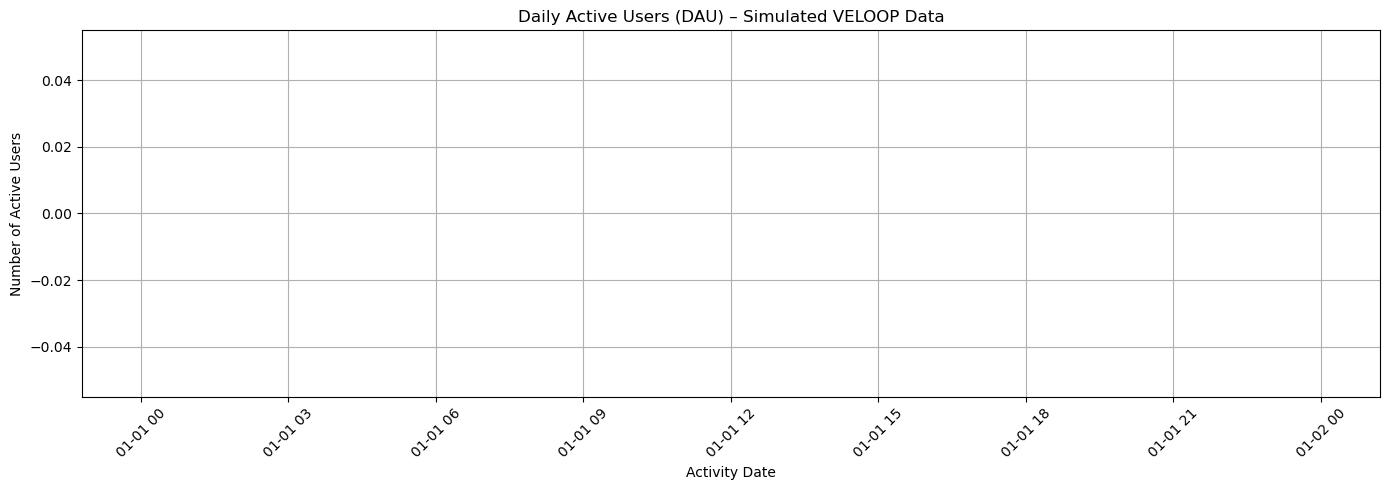

In [154]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(daily_active_users["activity_date"],daily_active_users["DAU"])

plt.title("Daily Active Users (DAU) – Simulated VELOOP Data")
plt.xlabel("Activity Date")
plt.ylabel("Number of Active Users")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [155]:
# Save the result:
daily_active_users.to_excel("VELOOP_E4_Daily_Active_Users.xlsx",index=False)

In [156]:
# E5 – User Retention Analysis.

In [157]:
df_users["registration_datetime"] = pd.to_datetime(df_users["registration_datetime"])

df_daily["activity_date"] = pd.to_datetime(df_daily["activity_date"])

In [158]:
retention_data = df_daily.merge(
    df_users[["user_id", "registration_datetime"]],
    on="user_id",
    how="left"
)

retention_data["days_since_registration"] = (
    retention_data["activity_date"].dt.normalize()
    - retention_data["registration_datetime"].dt.normalize()
).dt.days

retention_data.head()

,user_id,activity_date,session_count,session_duration_minutes,event_count,feature_count,task_count,completed_task_count,reward_activity_count,xp_activity_count,streak_activity,daily_reward_claimed,mission_activity,spin_activity,referral_activity,wallet_activity,active_flag,registration_datetime,days_since_registration
0,VLUSR000001,2026-08-11,1,18.2,17,10,8,2,11,3,Yes,Yes,Yes,No,Yes,Yes,Yes,2026-07-17 15:13:01,25
1,VLUSR000002,2026-08-25,1,4.4,4,4,1,0,2,1,No,No,No,Yes,No,No,Yes,2026-08-22 11:21:00,3
2,VLUSR000002,2026-08-31,1,4.0,5,4,1,0,4,2,Yes,Yes,No,No,No,Yes,Yes,2026-08-22 11:21:00,9
3,VLUSR000002,2026-09-04,1,5.8,5,4,3,0,5,2,Yes,No,Yes,Yes,No,No,Yes,2026-08-22 11:21:00,13
4,VLUSR000002,2026-09-10,1,5.2,5,5,3,1,3,1,No,Yes,Yes,No,No,No,Yes,2026-08-22 11:21:00,19


In [159]:
retention_data["retention_period"] = pd.cut(
    retention_data["days_since_registration"],
    bins=[-1, 1, 7, 30, 60, 90, float("inf")],
    labels=["Day 0-1", "Day 2-7", "Day 8-30",
            "Day 31-60", "Day 61-90", "Day 90+"]
)

retention_summary = (
    retention_data[retention_data["active_flag"] == 1]
    .groupby("retention_period", observed=False)["user_id"]
    .nunique()
    .reset_index(name="Active_Users")
)

retention_summary

,retention_period,Active_Users
0,Day 0-1,0
1,Day 2-7,0
2,Day 8-30,0
3,Day 31-60,0
4,Day 61-90,0
5,Day 90+,0


In [160]:
# E6 – User Engagement by Feature Analysis.

In [161]:
df_events = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="03_Feature_Events")

In [162]:
feature_summary = (
    df_events.groupby("feature_name")
    .agg(
        Total_Events=("event_id", "count"),
        Unique_Users=("user_id", "nunique"),
        Unique_Sessions=("session_id", "nunique")
    )
    .reset_index()
    .sort_values("Total_Events", ascending=False)
)

feature_summary

,feature_name,Total_Events,Unique_Users,Unique_Sessions
14,Watch Ads,3126,836,2412
8,Missions,2780,771,2176
11,Streak Rewards,2734,832,2157
1,CAPTCHA,2733,824,2120
12,Tap & Earn,2654,800,2051
7,Mining Rewards,2616,799,2085
9,Referral,2521,811,2000
2,Daily Reward,2499,835,1963
6,Level System,2427,773,1944
10,Spin the Wheel,2425,763,1909


In [163]:
total_events = df_events["event_id"].count()

feature_summary["Event_Percentage"] = (feature_summary["Total_Events"] / total_events * 100).round(2)

feature_summary

,feature_name,Total_Events,Unique_Users,Unique_Sessions,Event_Percentage
14,Watch Ads,3126,836,2412,8.76
8,Missions,2780,771,2176,7.79
11,Streak Rewards,2734,832,2157,7.66
1,CAPTCHA,2733,824,2120,7.65
12,Tap & Earn,2654,800,2051,7.43
7,Mining Rewards,2616,799,2085,7.33
9,Referral,2521,811,2000,7.06
2,Daily Reward,2499,835,1963,7.00
6,Level System,2427,773,1944,6.80
10,Spin the Wheel,2425,763,1909,6.79


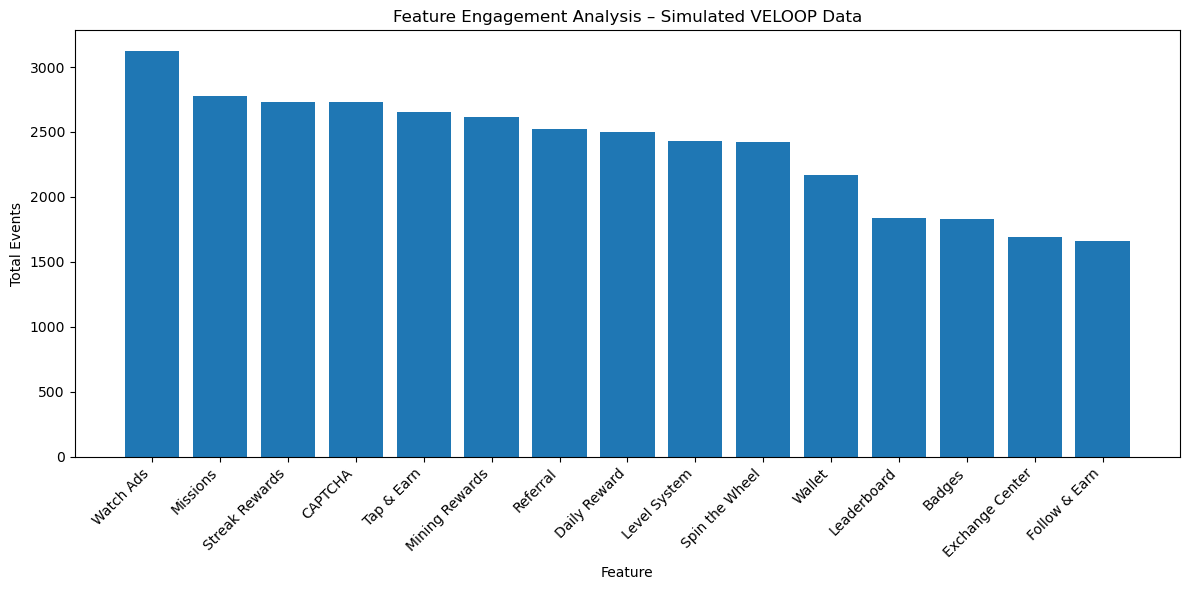

In [164]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(feature_summary["feature_name"],feature_summary["Total_Events"])

plt.title("Feature Engagement Analysis – Simulated VELOOP Data")
plt.xlabel("Feature")
plt.ylabel("Total Events")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [165]:
# Save the Results:
feature_summary.to_excel("VELOOP_E6_Feature_Engagement_Analysis.xlsx",index=False)

In [166]:
# E7 – Referral & Engagement KPI Summary.

In [167]:
referral_engagement_kpis = pd.DataFrame([
    ["Total Registered Users", df_users["user_id"].nunique(), "Users"],
    ["Referral Acquired Users", referral_users, "Users"],
    ["Users with Referral Codes", referral_code_users, "Users"],
    ["Total Sessions", total_sessions, "Sessions"],
    ["Unique Active Session Users", unique_users, "Users"],
    ["Average Session Duration", avg_session_duration, "Minutes"],
    ["Average Events per Session", avg_events_per_session, "Events"],
    ["Average Features per Session", avg_features_per_session, "Features"],
    ["Average Daily Active Users", average_dau, "Users"],
    ["Total Feature Events", df_events["event_id"].count(), "Events"]
], columns=["KPI", "Value", "Unit"])

referral_engagement_kpis

,KPI,Value,Unit
0,Total Registered Users,1000.00,Users
1,Referral Acquired Users,154.00,Users
2,Users with Referral Codes,1000.00,Users
3,Total Sessions,7913.00,Sessions
4,Unique Active Session Users,984.00,Users
5,Average Session Duration,0.86,Minutes
6,Average Events per Session,10.44,Events
7,Average Features per Session,3.22,Features
8,Average Daily Active Users,NaN,Users
9,Total Feature Events,35704.00,Events


In [168]:
referral_engagement_kpis["Data_Status"] = [
    "Available",
    "Available",
    "Available",
    "Available",
    "Available",
    "Available",
    "Available",
    "Available",
    "Available",
    "Available"
]

referral_engagement_kpis

,KPI,Value,Unit,Data_Status
0,Total Registered Users,1000.00,Users,Available
1,Referral Acquired Users,154.00,Users,Available
2,Users with Referral Codes,1000.00,Users,Available
3,Total Sessions,7913.00,Sessions,Available
4,Unique Active Session Users,984.00,Users,Available
5,Average Session Duration,0.86,Minutes,Available
6,Average Events per Session,10.44,Events,Available
7,Average Features per Session,3.22,Features,Available
8,Average Daily Active Users,NaN,Users,Available
9,Total Feature Events,35704.00,Events,Available


In [169]:
#Save the results:
referral_engagement_kpis.to_excel("VELOOP_E7_Referral_Engagement_KPI_Summary.xlsx",index=False)

In [170]:
# F – Production Event Tracking Plan.

In [171]:
df_events = pd.read_excel("VELOOP_Simulated_User_Behavior_1000.xlsx",sheet_name="03_Feature_Events")

In [172]:
print("Total Event Records:", len(df_events))

print("\nAvailable Columns:")
print(df_events.columns.tolist())

print("\nEvent Name Distribution:")
print(df_events["event_name"].value_counts(dropna=False))

Total Event Records: 35704

Available Columns:
['event_id', 'user_id', 'session_id', 'event_datetime', 'feature_name', 'event_name', 'event_status', 'device', 'platform', 'acquisition_source', 'sequence_number', 'reward_related_flag', 'xp_related_flag']

Event Name Distribution:
event_name
wallet_viewed            2172
leaderboard_viewed       1836
exchange_viewed          1690
tap_started              1327
tap_completed            1327
daily_reward_claimed     1281
level_up                 1266
daily_reward_viewed      1218
level_viewed             1161
ad_skipped               1065
ad_completed             1054
ad_started               1007
badge_earned              954
captcha_started           953
streak_claimed            922
streak_broken             919
mining_stopped            915
captcha_completed         896
streak_viewed             893
captcha_failed            884
mining_started            882
badge_viewed              878
referral_created          871
follow_task_complet

In [173]:
event_distribution = (
    df_events.groupby(["feature_name", "event_name"])
    .size()
    .reset_index(name="Event_Count")
    .sort_values("Event_Count", ascending=False)
)

event_distribution.head(20)

,feature_name,event_name,Event_Count
31,Wallet,wallet_viewed,2172
10,Leaderboard,leaderboard_viewed,1836
7,Exchange Center,exchange_viewed,1690
30,Tap & Earn,tap_started,1327
29,Tap & Earn,tap_completed,1327
5,Daily Reward,daily_reward_claimed,1281
11,Level System,level_up,1266
6,Daily Reward,daily_reward_viewed,1218
12,Level System,level_viewed,1161
33,Watch Ads,ad_skipped,1065


In [174]:
print("Event Status Distribution:")

print(df_events["event_status"].value_counts(dropna=False))

Event Status Distribution:
event_status
Started      18628
Success      14428
Abandoned     1764
Failed         884
Name: count, dtype: int64


In [175]:
event_fields = [
    "event_id",
    "user_id",
    "session_id",
    "event_datetime",
    "feature_name",
    "event_name",
    "event_status",
    "device",
    "platform",
    "acquisition_source",
    "sequence_number",
    "reward_related_flag",
    "xp_related_flag"
]

event_field_audit = pd.DataFrame({
    "Field": event_fields,
    "Availability": [
        "Available" if field in df_events.columns else "Not Available"
        for field in event_fields
    ]
})

event_field_audit

,Field,Availability
0,event_id,Available
1,user_id,Available
2,session_id,Available
3,event_datetime,Available
4,feature_name,Available
5,event_name,Available
6,event_status,Available
7,device,Available
8,platform,Available
9,acquisition_source,Available


In [176]:
# F2 – Event Naming Convention & Standards.

In [177]:
event_naming_standards = pd.DataFrame({
    "Standard": [
        "Naming Format",
        "Letter Case",
        "Word Separator",
        "Event Meaning",
        "Event Uniqueness",
        "User Identification",
        "Timestamp",
        "Personal Information"
    ],
    "Rule": [
        "object_action",
        "Lowercase only",
        "Use underscores",
        "Use clear action-based names",
        "One event per user action or system outcome",
        "Include user_id where applicable",
        "Use UTC timestamp",
        "Do not include email, phone, or other personal data"
    ],
    "Example": [
        "task_completed",
        "task_started",
        "reward_credited",
        "withdrawal_requested",
        "Unique event_id",
        "user_id",
        "event_datetime",
        "No personal information in event names"
    ]
})

event_naming_standards

,Standard,Rule,Example
0,Naming Format,object_action,task_completed
1,Letter Case,Lowercase only,task_started
2,Word Separator,Use underscores,reward_credited
3,Event Meaning,Use clear action-based names,withdrawal_requested
4,Event Uniqueness,One event per user action or system outcome,Unique event_id
5,User Identification,Include user_id where applicable,user_id
6,Timestamp,Use UTC timestamp,event_datetime
7,Personal Information,"Do not include email, phone, or other personal...",No personal information in event names


In [178]:
proposed_events = pd.DataFrame({
    "Event_Name": [
        "user_registered",
        "user_logged_in",
        "onboarding_completed",
        "task_viewed",
        "task_started",
        "task_completed",
        "reward_credited",
        "wallet_credited",
        "withdrawal_requested",
        "withdrawal_completed",
        "referral_created",
        "referral_converted"
    ],
    "Feature": [
        "User Account", "User Account", "Onboarding",
        "Task", "Task", "Task", "Rewards", "Wallet",
        "Withdrawal", "Withdrawal", "Referral", "Referral"
    ],
    "Status": ["Proposed"] * 12
})

proposed_events

,Event_Name,Feature,Status
0,user_registered,User Account,Proposed
1,user_logged_in,User Account,Proposed
2,onboarding_completed,Onboarding,Proposed
3,task_viewed,Task,Proposed
4,task_started,Task,Proposed
5,task_completed,Task,Proposed
6,reward_credited,Rewards,Proposed
7,wallet_credited,Wallet,Proposed
8,withdrawal_requested,Withdrawal,Proposed
9,withdrawal_completed,Withdrawal,Proposed


In [179]:
with pd.ExcelWriter("VELOOP_F2_Event_Naming_Standards.xlsx") as writer:
    event_naming_standards.to_excel(
        writer, sheet_name="Naming_Standards", index=False
    )
    proposed_events.to_excel(
        writer, sheet_name="Proposed_Events", index=False
    )

print("F2 Event Naming Standards exported successfully.")

F2 Event Naming Standards exported successfully.


In [180]:
# F3 – Production Event Tracking Catalogue.

In [181]:
event_tracking_catalogue = pd.DataFrame({
    "Event_Name": [
        "user_registered",
        "user_logged_in",
        "onboarding_completed",
        "task_viewed",
        "task_started",
        "task_completed",
        "reward_credited",
        "wallet_credited",
        "withdrawal_requested",
        "withdrawal_completed",
        "referral_created",
        "referral_converted"
    ],

    "Feature": [
        "User Account", "User Account", "Onboarding",
        "Task", "Task", "Task", "Rewards", "Wallet",
        "Withdrawal", "Withdrawal", "Referral", "Referral"
    ],

    "Trigger": [
        "When a new account is created",
        "When a user successfully logs in",
        "When onboarding is completed",
        "When a task detail is opened",
        "When a user starts a task",
        "When a task is submitted as completed",
        "When a reward is successfully issued",
        "When a wallet credit transaction succeeds",
        "When a withdrawal request is submitted",
        "When a withdrawal is successfully processed",
        "When a referral link or code is created",
        "When a referred user meets the conversion criteria"
    ],

    "Required_Properties": [
        "event_id, user_id, event_datetime",
        "event_id, user_id, session_id, event_datetime",
        "event_id, user_id, event_datetime",
        "event_id, user_id, task_id, event_datetime",
        "event_id, user_id, task_id, event_datetime",
        "event_id, user_id, task_id, event_datetime",
        "event_id, user_id, reward_id, event_datetime",
        "event_id, user_id, transaction_id, amount, event_datetime",
        "event_id, user_id, withdrawal_id, amount, event_datetime",
        "event_id, user_id, withdrawal_id, amount, event_datetime",
        "event_id, user_id, referral_code, event_datetime",
        "event_id, user_id, referral_code, referred_user_id, event_datetime"
    ],

    "Validation_Rule": [
        "Unique event_id and valid user_id",
        "Valid user_id and session_id",
        "Valid user_id and completion timestamp",
        "Valid task_id and user_id",
        "Task must have a valid start timestamp",
        "Completion must occur after task start",
        "Reward must have successful issuance status",
        "Amount must be positive and transaction_id unique",
        "Amount must be positive and withdrawal_id unique",
        "Withdrawal must have successful processing status",
        "Referral code must be unique where required",
        "Referred user must be linked to a valid referral"
    ],

    "Implementation_Status": ["Proposed"] * 12
})

event_tracking_catalogue

,Event_Name,Feature,Trigger,Required_Properties,Validation_Rule,Implementation_Status
0,user_registered,User Account,When a new account is created,"event_id, user_id, event_datetime",Unique event_id and valid user_id,Proposed
1,user_logged_in,User Account,When a user successfully logs in,"event_id, user_id, session_id, event_datetime",Valid user_id and session_id,Proposed
2,onboarding_completed,Onboarding,When onboarding is completed,"event_id, user_id, event_datetime",Valid user_id and completion timestamp,Proposed
3,task_viewed,Task,When a task detail is opened,"event_id, user_id, task_id, event_datetime",Valid task_id and user_id,Proposed
4,task_started,Task,When a user starts a task,"event_id, user_id, task_id, event_datetime",Task must have a valid start timestamp,Proposed
5,task_completed,Task,When a task is submitted as completed,"event_id, user_id, task_id, event_datetime",Completion must occur after task start,Proposed
6,reward_credited,Rewards,When a reward is successfully issued,"event_id, user_id, reward_id, event_datetime",Reward must have successful issuance status,Proposed
7,wallet_credited,Wallet,When a wallet credit transaction succeeds,"event_id, user_id, transaction_id, amount, eve...",Amount must be positive and transaction_id unique,Proposed
8,withdrawal_requested,Withdrawal,When a withdrawal request is submitted,"event_id, user_id, withdrawal_id, amount, even...",Amount must be positive and withdrawal_id unique,Proposed
9,withdrawal_completed,Withdrawal,When a withdrawal is successfully processed,"event_id, user_id, withdrawal_id, amount, even...",Withdrawal must have successful processing status,Proposed


In [182]:
print("Total Proposed Events:", len(event_tracking_catalogue))

print("\nEvents by Feature:")
print(event_tracking_catalogue["Feature"].value_counts())

print("\nImplementation Status:")
print(event_tracking_catalogue["Implementation_Status"].value_counts())

Total Proposed Events: 12

Events by Feature:
Feature
Task            3
User Account    2
Withdrawal      2
Referral        2
Onboarding      1
Rewards         1
Wallet          1
Name: count, dtype: int64

Implementation Status:
Implementation_Status
Proposed    12
Name: count, dtype: int64


In [183]:
# Export the catalogue:-
event_tracking_catalogue.to_excel("VELOOP_F3_Production_Event_Tracking_Catalogue.xlsx",index=False)

print("F3 Event Tracking Catalogue exported successfully.")

F3 Event Tracking Catalogue exported successfully.


In [184]:
# F4 – Event Properties, Data Types & Validation Rules.

In [185]:
event_properties = pd.DataFrame({
    "Property": [
        "event_id",
        "user_id",
        "session_id",
        "event_datetime",
        "event_name",
        "feature_name",
        "task_id",
        "reward_id",
        "transaction_id",
        "withdrawal_id",
        "referral_code",
        "amount",
        "event_status",
        "device",
        "platform"
    ],

    "Data_Type": [
        "String", "String", "String", "Datetime",
        "String", "String", "String", "String",
        "String", "String", "String", "Decimal",
        "String", "String", "String"
    ],

    "Purpose": [
        "Unique event identification",
        "Identify the user",
        "Identify the user session",
        "Record when the event occurred",
        "Identify the action performed",
        "Identify the product feature",
        "Identify the related task",
        "Identify the issued reward",
        "Identify the wallet transaction",
        "Identify the withdrawal request",
        "Track referral attribution",
        "Record transaction value",
        "Record event outcome",
        "Record device type",
        "Record operating platform"
    ],

    "Validation_Rule": [
        "Must be unique and non-null",
        "Must match an existing user",
        "Must match a valid session where applicable",
        "Must be a valid UTC timestamp",
        "Must follow object_action naming convention",
        "Must use an approved feature name",
        "Required for task events",
        "Required for reward events",
        "Required for wallet transactions",
        "Required for withdrawal events",
        "Required for referral events",
        "Must be positive for credit or withdrawal amounts",
        "Must use an approved status",
        "Must use an approved device value",
        "Must use an approved platform value"
    ],

    "Required": [
        "Yes", "Yes", "Conditional", "Yes",
        "Yes", "Yes", "Conditional", "Conditional",
        "Conditional", "Conditional", "Conditional",
        "Conditional", "Yes", "Conditional", "Conditional"
    ],

    "Status": ["Proposed"] * 15
})

event_properties

,Property,Data_Type,Purpose,Validation_Rule,Required,Status
0,event_id,String,Unique event identification,Must be unique and non-null,Yes,Proposed
1,user_id,String,Identify the user,Must match an existing user,Yes,Proposed
2,session_id,String,Identify the user session,Must match a valid session where applicable,Conditional,Proposed
3,event_datetime,Datetime,Record when the event occurred,Must be a valid UTC timestamp,Yes,Proposed
4,event_name,String,Identify the action performed,Must follow object_action naming convention,Yes,Proposed
5,feature_name,String,Identify the product feature,Must use an approved feature name,Yes,Proposed
6,task_id,String,Identify the related task,Required for task events,Conditional,Proposed
7,reward_id,String,Identify the issued reward,Required for reward events,Conditional,Proposed
8,transaction_id,String,Identify the wallet transaction,Required for wallet transactions,Conditional,Proposed
9,withdrawal_id,String,Identify the withdrawal request,Required for withdrawal events,Conditional,Proposed


In [186]:
print("Total Properties:", len(event_properties))

print("\nRequired Properties:")
print(event_properties["Required"].value_counts())

print("\nProperties by Data Type:")
print(event_properties["Data_Type"].value_counts())

Total Properties: 15

Required Properties:
Required
Conditional    9
Yes            6
Name: count, dtype: int64

Properties by Data Type:
Data_Type
String      13
Datetime     1
Decimal      1
Name: count, dtype: int64


In [187]:
# Export the specification:-
event_properties.to_excel("VELOOP_F4_Event_Properties_Validation.xlsx",index=False)

print("F4 Event Properties Specification exported successfully.")

F4 Event Properties Specification exported successfully.


In [188]:
# F5 – Event Tracking Coverage & Implementation Priority.

In [189]:
# Get the event names found in the simulated dataset
existing_event_names = set(df_events["event_name"].dropna().str.lower().str.strip())

# Compare proposed events with existing event names
event_coverage = event_tracking_catalogue[["Event_Name", "Feature"]].copy()

event_coverage["Dataset_Status"] = event_coverage["Event_Name"].apply(lambda x: "Found in simulated data"
                                                                      if x in existing_event_names
    
                                                                      else "Not found in simulated data"
)

event_coverage["Production_Status"] = "To Be Verified"

event_coverage

,Event_Name,Feature,Dataset_Status,Production_Status
0,user_registered,User Account,Not found in simulated data,To Be Verified
1,user_logged_in,User Account,Not found in simulated data,To Be Verified
2,onboarding_completed,Onboarding,Not found in simulated data,To Be Verified
3,task_viewed,Task,Not found in simulated data,To Be Verified
4,task_started,Task,Not found in simulated data,To Be Verified
5,task_completed,Task,Not found in simulated data,To Be Verified
6,reward_credited,Rewards,Not found in simulated data,To Be Verified
7,wallet_credited,Wallet,Not found in simulated data,To Be Verified
8,withdrawal_requested,Withdrawal,Not found in simulated data,To Be Verified
9,withdrawal_completed,Withdrawal,Not found in simulated data,To Be Verified


In [190]:
priority_mapping = {
    "user_registered": "High",
    "user_logged_in": "High",
    "onboarding_completed": "High",
    "task_viewed": "High",
    "task_started": "High",
    "task_completed": "High",
    "reward_credited": "High",
    "wallet_credited": "High",
    "withdrawal_requested": "High",
    "withdrawal_completed": "High",
    "referral_created": "Medium",
    "referral_converted": "Medium"
}

event_coverage["Priority"] = (
    event_coverage["Event_Name"].map(priority_mapping)
)

event_coverage

,Event_Name,Feature,Dataset_Status,Production_Status,Priority
0,user_registered,User Account,Not found in simulated data,To Be Verified,High
1,user_logged_in,User Account,Not found in simulated data,To Be Verified,High
2,onboarding_completed,Onboarding,Not found in simulated data,To Be Verified,High
3,task_viewed,Task,Not found in simulated data,To Be Verified,High
4,task_started,Task,Not found in simulated data,To Be Verified,High
5,task_completed,Task,Not found in simulated data,To Be Verified,High
6,reward_credited,Rewards,Not found in simulated data,To Be Verified,High
7,wallet_credited,Wallet,Not found in simulated data,To Be Verified,High
8,withdrawal_requested,Withdrawal,Not found in simulated data,To Be Verified,High
9,withdrawal_completed,Withdrawal,Not found in simulated data,To Be Verified,High


In [191]:
print("Event Coverage Summary:")
print(event_coverage["Dataset_Status"].value_counts())

print("\nImplementation Priority:")
print(event_coverage["Priority"].value_counts())

Event Coverage Summary:
Dataset_Status
Not found in simulated data    11
Found in simulated data         1
Name: count, dtype: int64

Implementation Priority:
Priority
High      10
Medium     2
Name: count, dtype: int64


In [192]:
event_coverage.to_excel("VELOOP_F5_Event_Tracking_Coverage.xlsx",index=False)

print("F5 Event Tracking Coverage exported successfully.")

F5 Event Tracking Coverage exported successfully.


In [193]:
# G – Data Dictionary.

In [198]:
workbooks = {
    "Rewards_Data": "VELoop_Rewards_Data_01.xlsx",
    "User_Behavior": "VELOOP_Simulated_User_Behavior_1000.xlsx"
}

print("Workbooks loaded for field inventory:")
for name, file in workbooks.items():
    print(name, ":", file)

Workbooks loaded for field inventory:
Rewards_Data : VELoop_Rewards_Data_01.xlsx
User_Behavior : VELOOP_Simulated_User_Behavior_1000.xlsx


In [199]:
field_inventory = []

for workbook_name, file in workbooks.items():

    excel_file = pd.ExcelFile(file)

    for sheet in excel_file.sheet_names:

        temp_df = pd.read_excel(file, sheet_name=sheet)

        for column in temp_df.columns:

            field_inventory.append({
                "Workbook": workbook_name,
                "Sheet_Name": sheet,
                "Field_Name": column,
                "Data_Type": str(temp_df[column].dtype),
                "Non_Null_Count": temp_df[column].notna().sum(),
                "Null_Count": temp_df[column].isna().sum()
            })

field_inventory_df = pd.DataFrame(field_inventory)

field_inventory_df.head(20)

,Workbook,Sheet_Name,Field_Name,Data_Type,Non_Null_Count,Null_Count
0,Rewards_Data,Users_1000_Clean,user_id,object,1000,0
1,Rewards_Data,Users_1000_Clean,full_name,object,1000,0
2,Rewards_Data,Users_1000_Clean,email,object,1000,0
3,Rewards_Data,Users_1000_Clean,age,int64,1000,0
4,Rewards_Data,Users_1000_Clean,gender,object,1000,0
5,Rewards_Data,Users_1000_Clean,state,object,1000,0
6,Rewards_Data,Users_1000_Clean,city,object,1000,0
7,Rewards_Data,Users_1000_Clean,registration_datetime,datetime64[ns],1000,0
8,Rewards_Data,Users_1000_Clean,acquisition_source,object,1000,0
9,Rewards_Data,Users_1000_Clean,referral_source_detail,object,119,881


In [201]:
print("Total Field Entries:", len(field_inventory_df))

print("Unique Field Names:",field_inventory_df["Field_Name"].nunique())

print("\nFields by Workbook:")
print(field_inventory_df["Workbook"].value_counts())

print("\nFields by Sheet:")
print(field_inventory_df.groupby(["Workbook", "Sheet_Name"]).size()
)

Total Field Entries: 169
Unique Field Names: 92

Fields by Workbook:
Workbook
User_Behavior    105
Rewards_Data      64
Name: count, dtype: int64

Fields by Sheet:
Workbook       Sheet_Name                 
Rewards_Data   Data_Dictionary                 5
               README_Data_Status              2
               Synthetic_Summary               2
               Users_1000_Clean               27
               Users_Messy_Audit              28
User_Behavior  01_Users_1000                  16
               02_Sessions                    12
               03_Feature_Events              13
               04_Daily_Activity              17
               05_Task_Activity               12
               06_Milestones                   6
               07_Feature_Usage                7
               08_Data_Dictionary              7
               09_README_Status                2
               10_Event_Data_Quality_Audit    13
dtype: int64


In [202]:
field_inventory_df.to_excel("VELOOP_G1_Field_Inventory.xlsx",index=False)

print("G1 Field Inventory exported successfully.")

G1 Field Inventory exported successfully.


In [203]:
# G2 – Field Definitions, Business Meaning & Analytical Purpose.

In [204]:
data_dictionary = field_inventory_df.copy()

data_dictionary["Business_Definition"] = (data_dictionary["Field_Name"].str.replace("_", " ").str.title())

data_dictionary["Analytical_Purpose"] = ("Used for data analysis, reporting and KPI measurement")

data_dictionary["Sensitivity"] = "To Be Reviewed"

data_dictionary["Required_Status"] = "To Be Confirmed"

data_dictionary["Implementation_Status"] = "Available in simulated dataset"

data_dictionary.head(20)

,Workbook,Sheet_Name,Field_Name,Data_Type,Non_Null_Count,Null_Count,Business_Definition,Analytical_Purpose,Sensitivity,Required_Status,Implementation_Status
0,Rewards_Data,Users_1000_Clean,user_id,object,1000,0,User Id,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
1,Rewards_Data,Users_1000_Clean,full_name,object,1000,0,Full Name,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
2,Rewards_Data,Users_1000_Clean,email,object,1000,0,Email,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
3,Rewards_Data,Users_1000_Clean,age,int64,1000,0,Age,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
4,Rewards_Data,Users_1000_Clean,gender,object,1000,0,Gender,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
5,Rewards_Data,Users_1000_Clean,state,object,1000,0,State,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
6,Rewards_Data,Users_1000_Clean,city,object,1000,0,City,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
7,Rewards_Data,Users_1000_Clean,registration_datetime,datetime64[ns],1000,0,Registration Datetime,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
8,Rewards_Data,Users_1000_Clean,acquisition_source,object,1000,0,Acquisition Source,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
9,Rewards_Data,Users_1000_Clean,referral_source_detail,object,119,881,Referral Source Detail,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset


In [205]:
field_definitions = {
    "user_id": "Unique identifier assigned to a user",
    "event_id": "Unique identifier assigned to an event",
    "session_id": "Unique identifier assigned to a user session",
    "full_name": "Full name associated with a user account",
    "email": "Email address associated with a user account",
    "age": "Age of the user in years",
    "registration_datetime": "Date and time when the user registered",
    "last_login_datetime": "Date and time of the user's last login",
    "event_datetime": "Date and time when an event occurred",
    "event_name": "Name of the recorded user or system event",
    "feature_name": "Product feature associated with an event",
    "task_id": "Identifier of the task associated with an activity",
    "task_status": "Current recorded status of a task activity",
    "reward_status": "Recorded status of the associated reward",
    "xp_balance": "Recorded experience point balance",
    "referral_code": "Code associated with a user's referral activity",
    "account_status": "Recorded account lifecycle status",
    "platform": "Platform used to access the product",
    "device": "Device associated with a recorded activity",
    "wallet_activity": "Indicator of recorded wallet-related activity"
}

data_dictionary["Business_Definition"] = (
    data_dictionary["Field_Name"]
    .map(field_definitions)
    .fillna(data_dictionary["Business_Definition"])
)

data_dictionary.head(25)

,Workbook,Sheet_Name,Field_Name,Data_Type,Non_Null_Count,Null_Count,Business_Definition,Analytical_Purpose,Sensitivity,Required_Status,Implementation_Status
0,Rewards_Data,Users_1000_Clean,user_id,object,1000,0,Unique identifier assigned to a user,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
1,Rewards_Data,Users_1000_Clean,full_name,object,1000,0,Full name associated with a user account,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
2,Rewards_Data,Users_1000_Clean,email,object,1000,0,Email address associated with a user account,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
3,Rewards_Data,Users_1000_Clean,age,int64,1000,0,Age of the user in years,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
4,Rewards_Data,Users_1000_Clean,gender,object,1000,0,Gender,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
5,Rewards_Data,Users_1000_Clean,state,object,1000,0,State,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
6,Rewards_Data,Users_1000_Clean,city,object,1000,0,City,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
7,Rewards_Data,Users_1000_Clean,registration_datetime,datetime64[ns],1000,0,Date and time when the user registered,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
8,Rewards_Data,Users_1000_Clean,acquisition_source,object,1000,0,Acquisition Source,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
9,Rewards_Data,Users_1000_Clean,referral_source_detail,object,119,881,Referral Source Detail,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset


In [206]:
purpose_mapping = {
    "user_id": "User identification and user-level analysis",
    "event_id": "Event uniqueness and event-level analysis",
    "session_id": "Session tracking and engagement analysis",
    "registration_datetime": "Registration trends and cohort analysis",
    "last_login_datetime": "User activity and recency analysis",
    "event_datetime": "Event trends and time-based analysis",
    "event_name": "Feature usage and event funnel analysis",
    "task_status": "Task completion and failure analysis",
    "reward_status": "Reward issuance status analysis",
    "xp_balance": "User progression and reward engagement",
    "referral_code": "Referral acquisition analysis",
    "platform": "Platform performance comparison",
    "device": "Device usage analysis"
}

data_dictionary["Analytical_Purpose"] = (
    data_dictionary["Field_Name"]
    .map(purpose_mapping)
    .fillna(data_dictionary["Analytical_Purpose"])
)

data_dictionary.head(25)

,Workbook,Sheet_Name,Field_Name,Data_Type,Non_Null_Count,Null_Count,Business_Definition,Analytical_Purpose,Sensitivity,Required_Status,Implementation_Status
0,Rewards_Data,Users_1000_Clean,user_id,object,1000,0,Unique identifier assigned to a user,User identification and user-level analysis,To Be Reviewed,To Be Confirmed,Available in simulated dataset
1,Rewards_Data,Users_1000_Clean,full_name,object,1000,0,Full name associated with a user account,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
2,Rewards_Data,Users_1000_Clean,email,object,1000,0,Email address associated with a user account,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
3,Rewards_Data,Users_1000_Clean,age,int64,1000,0,Age of the user in years,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
4,Rewards_Data,Users_1000_Clean,gender,object,1000,0,Gender,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
5,Rewards_Data,Users_1000_Clean,state,object,1000,0,State,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
6,Rewards_Data,Users_1000_Clean,city,object,1000,0,City,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
7,Rewards_Data,Users_1000_Clean,registration_datetime,datetime64[ns],1000,0,Date and time when the user registered,Registration trends and cohort analysis,To Be Reviewed,To Be Confirmed,Available in simulated dataset
8,Rewards_Data,Users_1000_Clean,acquisition_source,object,1000,0,Acquisition Source,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset
9,Rewards_Data,Users_1000_Clean,referral_source_detail,object,119,881,Referral Source Detail,"Used for data analysis, reporting and KPI meas...",To Be Reviewed,To Be Confirmed,Available in simulated dataset


In [207]:
data_dictionary.to_excel("VELOOP_G2_Data_Dictionary_Definitions.xlsx",index=False)

print("G2 Data Dictionary exported successfully.")

G2 Data Dictionary exported successfully.


In [208]:
# G3 – Data Types, Required Fields & Validation Rules.

In [214]:
validation_mapping = {
    "user_id": "Must be unique and non-null in the Users table",
    "event_id": "Must be unique and non-null in the Events table",
    "session_id": "Must identify a valid session",
    "email": "Must follow a valid email format",
    "age": "Must be a valid numeric age",
    "registration_datetime": "Must contain a valid registration timestamp",
    "last_login_datetime": "Must not be earlier than registration",
    "event_datetime": "Must contain a valid event timestamp",
    "event_name": "Must follow the approved event naming convention",
    "task_status": "Must use an approved task status",
    "reward_status": "Must use an approved reward status",
    "xp_balance": "Must be zero or a positive number",
    "referral_code": "Must follow the approved referral code format",
    "platform": "Must use an approved platform value"
}

data_dictionary["Validation_Rule"] = (
    data_dictionary["Field_Name"]
    .map(validation_mapping)
    .fillna("Define validation rule with product and engineering teams"))

In [215]:
example_values = []

for _, row in data_dictionary.iterrows():

    workbook_name = row["Workbook"]
    sheet_name = row["Sheet_Name"]
    field_name = row["Field_Name"]

    file = workbooks[workbook_name]

    temp_df = pd.read_excel(file, sheet_name=sheet_name)

    values = temp_df[field_name].dropna()

    if len(values) > 0:
        example = str(values.iloc[0])
    else:
        example = "No non-null example available"

    example_values.append(example)

data_dictionary["Example_Value"] = example_values

data_dictionary[["Field_Name", "Data_Type", "Example_Value", "Validation_Rule"]].head(20)

,Field_Name,Data_Type,Example_Value,Validation_Rule
0,user_id,object,VLUSR000001,Must be unique and non-null in the Users table
1,full_name,object,Sanjay Singh,Define validation rule with product and engine...
2,email,object,sanjay.singh1@gmail.com,Must follow a valid email format
3,age,int64,35,Must be a valid numeric age
4,gender,object,Male,Define validation rule with product and engine...
5,state,object,Odisha,Define validation rule with product and engine...
6,city,object,Bhubaneswar,Define validation rule with product and engine...
7,registration_datetime,datetime64[ns],2026-06-10 07:14:00,Must contain a valid registration timestamp
8,acquisition_source,object,Organic Search,Define validation rule with product and engine...
9,referral_source_detail,object,Friend/Family,Define validation rule with product and engine...


In [212]:
required_fields = [
    "user_id",
    "event_id",
    "session_id",
    "registration_datetime",
    "event_datetime"
]

data_dictionary["Required_Status"] = (
    data_dictionary["Field_Name"].apply(
        lambda x: "Candidate Required"
        if x in required_fields
        else "Conditional / Optional"
    )
)

print(data_dictionary["Required_Status"].value_counts())

Required_Status
Conditional / Optional    148
Candidate Required         21
Name: count, dtype: int64


In [213]:
data_dictionary.to_excel("VELOOP_G3_Data_Dictionary_Validation.xlsx",index=False)

print("G3 Data Dictionary Validation exported successfully.")

G3 Data Dictionary Validation exported successfully.


In [ ]:
# G4 – Data Sensitivity, Source & Ownership.

In [ ]:
sensitive_fields = [
    "full_name",
    "email",
    "phone",
    "address",
    "date_of_birth"
]

data_dictionary["Sensitivity"] = (
    data_dictionary["Field_Name"].apply(
        lambda x: "Personal Data"
        if x.lower() in sensitive_fields
        else "Non-Personal / Review Required"
    )
)

data_dictionary["Sensitivity"].value_counts()

In [ ]:
data_dictionary["Source_System"] = (
    data_dictionary["Workbook"] + " / " +
    data_dictionary["Sheet_Name"])

data_dictionary[["Field_Name", "Source_System"]].head(20)

In [ ]:
ownership_mapping = {
    "user_id": "User Account Team",
    "full_name": "User Account Team",
    "email": "User Account Team",
    "registration_datetime": "User Account Team",
    "last_login_datetime": "Authentication Team",
    "session_id": "Product Analytics Team",
    "event_id": "Product Analytics Team",
    "event_name": "Product Analytics Team",
    "feature_name": "Product Team",
    "task_id": "Task Management Team",
    "task_status": "Task Management Team",
    "reward_status": "Rewards Team",
    "wallet_activity": "Wallet Team",
    "referral_code": "Referral Team"
}

data_dictionary["Proposed_Owner"] = (
    data_dictionary["Field_Name"]
    .map(ownership_mapping)
    .fillna("To Be Assigned")
)

data_dictionary[
    ["Field_Name", "Proposed_Owner"]
].head(25)

In [ ]:
print("Total Dictionary Entries:", len(data_dictionary))

print("\nSensitivity Classification:")
print(data_dictionary["Sensitivity"].value_counts())

print("\nOwnership Classification:")
print(data_dictionary["Proposed_Owner"].value_counts())

print("\nFields Without Assigned Ownership:")
print(
    data_dictionary.loc[
        data_dictionary["Proposed_Owner"] == "To Be Assigned",
        "Field_Name"
    ].unique()
)

In [ ]:
data_dictionary.to_excel(
    "VELOOP_G4_Data_Sensitivity_Source_Ownership.xlsx",
    index=False
)

print("G4 Data Sensitivity and Ownership exported successfully.")

In [ ]:
# G5 – Final Data Dictionary Quality Check (75+ Fields).

In [ ]:
print("Total Field Entries:", len(data_dictionary))

print(
    "Unique Field Names:",
    data_dictionary["Field_Name"].nunique()
)

print(
    "Unique Source Sheets:",
    data_dictionary[["Workbook", "Sheet_Name"]]
    .drop_duplicates()
    .shape[0]
)

In [ ]:
print("Missing Business Definitions:",
      data_dictionary["Business_Definition"].isna().sum())

print("Missing Analytical Purposes:",
      data_dictionary["Analytical_Purpose"].isna().sum())

print("Missing Validation Rules:",
      data_dictionary["Validation_Rule"].isna().sum())

print("Missing Data Types:",
      data_dictionary["Data_Type"].isna().sum())

In [ ]:
review_fields = data_dictionary[
    (data_dictionary["Proposed_Owner"] == "To Be Assigned") |
    (data_dictionary["Required_Status"] == "Conditional / Optional") |
    (data_dictionary["Validation_Rule"] ==
     "Define validation rule with product and engineering teams")
]

print("Fields Requiring Further Review:", len(review_fields))

review_fields[
    ["Field_Name", "Sheet_Name", "Proposed_Owner",
     "Required_Status", "Validation_Rule"]
].head(20)

In [ ]:
dictionary_summary = pd.DataFrame({
    "Quality_Check": [
        "Total Field Entries",
        "Unique Field Names",
        "Missing Definitions",
        "Missing Analytical Purposes",
        "Missing Validation Rules",
        "Fields Requiring Review"
    ],
    "Result": [
        len(data_dictionary),
        data_dictionary["Field_Name"].nunique(),
        data_dictionary["Business_Definition"].isna().sum(),
        data_dictionary["Analytical_Purpose"].isna().sum(),
        data_dictionary["Validation_Rule"].isna().sum(),
        len(review_fields)
    ]
})

dictionary_summary

In [ ]:
with pd.ExcelWriter("VELOOP_G5_Final_Data_Dictionary.xlsx") as writer:
    data_dictionary.to_excel(
        writer, sheet_name="Data_Dictionary", index=False
    )
    dictionary_summary.to_excel(
        writer, sheet_name="Quality_Summary", index=False
    )
    review_fields.to_excel(
        writer, sheet_name="Fields_To_Review", index=False
    )

print("G5 Final Data Dictionary exported successfully.")

In [ ]:
# H – Logical Data Model & Entity Relationships.

#H1 – Identify the main entities

In [ ]:
file = "VELOOP_Simulated_User_Behavior_1000(1).xlsx"

df_users = pd.read_excel(file, sheet_name="01_Users_1000")
df_sessions = pd.read_excel(file, sheet_name="02_Sessions")
df_events = pd.read_excel(file, sheet_name="03_Feature_Events")
df_daily = pd.read_excel(file, sheet_name="04_Daily_Activity")
df_tasks = pd.read_excel(file, sheet_name="05_Task_Activity")
df_milestones = pd.read_excel(file, sheet_name="06_Milestones")

print("All six entity datasets loaded successfully.")

In [ ]:
entity_inventory = pd.DataFrame({
    "Entity": [
        "Users",
        "Sessions",
        "Feature Events",
        "Daily Activity",
        "Task Activity",
        "Milestones"
    ],
    "Primary_Key_Candidate": [
        "user_id",
        "session_id",
        "event_id",
        "user_id + activity_date",
        "activity_id",
        "user_id + milestone_type + milestone_datetime"
    ],
    "Foreign_Key_Candidate": [
        "None",
        "user_id",
        "user_id, session_id",
        "user_id",
        "user_id, session_id",
        "user_id, session_id"
    ],
    "Row_Count": [
        len(df_users),
        len(df_sessions),
        len(df_events),
        len(df_daily),
        len(df_tasks),
        len(df_milestones)
    ]
})

entity_inventory

In [ ]:
key_checks = {
    "Users": (df_users, ["user_id"]),
    "Sessions": (df_sessions, ["session_id"]),
    "Feature Events": (df_events, ["event_id"]),
    "Daily Activity": (df_daily, ["user_id", "activity_date"]),
    "Task Activity": (df_tasks, ["activity_id"]),
    "Milestones": (
        df_milestones,
        ["user_id", "milestone_type", "milestone_datetime"]
    )
}

for entity, (data, keys) in key_checks.items():

    duplicate_count = data.duplicated(subset=keys).sum()
    missing_count = data[keys].isna().any(axis=1).sum()

    print(f"\n{entity}")
    print("Candidate key:", keys)
    print("Duplicate key rows:", duplicate_count)
    print("Rows with missing key values:", missing_count)

In [ ]:
with pd.ExcelWriter("VELOOP_H1_Entity_Inventory.xlsx") as writer:
    entity_inventory.to_excel(
        writer, sheet_name="Entity_Inventory", index=False
    )

print("H1 Entity Inventory exported successfully.")

In [ ]:
# H2 – Primary Key & Foreign Key Relationship Validation.

In [ ]:
user_ids = set(df_users["user_id"].dropna())

datasets = {
    "Sessions": df_sessions,
    "Feature Events": df_events,
    "Daily Activity": df_daily,
    "Task Activity": df_tasks,
    "Milestones": df_milestones
}

for name, data in datasets.items():

    valid_count = data["user_id"].isin(user_ids).sum()
    orphan_count = (~data["user_id"].isin(user_ids)).sum()

    print(f"\n{name}")
    print("Total Records:", len(data))
    print("Valid User References:", valid_count)
    print("Orphan User References:", orphan_count)

In [ ]:
session_ids = set(df_sessions["session_id"].dropna())

for name, data in {
    "Feature Events": df_events,
    "Task Activity": df_tasks,
    "Milestones": df_milestones
}.items():

    valid_count = data["session_id"].isin(session_ids).sum()
    orphan_count = (~data["session_id"].isin(session_ids)).sum()

    print(f"\n{name}")
    print("Valid Session References:", valid_count)
    print("Orphan Session References:", orphan_count)

In [ ]:
session_user_map = df_sessions[
    ["session_id", "user_id"]
].drop_duplicates()

for name, data in {
    "Feature Events": df_events,
    "Task Activity": df_tasks,
    "Milestones": df_milestones
}.items():

    merged = data.merge(
        session_user_map,
        on="session_id",
        how="left",
        suffixes=("_record", "_session")
    )

    mismatch_count = (
        merged["user_id_record"] != merged["user_id_session"]
    ).sum()

    print(f"\n{name}")
    print("User-Session Mismatches:", mismatch_count)

In [ ]:
relationship_results = []

for name, data in datasets.items():

    orphan_count = (~data["user_id"].isin(user_ids)).sum()

    relationship_results.append({
        "Entity": name,
        "Parent_Entity": "Users",
        "Relationship_Key": "user_id",
        "Total_Records": len(data),
        "Orphan_Records": orphan_count
    })

relationship_audit = pd.DataFrame(relationship_results)

relationship_audit.to_excel(
    "VELOOP_H2_Relationship_Validation.xlsx",
    index=False
)

relationship_audit

In [ ]:
# H3 – Build the Logical Entity Relationship Diagram (ERD).

In [ ]:
erd_relationships = pd.DataFrame({
    "Parent_Entity": [
        "Users", "Users", "Sessions", "Users",
        "Users", "Sessions", "Users", "Sessions"
    ],
    "Child_Entity": [
        "Sessions", "Feature Events", "Feature Events",
        "Daily Activity", "Task Activity", "Task Activity",
        "Milestones", "Milestones"
    ],
    "Relationship": ["One-to-Many"] * 8,
    "Join_Key": [
        "user_id", "user_id", "session_id", "user_id",
        "user_id", "session_id", "user_id", "session_id"
    ],
    "Status": ["To Be Validated"] * 8
})

erd_relationships

In [ ]:
with pd.ExcelWriter("VELOOP_H3_ERD_Documentation.xlsx") as writer:
    erd_relationships.to_excel(
        writer, sheet_name="Relationships", index=False
    )
    entity_inventory.to_excel(
        writer, sheet_name="Entities", index=False
    )

print("H3 ERD Documentation exported successfully.")

In [ ]:
# H4 – Entity Relationship Integrity & Cardinality Checks.

In [ ]:
relationship_counts = pd.DataFrame({
    "Entity": [
        "Users",
        "Sessions",
        "Feature Events",
        "Daily Activity",
        "Task Activity",
        "Milestones"
    ],
    "Total_Records": [
        len(df_users),
        len(df_sessions),
        len(df_events),
        len(df_daily),
        len(df_tasks),
        len(df_milestones)
    ],
    "Unique_Users": [
        df_users["user_id"].nunique(),
        df_sessions["user_id"].nunique(),
        df_events["user_id"].nunique(),
        df_daily["user_id"].nunique(),
        df_tasks["user_id"].nunique(),
        df_milestones["user_id"].nunique()
    ]
})

relationship_counts

In [ ]:
cardinality_results = []

for name, data in datasets.items():

    counts = data.groupby("user_id").size()

    cardinality_results.append({
        "Child_Entity": name,
        "Users_With_Records": counts.count(),
        "Users_With_Multiple_Records": (counts > 1).sum(),
        "Maximum_Records_Per_User": counts.max()
    })

cardinality_audit = pd.DataFrame(cardinality_results)

cardinality_audit

In [ ]:
print("Total Session Records:", len(df_sessions))

print(
    "Unique Session IDs:",
    df_sessions["session_id"].nunique()
)

print(
    "Duplicate Session IDs:",
    df_sessions["session_id"].duplicated().sum()
)

print(
    "Sessions Linked to Multiple Users:",
    df_sessions.groupby("session_id")["user_id"].nunique()
    .gt(1).sum()
)

In [ ]:
print(
    "Daily Activity Duplicate Composite Keys:",
    df_daily.duplicated(
        subset=["user_id", "activity_date"]
    ).sum()
)

print(
    "Milestone Duplicate Composite Keys:",
    df_milestones.duplicated(
        subset=[
            "user_id",
            "milestone_type",
            "milestone_datetime"
        ]
    ).sum()
)

In [ ]:
with pd.ExcelWriter("VELOOP_H4_Cardinality_Audit.xlsx") as writer:

    relationship_counts.to_excel(
        writer, sheet_name="Relationship_Counts", index=False
    )

    cardinality_audit.to_excel(
        writer, sheet_name="Cardinality_Audit", index=False
    )

print("H4 Cardinality Audit exported successfully.")

In [ ]:
# H5: Final Logical Data Model Review.

In [ ]:
logical_data_model = pd.DataFrame({
    "Entity": [
        "Users",
        "Sessions",
        "Feature Events",
        "Daily Activity",
        "Task Activity",
        "Milestones"
    ],

    "Primary_Key": [
        "user_id",
        "session_id",
        "event_id",
        "user_id + activity_date",
        "activity_id",
        "user_id + milestone_type + milestone_datetime"
    ],

    "Foreign_Key": [
        "None",
        "user_id",
        "user_id, session_id",
        "user_id",
        "user_id, session_id",
        "user_id, session_id"
    ],

    "Parent_Entity": [
        "None",
        "Users",
        "Users, Sessions",
        "Users",
        "Users, Sessions",
        "Users, Sessions"
    ],

    "Relationship": [
        "Parent",
        "Many-to-One",
        "Many-to-One",
        "Many-to-One",
        "Many-to-One",
        "Many-to-One"
    ],

    "Model_Status": ["Candidate - Validate"] * 6
})

logical_data_model

In [ ]:
model_review = pd.DataFrame({
    "Review_Area": [
        "Entity Identification",
        "Primary Key Validation",
        "Foreign Key Validation",
        "Session Relationships",
        "Composite Key Validation",
        "ERD Documentation",
        "Production Database Confirmation"
    ],

    "Review_Purpose": [
        "Confirm all major data entities",
        "Check uniqueness and missing key values",
        "Identify orphan records",
        "Confirm session ownership",
        "Validate Daily Activity and Milestones keys",
        "Document logical entity relationships",
        "Confirm actual production database structure"
    ],

    "Status": [
        "Prepared",
        "Check H1 results",
        "Check H2 results",
        "Check H2 results",
        "Check H1 and H4 results",
        "Prepared",
        "To Be Verified"
    ]
})

model_review

In [ ]:
with pd.ExcelWriter("VELOOP_H5_Final_Logical_Data_Model.xlsx") as writer:

    logical_data_model.to_excel(
        writer, sheet_name="Logical_Data_Model", index=False
    )

    model_review.to_excel(
        writer, sheet_name="Model_Review", index=False
    )

    erd_relationships.to_excel(
        writer, sheet_name="ERD_Relationships", index=False
    )

print("H5 Final Logical Data Model exported successfully.")

In [ ]:
# I – KPI Catalogue.

# I1 – KPI Categories & Business Objectives

In [ ]:
kpi_categories = pd.DataFrame({
    "KPI_Category": [
        "User Acquisition",
        "User Account",
        "Engagement",
        "Task & Earning",
        "Rewards & XP",
        "Wallet & Withdrawals",
        "Referrals",
        "Support & Product Quality"
    ],

    "Business_Objective": [
        "Measure how users discover and join VELOOP",
        "Measure registration and onboarding performance",
        "Understand user activity and retention",
        "Measure task discovery and completion",
        "Understand reward issuance and user progression",
        "Measure financial transaction performance",
        "Evaluate referral acquisition and conversion",
        "Monitor customer issues and product reliability"
    ],

    "Example_KPIs": [
        "New Registrations, Acquisition by Source",
        "Email Verification Rate, Onboarding Completion Rate",
        "DAU, MAU, Average Session Duration",
        "Task Start Rate, Task Completion Rate",
        "Reward Issuance Rate, Average XP Balance",
        "Withdrawal Success Rate, Average Withdrawal Time",
        "Referral Registration Rate, Referral Conversion Rate",
        "Complaint Rate, Event Failure Rate"
    ],

    "Primary_Stakeholder": [
        "Marketing Team",
        "User Account Team",
        "Product Team",
        "Task Management Team",
        "Rewards Team",
        "Wallet Operations Team",
        "Growth Team",
        "Support & Engineering Teams"
    ]
})

kpi_categories

In [ ]:
print("Total KPI Categories:", len(kpi_categories))

print("\nKPI Categories:")
print(kpi_categories["KPI_Category"].tolist())

In [ ]:
kpi_categories.to_excel(
    "VELOOP_I1_KPI_Categories.xlsx",
    index=False
)

print("I1 KPI Categories exported successfully.")

In [ ]:
# I2 – User Acquisition & Account KPIs.

In [ ]:
user_kpis = pd.DataFrame({

    "KPI_Name": [
        "Total Registered Users",
        "New User Registrations",
        "Referral Acquisition Users",
        "Acquisition Source Distribution",
        "Email Verification Rate",
        "Onboarding Completion Rate",
        "Active Account Rate",
        "Suspended Account Rate"
    ],

    "Definition": [
        "Total number of registered users",
        "Number of users registered during a selected period",
        "Number of users acquired through referrals",
        "Distribution of users by acquisition source",
        "Percentage of users with verified email",
        "Percentage of users who completed onboarding",
        "Percentage of users with active account status",
        "Percentage of users with suspended account status"
    ],

    "Formula": [
        "COUNT(DISTINCT user_id)",
        "COUNT(DISTINCT user_id) by registration period",
        "COUNT(DISTINCT user_id) where acquisition_source = Referral",
        "COUNT(user_id) GROUP BY acquisition_source",
        "Verified Users / Total Users * 100",
        "Completed Onboarding Users / Total Users * 100",
        "Active Users / Total Users * 100",
        "Suspended Users / Total Users * 100"
    ],

    "Source": [
        "01_Users_1000",
        "01_Users_1000",
        "01_Users_1000",
        "01_Users_1000",
        "01_Users_1000",
        "01_Users_1000",
        "01_Users_1000",
        "01_Users_1000"
    ],

    "Frequency": [
        "Daily", "Daily", "Weekly", "Monthly",
        "Daily", "Daily", "Daily", "Daily"
    ],

    "Stakeholder": [
        "Management", "Marketing", "Growth Team",
        "Marketing", "Account Team", "Product Team",
        "Product Team", "Risk Team"
    ],

    "Data_Status": [
        "Available", "Available", "Available",
        "Available", "Available", "Available",
        "Available", "Available"
    ]
})

user_kpis

In [ ]:
total_users = df_users["user_id"].nunique()

referral_users = df_users[
    df_users["acquisition_source"].str.lower().eq("referral")
]["user_id"].nunique()

verified_users = df_users[
    df_users["verification_status"].str.lower().eq("verified")
]["user_id"].nunique()

onboarded_users = df_users[
    df_users["onboarding_status"].str.lower().eq("completed")
]["user_id"].nunique()

active_users = df_users[
    df_users["account_status"].str.lower().eq("active")
]["user_id"].nunique()

suspended_users = df_users[
    df_users["account_status"].str.lower().eq("suspended")
]["user_id"].nunique()

user_kpi_results = pd.DataFrame({
    "KPI": [
        "Total Registered Users",
        "Referral Acquisition Users",
        "Email Verification Rate",
        "Onboarding Completion Rate",
        "Active Account Rate",
        "Suspended Account Rate"
    ],

    "Value": [
        total_users,
        referral_users,
        round(verified_users / total_users * 100, 2),
        round(onboarded_users / total_users * 100, 2),
        round(active_users / total_users * 100, 2),
        round(suspended_users / total_users * 100, 2)
    ]
})

user_kpi_results

In [ ]:
print("Total Registered Users:", total_users)
print("Referral Users:", referral_users)
print("Verified Users:", verified_users)
print("Onboarded Users:", onboarded_users)
print("Active Users:", active_users)
print("Suspended Users:", suspended_users)

In [ ]:
with pd.ExcelWriter("VELOOP_I2_User_Account_KPIs.xlsx") as writer:

    user_kpis.to_excel(
        writer, sheet_name="KPI_Catalogue", index=False
    )

    user_kpi_results.to_excel(
        writer, sheet_name="KPI_Results", index=False
    )

print("I2 User Account KPIs exported successfully.")

In [ ]:
# I3 – Engagement & Retention KPIs.

In [ ]:
df_sessions["session_start"] = pd.to_datetime(
    df_sessions["session_start"], errors="coerce"
)

df_daily["activity_date"] = pd.to_datetime(
    df_daily["activity_date"], errors="coerce"
)

print("Sessions and Daily Activity datasets prepared.")

In [ ]:
total_sessions = df_sessions["session_id"].nunique()

unique_session_users = df_sessions["user_id"].nunique()

avg_session_duration = df_sessions[
    "session_duration_seconds"
].mean() / 60

avg_events_per_session = df_sessions[
    "events_in_session"
].mean()

avg_features_per_session = df_sessions[
    "features_used_count"
].mean()

avg_dau = (
    df_daily[df_daily["active_flag"] == 1]
    .groupby("activity_date")["user_id"]
    .nunique()
    .mean()
)

engagement_results = pd.DataFrame({
    "KPI": [
        "Total Sessions",
        "Unique Session Users",
        "Average Session Duration (Minutes)",
        "Average Events per Session",
        "Average Features per Session",
        "Average Daily Active Users"
    ],
    "Value": [
        total_sessions,
        unique_session_users,
        round(avg_session_duration, 2),
        round(avg_events_per_session, 2),
        round(avg_features_per_session, 2),
        round(avg_dau, 2)
    ]
})

engagement_results

In [ ]:
active_daily = df_daily[df_daily["active_flag"] == 1].copy()

active_daily["Month"] = (
    active_daily["activity_date"].dt.to_period("M")
)

dau_results = (
    active_daily.groupby("activity_date")["user_id"]
    .nunique()
    .reset_index(name="DAU")
)

mau_results = (
    active_daily.groupby("Month")["user_id"]
    .nunique()
    .reset_index(name="MAU")
)

print("Daily Active Users:")
display(dau_results.head())

print("\nMonthly Active Users:")
display(mau_results)

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    dau_results["activity_date"],
    dau_results["DAU"]
)

plt.title("VELOOP Simulated Daily Active Users Trend")
plt.xlabel("Activity Date")
plt.ylabel("Daily Active Users")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
with pd.ExcelWriter("VELOOP_I3_Engagement_Retention_KPIs.xlsx") as writer:

    engagement_results.to_excel(
        writer, sheet_name="Engagement_KPIs", index=False
    )

    dau_results.to_excel(
        writer, sheet_name="DAU_Trend", index=False
    )

    mau_results.to_excel(
        writer, sheet_name="MAU_Trend", index=False
    )

print("I3 Engagement and Retention KPIs exported successfully.")

In [ ]:
# I4 – Task & Earning Performance KPIs.

In [ ]:
df_tasks = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="05_Task_Activity"
)

print("Total Task Records:", len(df_tasks))
print("\nAvailable Columns:")
print(df_tasks.columns.tolist())

In [ ]:
total_tasks = len(df_tasks)

viewed_tasks = df_tasks["task_viewed_at"].notna().sum()

started_tasks = df_tasks["task_started_at"].notna().sum()

completed_tasks = df_tasks["task_completed_at"].notna().sum()

failed_tasks = df_tasks["task_status"].astype(str).str.lower().eq("failed").sum()

task_start_rate = (
    started_tasks / viewed_tasks * 100 if viewed_tasks else 0
)

task_completion_rate = (
    completed_tasks / started_tasks * 100 if started_tasks else 0
)

task_failure_rate = (
    failed_tasks / total_tasks * 100 if total_tasks else 0
)

task_results = pd.DataFrame({
    "KPI": [
        "Total Task Records",
        "Viewed Tasks",
        "Started Tasks",
        "Completed Tasks",
        "Failed Tasks",
        "Task Start Rate (%)",
        "Task Completion Rate (%)",
        "Task Failure Rate (%)"
    ],
    "Value": [
        total_tasks,
        viewed_tasks,
        started_tasks,
        completed_tasks,
        failed_tasks,
        round(task_start_rate, 2),
        round(task_completion_rate, 2),
        round(task_failure_rate, 2)
    ]
})

task_results

In [ ]:
print("Task Status Distribution:")

print(
    df_tasks["task_status"]
    .value_counts(dropna=False)
)

print("\nTask Failure Reasons:")

print(
    df_tasks["failure_reason"]
    .value_counts(dropna=False)
)

In [ ]:
task_category_results = (
    df_tasks.groupby("task_category")
    .agg(
        Total_Tasks=("activity_id", "count"),
        Started_Tasks=("task_started_at", "count"),
        Completed_Tasks=("task_completed_at", "count")
    )
    .reset_index()
)

task_category_results["Completion_Rate_Percent"] = (
    task_category_results["Completed_Tasks"] /
    task_category_results["Started_Tasks"].replace(0, pd.NA) * 100
).round(2)

task_category_results

In [ ]:
with pd.ExcelWriter("VELOOP_I4_Task_Earning_KPIs.xlsx") as writer:

    task_results.to_excel(
        writer, sheet_name="Task_KPI_Results", index=False
    )

    task_category_results.to_excel(
        writer, sheet_name="Category_Performance", index=False
    )

print("I4 Task and Earning KPIs exported successfully.")

In [ ]:
# I5 – Rewards & XP Performance KPIs

In [ ]:
df_events = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="03_Feature_Events"
)

df_daily = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="04_Daily_Activity"
)

df_milestones = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="06_Milestones"
)

print("Events:", df_events.shape)
print("Daily Activity:", df_daily.shape)
print("Milestones:", df_milestones.shape)

In [ ]:
# Convert reward and XP flags into numeric values
df_events["reward_related_flag"] = pd.to_numeric(
    df_events["reward_related_flag"], errors="coerce"
).fillna(0)

df_events["xp_related_flag"] = pd.to_numeric(
    df_events["xp_related_flag"], errors="coerce"
).fillna(0)

df_daily["reward_activity_count"] = pd.to_numeric(
    df_daily["reward_activity_count"], errors="coerce"
).fillna(0)

df_daily["xp_activity_count"] = pd.to_numeric(
    df_daily["xp_activity_count"], errors="coerce"
).fillna(0)

# Calculate KPIs
reward_xp_kpis = pd.DataFrame({
    "KPI": [
        "Total Reward-Related Events",
        "Users with Reward-Related Events",
        "Total XP-Related Events",
        "Users with XP-Related Events",
        "Total Reward Activities",
        "Total XP Activities",
        "Total Milestone Records",
        "Users with Milestones"
    ],
    "Value": [
        int(df_events["reward_related_flag"].sum()),
        df_events.loc[
            df_events["reward_related_flag"] == 1, "user_id"
        ].nunique(),
        int(df_events["xp_related_flag"].sum()),
        df_events.loc[
            df_events["xp_related_flag"] == 1, "user_id"
        ].nunique(),
        int(df_daily["reward_activity_count"].sum()),
        int(df_daily["xp_activity_count"].sum()),
        len(df_milestones),
        df_milestones["user_id"].nunique()
    ]
})

display(reward_xp_kpis)

In [ ]:
reward_events = df_events[
    df_events["reward_related_flag"] == 1
]

reward_status_summary = (
    reward_events["event_status"]
    .value_counts(dropna=False)
    .reset_index()
)

reward_status_summary.columns = [
    "Event_Status",
    "Event_Count"
]

display(reward_status_summary)

In [ ]:
milestone_summary = (
    df_milestones
    .groupby("milestone_type")
    .agg(
        Total_Milestones=("user_id", "count"),
        Unique_Users=("user_id", "nunique")
    )
    .reset_index()
    .sort_values("Total_Milestones", ascending=False)
)

display(milestone_summary)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_I5_Rewards_XP_KPIs.xlsx"
) as writer:

    reward_xp_kpis.to_excel(
        writer, sheet_name="Reward_XP_KPIs", index=False
    )

    reward_status_summary.to_excel(
        writer, sheet_name="Reward_Status", index=False
    )

    milestone_summary.to_excel(
        writer, sheet_name="Milestone_Summary", index=False
    )

print("I5 Excel report exported successfully!")

In [ ]:
# I6 – Wallet & Withdrawal KPIs.

In [ ]:
df_daily = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="04_Daily_Activity"
)

print(df_daily.shape)
print(df_daily.columns.tolist())

In [ ]:
df_daily["wallet_activity"] = pd.to_numeric(
    df_daily["wallet_activity"], errors="coerce"
).fillna(0)

wallet_kpis = pd.DataFrame({
    "KPI": [
        "Total Wallet Activities",
        "Users with Wallet Activity",
        "Days with Wallet Activity",
        "Average Wallet Activities per Active Day"
    ],
    "Value": [
        int(df_daily["wallet_activity"].sum()),
        df_daily.loc[
            df_daily["wallet_activity"] > 0, "user_id"
        ].nunique(),
        int((df_daily["wallet_activity"] > 0).sum()),
        round(
            df_daily.loc[
                df_daily["wallet_activity"] > 0, "wallet_activity"
            ].mean(), 2
        )
    ]
})

display(wallet_kpis)

In [ ]:
unavailable_wallet_kpis = pd.DataFrame({
    "KPI": [
        "Total Wallet Credit Amount",
        "Total Wallet Debit Amount",
        "Current Wallet Balance",
        "Total Withdrawal Requests",
        "Successful Withdrawal Rate",
        "Failed Withdrawal Rate",
        "Average Withdrawal Amount",
        "Average Withdrawal Processing Time"
    ],
    "Status": [
        "Not Available",
        "Not Available",
        "Not Available",
        "Not Available",
        "Not Available",
        "Not Available",
        "Not Available",
        "Not Available"
    ],
    "Reason": [
        "Transaction amount and credit records missing",
        "Transaction amount and debit records missing",
        "Wallet balance snapshots missing",
        "Withdrawal request records missing",
        "Withdrawal status records missing",
        "Withdrawal status records missing",
        "Withdrawal amount records missing",
        "Request and completion timestamps missing"
    ]
})

display(unavailable_wallet_kpis)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_I6_Wallet_Withdrawal_KPIs.xlsx"
) as writer:

    wallet_kpis.to_excel(
        writer, sheet_name="Available_KPIs", index=False
    )

    unavailable_wallet_kpis.to_excel(
        writer, sheet_name="Unavailable_KPIs", index=False
    )

print("I6 Excel report exported successfully!")

In [ ]:
# I7 – Referral Performance KPIs.

In [ ]:
df_users = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="01_Users_1000"
)

print(df_users.shape)
print(df_users.columns.tolist())

In [ ]:
# Clean text columns
for col in ["acquisition_source", "referral_source_detail", "referral_code"]:
    df_users[col] = df_users[col].astype("string").str.strip()

total_users = df_users["user_id"].nunique()

referral_users = df_users[
    df_users["acquisition_source"].str.lower().eq("referral").fillna(False)
]

users_with_referral_code = df_users[
    df_users["referral_code"].notna()
    & df_users["referral_code"].ne("")
]

referral_kpis = pd.DataFrame({
    "KPI": [
        "Total Registered Users",
        "Users Acquired Through Referral",
        "Referral Acquisition Rate (%)",
        "Users with Referral Code",
        "Unique Referral Source Details"
    ],
    "Value": [
        total_users,
        referral_users["user_id"].nunique(),
        round(
            referral_users["user_id"].nunique() / total_users * 100, 2
        ) if total_users else 0,
        users_with_referral_code["user_id"].nunique(),
        df_users["referral_source_detail"].nunique()
    ]
})

display(referral_kpis)

In [ ]:
acquisition_summary = (
    df_users.groupby("acquisition_source", dropna=False)
    .agg(
        Registered_Users=("user_id", "nunique")
    )
    .reset_index()
    .sort_values("Registered_Users", ascending=False)
)

acquisition_summary["Acquisition_Share_Percent"] = (
    acquisition_summary["Registered_Users"] / total_users * 100
).round(2)

display(acquisition_summary)

In [ ]:
referral_source_summary = (
    referral_users.groupby("referral_source_detail", dropna=False)
    .agg(
        Registered_Users=("user_id", "nunique")
    )
    .reset_index()
    .sort_values("Registered_Users", ascending=False)
)

display(referral_source_summary)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_I7_Referral_Performance_KPIs.xlsx"
) as writer:

    referral_kpis.to_excel(
        writer, sheet_name="Referral_KPIs", index=False
    )

    acquisition_summary.to_excel(
        writer, sheet_name="Acquisition_Sources", index=False
    )

    referral_source_summary.to_excel(
        writer, sheet_name="Referral_Details", index=False
    )

print("I7 Excel report exported successfully!")

In [ ]:
# I8 – Support & Product Quality KPIs.

In [ ]:
df_tasks = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="05_Task_Activity"
)

df_events = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="03_Feature_Events"
)

print("Tasks:", df_tasks.shape)
print("Events:", df_events.shape)

In [ ]:
total_tasks = len(df_tasks)

failed_tasks = df_tasks[
    df_tasks["task_status"].astype("string").str.lower().str.strip()
    == "failed"
]

task_failure_rate = (
    len(failed_tasks) / total_tasks * 100
    if total_tasks else 0
)

task_quality_kpis = pd.DataFrame({
    "KPI": [
        "Total Task Records",
        "Failed Task Records",
        "Task Failure Rate (%)",
        "Tasks with Failure Reason"
    ],
    "Value": [
        total_tasks,
        len(failed_tasks),
        round(task_failure_rate, 2),
        df_tasks.loc[
            df_tasks["failure_reason"].notna()
            & df_tasks["failure_reason"].astype("string").str.strip().ne(""),
            "activity_id"
        ].nunique()
    ]
})

display(task_quality_kpis)

In [ ]:
failure_reason_summary = (
    failed_tasks["failure_reason"]
    .fillna("Not Recorded")
    .astype("string")
    .str.strip()
    .value_counts()
    .reset_index()
)

failure_reason_summary.columns = [
    "Failure_Reason",
    "Failure_Count"
]

display(failure_reason_summary)

In [ ]:
event_status_summary = (
    df_events["event_status"]
    .fillna("Not Recorded")
    .astype("string")
    .str.strip()
    .value_counts()
    .reset_index()
)

event_status_summary.columns = [
    "Event_Status",
    "Event_Count"
]

display(event_status_summary)

In [ ]:
support_quality_register = pd.DataFrame({
    "KPI": [
        "Task Failure Rate",
        "Task Failure Reason Distribution",
        "Feature Event Status Distribution",
        "Customer Support Ticket Volume",
        "Average Complaint Resolution Time",
        "Customer Satisfaction Score",
        "Support SLA Compliance Rate"
    ],
    "Data_Status": [
        "Available",
        "Available",
        "Available",
        "Not Available",
        "Not Available",
        "Not Available",
        "Not Available"
    ],
    "Required_Data": [
        "Task status",
        "Task failure reason",
        "Feature event status",
        "Support ticket ID and creation date",
        "Ticket creation and resolution timestamps",
        "Customer feedback rating",
        "Ticket priority, SLA target and resolution timestamp"
    ]
})

display(support_quality_register)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_I8_Support_Product_Quality_KPIs.xlsx"
) as writer:

    task_quality_kpis.to_excel(
        writer, sheet_name="Task_Quality_KPIs", index=False
    )

    failure_reason_summary.to_excel(
        writer, sheet_name="Failure_Reasons", index=False
    )

    event_status_summary.to_excel(
        writer, sheet_name="Event_Status", index=False
    )

    support_quality_register.to_excel(
        writer, sheet_name="Data_Availability", index=False
    )

print("I8 Excel report exported successfully!")

In [ ]:
# I9 – Consolidated KPI Catalogue (30+ KPIs).

In [ ]:
kpi_rows = [
    # USER ACQUISITION & ACCOUNT
    ("KPI-01", "Total Registered Users", "Acquisition",
     "Count of distinct registered users", "nunique(user_id)",
     "user_id", "01_Users_1000", "Daily", "Product Manager",
     "Measure total registered user base", "Higher values indicate a larger registered base",
     "Does not indicate active users", "Available"),

    ("KPI-02", "New Registrations", "Acquisition",
     "Users registered during the reporting period", "Count distinct user_id by registration_datetime",
     "user_id, registration_datetime", "01_Users_1000", "Daily", "Growth Team",
     "Monitor user acquisition trends", "Shows registration volume over time",
     "Depends on accurate registration timestamps", "Available"),

    ("KPI-03", "Referral Acquired Users", "Acquisition",
     "Distinct users attributed to referral acquisition", "Count distinct user_id where acquisition_source = referral",
     "user_id, acquisition_source", "01_Users_1000", "Weekly", "Growth Team",
     "Measure referral-attributed registrations", "Shows referral contribution to acquisition",
     "Does not measure referral conversion", "Available"),

    ("KPI-04", "Referral Acquisition Rate", "Acquisition",
     "Share of registrations attributed to referrals", "Referral acquired users / total registered users * 100",
     "user_id, acquisition_source", "01_Users_1000", "Weekly", "Growth Team",
     "Compare referral contribution", "Higher rate means a larger referral share",
     "Does not measure referral quality", "Available"),

    ("KPI-05", "Acquisition Source Distribution", "Acquisition",
     "Registered users grouped by acquisition source", "Distinct users by acquisition_source",
     "user_id, acquisition_source", "01_Users_1000", "Weekly", "Marketing Team",
     "Compare acquisition channels", "Identifies leading registration sources",
     "Attribution accuracy must be validated", "Available"),

    ("KPI-06", "Email Verification Rate", "Account",
     "Share of users with verified email", "Verified users / total users * 100",
     "user_id, verification_status", "01_Users_1000", "Daily", "Account Team",
     "Monitor account verification", "Higher rate indicates more verified accounts",
     "Status definitions must be consistent", "Available"),

    ("KPI-07", "Onboarding Completion Rate", "Account",
     "Share of users who completed onboarding", "Completed onboarding users / total users * 100",
     "user_id, onboarding_status", "01_Users_1000", "Daily", "Product Team",
     "Identify onboarding completion", "Higher rate indicates more completed onboarding",
     "Does not identify individual onboarding drop-off steps", "Available"),

    ("KPI-08", "Active Account Rate", "Account",
     "Share of users meeting a defined active-account rule", "Active users / total users * 100",
     "user_id, account_status", "01_Users_1000", "Daily", "Product Team",
     "Monitor account lifecycle", "Shows the share of accounts classified as active",
     "Account status is not the same as recent engagement", "Available"),

    # ENGAGEMENT
    ("KPI-09", "Total Sessions", "Engagement",
     "Total recorded sessions", "Count distinct session_id",
     "session_id", "02_Sessions", "Daily", "Product Team",
     "Measure session volume", "Shows recorded usage volume",
     "Duplicate session IDs must be checked", "Available"),

    ("KPI-10", "Unique Session Users", "Engagement",
     "Distinct users with at least one recorded session", "Count distinct user_id",
     "user_id, session_id", "02_Sessions", "Daily", "Product Team",
     "Measure users engaging through sessions", "Shows breadth of session participation",
     "Depends on valid user identifiers", "Available"),

    ("KPI-11", "Average Session Duration", "Engagement",
     "Average recorded session duration in minutes", "Mean(session_duration_seconds) / 60",
     "session_duration_seconds", "02_Sessions", "Daily", "Product Team",
     "Understand session length", "Longer sessions may indicate deeper usage",
     "Long duration does not always mean positive engagement", "Available"),

    ("KPI-12", "Average Events per Session", "Engagement",
     "Average recorded events in each session", "Mean(events_in_session)",
     "events_in_session, session_id", "02_Sessions", "Daily", "Analytics Team",
     "Measure interaction depth", "Higher values indicate more recorded events per session",
     "Depends on consistent event instrumentation", "Available"),

    ("KPI-13", "Average Features per Session", "Engagement",
     "Average number of features used per session", "Mean(features_used_count)",
     "features_used_count, session_id", "02_Sessions", "Daily", "Product Team",
     "Measure breadth of feature usage", "Higher values indicate wider feature use",
     "Feature counting rules need validation", "Available"),

    ("KPI-14", "Daily Active Users (DAU)", "Engagement",
     "Distinct users marked active on each date", "Count distinct user_id where active_flag = 1 by activity_date",
     "user_id, activity_date, active_flag", "04_Daily_Activity", "Daily", "Product Manager",
     "Monitor daily engagement", "Shows daily active-user volume",
     "Depends on the simulated active_flag definition", "Available"),

    ("KPI-15", "Monthly Active Users (MAU)", "Engagement",
     "Distinct users marked active during each calendar month", "Count distinct user_id where active_flag = 1 by month",
     "user_id, activity_date, active_flag", "04_Daily_Activity", "Monthly", "Product Manager",
     "Monitor monthly reach", "Shows unique active users per month",
     "Use a consistent calendar-month definition", "Available"),

    ("KPI-16", "Cohort Retention Rate", "Engagement",
     "Share of a registration cohort active in a later period", "Users from registration cohort active in period / cohort size * 100",
     "user_id, registration_datetime, activity_date, active_flag",
     "01_Users_1000 + 04_Daily_Activity", "Weekly/Monthly", "Product Manager",
     "Measure sustained user engagement", "Shows how well users return after registration",
     "Requires a defined cohort and retention period", "Proposed"),

    # TASK & EARNING
    ("KPI-17", "Total Task Records", "Task & Earning",
     "Total task activity records", "Count activity_id",
     "activity_id", "05_Task_Activity", "Daily", "Earning Team",
     "Measure recorded task activity", "Shows total task activity records",
     "Records are not necessarily unique task definitions", "Available"),

    ("KPI-18", "Task Start Rate", "Task & Earning",
     "Share of viewed task records that were started", "Records with task_started_at / records with task_viewed_at * 100",
     "task_viewed_at, task_started_at", "05_Task_Activity", "Daily", "Earning Team",
     "Measure movement from viewing to starting", "Higher rate indicates more viewed tasks were started",
     "Record-level proxy; validate repeated views", "Available"),

    ("KPI-19", "Task Completion Rate", "Task & Earning",
     "Share of started task records with a completion timestamp", "Started records with task_completed_at / started records * 100",
     "task_started_at, task_completed_at", "05_Task_Activity", "Daily", "Earning Team",
     "Measure task completion", "Higher rate indicates more starts reached completion",
     "Timestamp completion may differ from validated completion", "Available"),

    ("KPI-20", "Task Failure Rate", "Task & Earning",
     "Share of task records marked failed", "Failed task records / total task records * 100",
     "activity_id, task_status", "05_Task_Activity", "Daily", "Product & Engineering",
     "Monitor recorded task failures", "Highlights records marked failed",
     "Failure may be a business outcome, not a technical error", "Available"),

    ("KPI-21", "Task Failure Reason Distribution", "Task & Earning",
     "Count of failed task records by recorded reason", "Count failed records grouped by failure_reason",
     "task_status, failure_reason", "05_Task_Activity", "Weekly", "Product & Engineering",
     "Identify common recorded failure reasons", "Highlights frequent reason categories",
     "Reason labels require validation", "Available"),

    # REWARDS & XP
    ("KPI-22", "Reward-Related Event Count", "Rewards & XP",
     "Number of events flagged as reward-related", "Sum(reward_related_flag)",
     "event_id, reward_related_flag", "03_Feature_Events", "Daily", "Rewards Team",
     "Measure reward-related event activity", "Shows flagged reward event volume",
     "Does not prove a reward was credited", "Proxy"),

    ("KPI-23", "Users with Reward-Related Events", "Rewards & XP",
     "Distinct users with a reward-related event", "Distinct user_id where reward_related_flag = 1",
     "user_id, reward_related_flag", "03_Feature_Events", "Daily", "Rewards Team",
     "Measure reach of reward-related activity", "Shows users with at least one flagged event",
     "Does not confirm reward receipt", "Proxy"),

    ("KPI-24", "Total XP-Related Events", "Rewards & XP",
     "Number of events flagged as XP-related", "Sum(xp_related_flag)",
     "event_id, xp_related_flag", "03_Feature_Events", "Daily", "Rewards Team",
     "Measure XP-related event activity", "Shows flagged XP event volume",
     "Does not measure XP value issued", "Proxy"),

    ("KPI-25", "Total Reward Activities", "Rewards & XP",
     "Sum of daily reward activity counts", "Sum(reward_activity_count)",
     "user_id, activity_date, reward_activity_count", "04_Daily_Activity", "Daily", "Rewards Team",
     "Monitor recorded reward activity", "Shows aggregate reward activity count",
     "Does not provide reward type or value", "Proxy"),

    ("KPI-26", "Total XP Activities", "Rewards & XP",
     "Sum of daily XP activity counts", "Sum(xp_activity_count)",
     "user_id, activity_date, xp_activity_count", "04_Daily_Activity", "Daily", "Rewards Team",
     "Monitor recorded XP activity", "Shows aggregate XP activity count",
     "Does not provide XP amount credited", "Proxy"),

    ("KPI-27", "Milestone Records", "Rewards & XP",
     "Total recorded milestone entries", "Count milestone records",
     "user_id, milestone_type, milestone_datetime", "06_Milestones", "Daily", "Product Team",
     "Monitor milestone activity", "Shows recorded milestone volume",
     "Milestone does not necessarily imply a reward transaction", "Available"),

    # WALLET & WITHDRAWALS
    ("KPI-28", "Total Wallet Activities", "Wallet",
     "Sum of recorded wallet activity counts", "Sum(wallet_activity)",
     "user_id, activity_date, wallet_activity", "04_Daily_Activity", "Daily", "Wallet Team",
     "Measure recorded wallet activity volume", "Shows wallet activity count in the sample",
     "No transaction types or amounts available", "Proxy"),

    ("KPI-29", "Wallet Credit Amount", "Wallet",
     "Total value credited to user wallets", "Sum(transaction_amount where transaction_type = credit)",
     "transaction_id, transaction_type, transaction_amount", "Proposed Wallet Ledger", "Daily", "Finance/Wallet Team",
     "Measure wallet credit value", "Shows total value credited",
     "Transaction-level ledger is not supplied", "Proposed"),

    ("KPI-30", "Withdrawal Success Rate", "Withdrawals",
     "Share of withdrawal requests completed successfully", "Successful withdrawals / total resolved withdrawal requests * 100",
     "withdrawal_id, withdrawal_status", "Proposed Withdrawal Ledger", "Daily", "Finance/Operations",
     "Monitor withdrawal outcomes", "Shows successful resolved withdrawals",
     "Withdrawal records and statuses are not supplied", "Proposed"),

    ("KPI-31", "Average Withdrawal Processing Time", "Withdrawals",
     "Average time between request and completion", "Mean(completed_at - requested_at)",
     "withdrawal_id, requested_at, completed_at", "Proposed Withdrawal Ledger", "Daily", "Operations",
     "Monitor withdrawal turnaround time", "Lower time may indicate faster processing",
     "Request and completion timestamps are not supplied", "Proposed"),

    # REFERRALS
    ("KPI-32", "Users with Referral Codes", "Referrals",
     "Distinct registered users with a non-empty referral code", "Count distinct user_id with referral_code populated",
     "user_id, referral_code", "01_Users_1000", "Weekly", "Growth Team",
     "Measure referral-code coverage", "Shows users with a recorded referral code",
     "Does not prove that a code was shared or used", "Available"),

    ("KPI-33", "Referral Click-to-Registration Rate", "Referrals",
     "Share of referral clicks resulting in registrations", "Referral-attributed registrations / referral clicks * 100",
     "referral_click_id, user_id, registration_datetime", "Proposed Referral Events", "Weekly", "Growth Team",
     "Measure referral funnel effectiveness", "Shows conversion from click to registration",
     "Referral click events are not supplied", "Proposed"),

    ("KPI-34", "Referral Conversion Rate", "Referrals",
     "Share of eligible referred users completing a defined conversion", "Converted referred users / eligible referred users * 100",
     "referral_id, user_id, conversion_status", "Proposed Referral Events", "Monthly", "Growth Team",
     "Measure downstream referral outcomes", "Shows conversion beyond registration",
     "Conversion definition and events are not supplied", "Proposed"),

    # SUPPORT & PRODUCT QUALITY
    ("KPI-35", "Feature Event Status Distribution", "Product Quality",
     "Count of feature events by recorded status", "Count event_id grouped by event_status",
     "event_id, event_status", "03_Feature_Events", "Daily", "Product & Engineering",
     "Monitor recorded event outcomes", "Shows the distribution of event statuses",
     "Status meanings must be confirmed", "Available"),

    ("KPI-36", "Support Ticket Volume", "Support",
     "Number of customer support tickets received", "Count distinct ticket_id",
     "ticket_id, created_at", "Proposed Support Dataset", "Daily", "Customer Support",
     "Measure support demand", "Shows incoming support volume",
     "No support ticket dataset is supplied", "Proposed"),

    ("KPI-37", "Average Complaint Resolution Time", "Support",
     "Average time taken to resolve complaints", "Mean(resolved_at - created_at)",
     "ticket_id, created_at, resolved_at", "Proposed Support Dataset", "Weekly", "Customer Support",
     "Monitor complaint handling time", "Lower time indicates faster resolution",
     "No ticket timestamps are supplied", "Proposed"),

    ("KPI-38", "Customer Satisfaction Score", "Support",
     "Average customer rating after support interaction", "Mean(support_rating)",
     "ticket_id, support_rating", "Proposed Support Dataset", "Monthly", "Customer Support",
     "Measure customer satisfaction with support", "Higher score indicates better reported satisfaction",
     "No support rating data is supplied", "Proposed")
]

columns = [
    "KPI_ID", "KPI_Name", "Category", "Definition", "Formula",
    "Required_Fields", "Source", "Frequency", "Stakeholder",
    "Business_Purpose", "Interpretation", "Limitation", "Data_Status"
]

kpi_catalogue = pd.DataFrame(kpi_rows, columns=columns)

print("Total KPIs:", len(kpi_catalogue))
print("\nKPIs by category:")
display(kpi_catalogue.groupby("Category").size().reset_index(name="KPI_Count"))

print("\nKPIs by data status:")
display(kpi_catalogue.groupby("Data_Status").size().reset_index(name="KPI_Count"))

display(kpi_catalogue.head(10))

In [ ]:
print("Total KPIs:", len(kpi_catalogue))

print(
    "Duplicate KPI IDs:",
    kpi_catalogue["KPI_ID"].duplicated().sum()
)

print("\nMissing values:")
display(kpi_catalogue.isnull().sum())

print("\nStatus summary:")
display(kpi_catalogue["Data_Status"].value_counts())

In [ ]:
kpi_catalogue.to_excel(
    "VELOOP_I9_Consolidated_KPI_Catalogue.xlsx",
    index=False
)

print("I9 Consolidated KPI Catalogue exported successfully!")

In [ ]:
# I10 – KPI Quality Review and Final Export.

In [ ]:
required_columns = [
    "KPI_ID",
    "KPI_Name",
    "Category",
    "Definition",
    "Formula",
    "Required_Fields",
    "Source",
    "Frequency",
    "Stakeholder",
    "Business_Purpose",
    "Interpretation",
    "Limitation",
    "Data_Status"
]

quality_check = pd.DataFrame({
    "Column": required_columns,
    "Missing_Count": [
        kpi_catalogue[col].isna().sum()
        for col in required_columns
    ]
})

display(quality_check)

In [ ]:
duplicate_ids = kpi_catalogue[
    kpi_catalogue["KPI_ID"].duplicated(keep=False)
]

duplicate_names = kpi_catalogue[
    kpi_catalogue["KPI_Name"].duplicated(keep=False)
]

print("Duplicate KPI IDs:", len(duplicate_ids))
print("Duplicate KPI Names:", len(duplicate_names))

In [ ]:
status_summary = (
    kpi_catalogue.groupby(
        ["Category", "Data_Status"]
    )
    .size()
    .reset_index(name="KPI_Count")
)

display(status_summary)

In [ ]:
total_kpis = len(kpi_catalogue)

missing_values = int(
    kpi_catalogue[required_columns].isna().sum().sum()
)

duplicate_kpi_ids = int(
    kpi_catalogue["KPI_ID"].duplicated().sum()
)

duplicate_kpi_names = int(
    kpi_catalogue["KPI_Name"].duplicated().sum()
)

quality_scorecard = pd.DataFrame({
    "Quality_Check": [
        "Total KPI Records",
        "Required Columns",
        "Missing Required Values",
        "Duplicate KPI IDs",
        "Duplicate KPI Names",
        "KPI Catalogue Review"
    ],
    "Result": [
        total_kpis,
        len(required_columns),
        missing_values,
        duplicate_kpi_ids,
        duplicate_kpi_names,
        "Completed - Review limitations before approval"
    ]
})

display(quality_scorecard)

In [9]:
with pd.ExcelWriter(
    "VELOOP_I_Final_KPI_Analytics_Pack.xlsx"
) as writer:

    kpi_catalogue.to_excel(
        writer,
        sheet_name="KPI_Catalogue",
        index=False
    )

    quality_check.to_excel(
        writer,
        sheet_name="Completeness_Check",
        index=False
    )

    status_summary.to_excel(
        writer,
        sheet_name="KPI_Status",
        index=False
    )

    quality_scorecard.to_excel(
        writer,
        sheet_name="Quality_Scorecard",
        index=False
    )

print("Final KPI Analytics Pack exported successfully!")

IndexError: At least one sheet must be visible

In [ ]:
# J Simulated Data Profiling
#J1 – Dataset Inventory and Profiling.

In [ ]:
id_columns = {
    "Users": ["user_id"],
    "Sessions": ["session_id", "user_id"],
    "Feature_Events": ["event_id", "user_id", "session_id"],
    "Daily_Activity": ["user_id"],
    "Task_Activity": ["activity_id", "user_id", "task_id"],
    "Milestones": ["user_id", "session_id"]
}

date_columns = {
    "Users": ["registration_datetime"],
    "Sessions": ["session_start", "session_end"],
    "Feature_Events": ["event_datetime"],
    "Daily_Activity": ["activity_date"],
    "Task_Activity": [
        "task_viewed_at", "task_started_at", "task_completed_at"
    ],
    "Milestones": ["milestone_datetime"]
}

In [ ]:
dataset_profile = []

for name, df in datasets.items():

    date_values = []

    for col in date_columns.get(name, []):

        if col in df.columns:
            dates = pd.to_datetime(df[col], errors="coerce")
            date_values.extend(dates.dropna().tolist())

    dataset_profile.append({
        "Dataset": name,
        "Records": len(df),
        "Columns": len(df.columns),
        "Duplicate_Rows": df.duplicated().sum(),
        "Missing_Cells": df.isna().sum().sum(),
        "Unique_User_IDs": (
            df["user_id"].nunique()
            if "user_id" in df.columns else None
        ),
        "Earliest_Date": min(date_values) if date_values else None,
        "Latest_Date": max(date_values) if date_values else None
    })

dataset_profile_df = pd.DataFrame(dataset_profile)

display(dataset_profile_df)

In [ ]:
id_profile = []

for name, df in datasets.items():

    for col in id_columns.get(name, []):

        if col in df.columns:

            id_profile.append({
                "Dataset": name,
                "ID_Field": col,
                "Total_Values": df[col].notna().sum(),
                "Unique_Values": df[col].nunique(),
                "Missing_Values": df[col].isna().sum(),
                "Duplicate_Values": df[col].duplicated().sum()
            })

id_profile_df = pd.DataFrame(id_profile)

display(id_profile_df)

In [ ]:
category_profile = []

for name, df in datasets.items():

    for col in df.select_dtypes(
        include=["object", "category"]
    ).columns:

        category_profile.append({
            "Dataset": name,
            "Field": col,
            "Unique_Categories": df[col].nunique(),
            "Missing_Values": df[col].isna().sum(),
            "Top_5_Categories": str(
                df[col].value_counts(dropna=False).head(5).to_dict()
            )
        })

category_profile_df = pd.DataFrame(category_profile)

display(category_profile_df)

In [ ]:
numeric_profile = []

for name, df in datasets.items():

    numeric_df = df.select_dtypes(include="number")

    for col in numeric_df.columns:

        numeric_profile.append({
            "Dataset": name,
            "Field": col,
            "Minimum": numeric_df[col].min(),
            "Maximum": numeric_df[col].max(),
            "Average": numeric_df[col].mean(),
            "Missing_Values": df[col].isna().sum()
        })

numeric_profile_df = pd.DataFrame(numeric_profile)

display(numeric_profile_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_J1_Complete_Dataset_Profiling.xlsx"
) as writer:

    dataset_profile_df.to_excel(
        writer, sheet_name="Dataset_Summary", index=False
    )

    id_profile_df.to_excel(
        writer, sheet_name="ID_Profile", index=False
    )

    category_profile_df.to_excel(
        writer, sheet_name="Category_Profile", index=False
    )

    numeric_profile_df.to_excel(
        writer, sheet_name="Numeric_Profile", index=False
    )

print("Complete J1 profiling workbook exported!")

In [ ]:
# J2. Test Relationships

In [ ]:
users = datasets["Users"]

user_id_summary = pd.DataFrame([{
    "Total_User_Records": len(users),
    "Unique_User_IDs": users["user_id"].nunique(),
    "Missing_User_IDs": users["user_id"].isna().sum(),
    "Duplicate_User_IDs": users["user_id"].duplicated().sum()
}])

display(user_id_summary)

In [ ]:
valid_user_ids = set(users["user_id"].dropna())

relationship_results = []

for name, df in datasets.items():

    if name == "Users" or "user_id" not in df.columns:
        continue

    missing = df["user_id"].isna().sum()

    orphan = (
        df["user_id"].notna() &
        ~df["user_id"].isin(valid_user_ids)
    ).sum()

    relationship_results.append({
        "Dataset": name,
        "Total_Records": len(df),
        "Missing_User_IDs": missing,
        "Orphan_User_IDs": orphan,
        "Relationship_Status": (
            "Issues Found" if missing > 0 or orphan > 0
            else "No Issues Detected"
        )
    })

relationship_results_df = pd.DataFrame(relationship_results)

display(relationship_results_df)

In [ ]:
unavailable_datasets = pd.DataFrame([
    {
        "Dataset": "Rewards",
        "Expected_Relationship": "Rewards.user_id → Users.user_id",
        "Availability": "No dedicated sheet",
        "Action": "Verify whether a separate reward transaction dataset exists"
    },
    {
        "Dataset": "Wallet",
        "Expected_Relationship": "Wallet.user_id → Users.user_id",
        "Availability": "No transaction-level sheet",
        "Action": "Obtain wallet transaction records"
    },
    {
        "Dataset": "Withdrawals",
        "Expected_Relationship": "Withdrawals.user_id → Users.user_id",
        "Availability": "No dedicated sheet",
        "Action": "Obtain withdrawal lifecycle records"
    },
    {
        "Dataset": "Referrals",
        "Expected_Relationship": "Referrals.user_id → Users.user_id",
        "Availability": "No dedicated sheet",
        "Action": "Obtain referral lifecycle records"
    }
])

display(unavailable_datasets)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_J2_Complete_Relationship_Audit.xlsx"
) as writer:

    user_id_summary.to_excel(
        writer, sheet_name="Parent_User_Check", index=False
    )

    relationship_results_df.to_excel(
        writer, sheet_name="Available_Relationships", index=False
    )

    unavailable_datasets.to_excel(
        writer, sheet_name="Unavailable_Datasets", index=False
    )

print("J2 complete relationship audit exported!")

In [ ]:
#J3. KPI Test

In [ ]:
kpi_feasibility = [
    {
        "KPI": "Total Registered Users",
        "Required_Data": "Users.user_id",
        "Availability": "Available",
        "Reason": "User records and user IDs are available",
        "Additional_Data": "None"
    },
    {
        "KPI": "Daily Active Users",
        "Required_Data": "Daily_Activity.user_id, activity_date, active_flag",
        "Availability": "Available",
        "Reason": "Daily activity records and active flag are available",
        "Additional_Data": "None"
    },
    {
        "KPI": "Task Completion Rate",
        "Required_Data": "Task_Activity.task_status, task timestamps",
        "Availability": "Available",
        "Reason": "Task activity and completion fields are available",
        "Additional_Data": "Confirm approved completion definition"
    },
    {
        "KPI": "Reward Amount Issued",
        "Required_Data": "Reward transaction ID, amount, unit, status",
        "Availability": "Unavailable",
        "Reason": "No dedicated reward transaction ledger",
        "Additional_Data": "Reward transaction records"
    },
    {
        "KPI": "Wallet Transaction Success Rate",
        "Required_Data": "Transaction ID, type, amount, status",
        "Availability": "Unavailable",
        "Reason": "Only wallet_activity indicator is available",
        "Additional_Data": "Wallet transaction ledger"
    },
    {
        "KPI": "Withdrawal Success Rate",
        "Required_Data": "Withdrawal ID, request time, status",
        "Availability": "Unavailable",
        "Reason": "No transaction-level withdrawal dataset",
        "Additional_Data": "Withdrawal lifecycle records"
    },
    {
        "KPI": "Referral Conversion Rate",
        "Required_Data": "Referral ID, registration, activation, conversion",
        "Availability": "Partial",
        "Reason": "Referral acquisition fields exist, but full funnel events do not",
        "Additional_Data": "Referral creation, click, activation and conversion events"
    },
    {
        "KPI": "Feature Usage",
        "Required_Data": "Feature_Events.user_id, feature_name, event_name",
        "Availability": "Available",
        "Reason": "Feature event records are available",
        "Additional_Data": "None for basic usage measurement"
    }
]

kpi_feasibility_df = pd.DataFrame(kpi_feasibility)

display(kpi_feasibility_df)

In [ ]:
kpi_status_summary = (
    kpi_feasibility_df
    .groupby("Availability")
    .size()
    .reset_index(name="KPI_Count")
)

display(kpi_status_summary)

In [ ]:
additional_data_required = (
    kpi_feasibility_df[
        kpi_feasibility_df["Availability"] != "Available"
    ][
        ["KPI", "Category", "Availability", "Additional_Data"]
    ]
    .copy()
)

display(additional_data_required)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_J3_Complete_KPI_Feasibility.xlsx"
) as writer:

    kpi_feasibility_df.to_excel(
        writer,
        sheet_name="KPI_Feasibility",
        index=False
    )

    kpi_status_summary.to_excel(
        writer,
        sheet_name="Feasibility_Summary",
        index=False
    )

    additional_data_required.to_excel(
        writer,
        sheet_name="Additional_Data",
        index=False
    )

print("Complete J3 KPI feasibility report exported!")

In [ ]:
#K — DATA QUALITY AUDIT

In [ ]:
messy_users = pd.read_excel(
    "VELoop_Rewards_Data_01.xlsx",
    sheet_name="Users_Messy_Audit"
)

messy_events = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000(1).xlsx",
    sheet_name="10_Event_Data_Quality_Audit"
)

print("Messy Users Shape:", messy_users.shape)
print("Messy Events Shape:", messy_events.shape)

In [ ]:
print("MESSY USERS COLUMNS")
print(messy_users.columns.tolist())

print("\nMESSY EVENTS COLUMNS")
print(messy_events.columns.tolist())

In [ ]:
messy_profile = []

messy_datasets = {
    "Users_Messy_Audit": messy_users,
    "Event_Data_Quality_Audit": messy_events
}

for name, df in messy_datasets.items():

    messy_profile.append({
        "Dataset": name,
        "Records": len(df),
        "Columns": len(df.columns),
        "Duplicate_Rows": df.duplicated().sum(),
        "Missing_Cells": df.isna().sum().sum(),
        "Unique_User_IDs": (
            df["user_id"].nunique()
            if "user_id" in df.columns else None
        )
    })

messy_profile_df = pd.DataFrame(messy_profile)

display(messy_profile_df)

In [ ]:
messy_field_profile = []

for name, df in messy_datasets.items():

    for col in df.columns:

        messy_field_profile.append({
            "Dataset": name,
            "Field": col,
            "Data_Type": str(df[col].dtype),
            "Total_Records": len(df),
            "Missing_Values": df[col].isna().sum(),
            "Missing_Percentage": round(
                df[col].isna().mean() * 100, 2
            ),
            "Unique_Values": df[col].nunique()
        })

messy_field_profile_df = pd.DataFrame(messy_field_profile)

display(messy_field_profile_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Messy_Data_Profiling.xlsx"
) as writer:

    messy_profile_df.to_excel(
        writer,
        sheet_name="Dataset_Summary",
        index=False
    )

    messy_field_profile_df.to_excel(
        writer,
        sheet_name="Field_Quality_Profile",
        index=False
    )

print("Profiling report exported successfully!")

In [ ]:
user_id_quality = pd.DataFrame([{
    "Dataset": "Users_Messy_Audit",
    "Total_Records": len(messy_users),
    "Missing_User_IDs": messy_users["user_id"].isna().sum(),
    "Unique_User_IDs": messy_users["user_id"].nunique(),
    "Duplicate_User_IDs": messy_users["user_id"].duplicated().sum()
}])

display(user_id_quality)

In [ ]:
duplicate_users = messy_users[
    messy_users["user_id"].notna() &
    messy_users["user_id"].duplicated(keep=False)
].sort_values("user_id")

print("Duplicate user records:", len(duplicate_users))

display(duplicate_users.head(20))

In [ ]:
missing_user_ids = messy_users[
    messy_users["user_id"].isna()
]

print("Records with missing user IDs:", len(missing_user_ids))

display(missing_user_ids.head(20))

In [ ]:
event_id_quality = pd.DataFrame([{
    "Dataset": "Event_Data_Quality_Audit",
    "Total_Records": len(messy_events),
    "Missing_Event_IDs": messy_events["event_id"].isna().sum(),
    "Unique_Event_IDs": messy_events["event_id"].nunique(),
    "Duplicate_Event_IDs": messy_events["event_id"].duplicated().sum()
}])

display(event_id_quality)

In [ ]:
duplicate_events = messy_events[
    messy_events["event_id"].notna() &
    messy_events["event_id"].duplicated(keep=False)
].sort_values("event_id")

display(duplicate_events.head(20))

In [ ]:
with pd.ExcelWriter(
    "VELOOP_ID_Quality_Audit.xlsx"
) as writer:

    user_id_quality.to_excel(
        writer, sheet_name="User_ID_Summary", index=False
    )

    duplicate_users.to_excel(
        writer, sheet_name="Duplicate_Users", index=False
    )

    missing_user_ids.to_excel(
        writer, sheet_name="Missing_User_IDs", index=False
    )

    event_id_quality.to_excel(
        writer, sheet_name="Event_ID_Summary", index=False
    )

    duplicate_events.to_excel(
        writer, sheet_name="Duplicate_Events", index=False
    )

print("ID quality audit exported successfully!")

In [ ]:
timestamp_columns = {
    "Users_Messy_Audit": [
        "registration_datetime",
        "last_login_datetime"
    ],
    "Event_Data_Quality_Audit": [
        "event_datetime"
    ]
}

In [ ]:
missing_timestamp_results = []

for name, columns in timestamp_columns.items():

    df = messy_datasets[name]

    for col in columns:

        if col in df.columns:

            missing_timestamp_results.append({
                "Dataset": name,
                "Field": col,
                "Total_Records": len(df),
                "Missing_Timestamps": df[col].isna().sum(),
                "Missing_Percentage": round(
                    df[col].isna().mean() * 100, 2
                )
            })

missing_timestamp_df = pd.DataFrame(
    missing_timestamp_results
)

display(missing_timestamp_df)

In [ ]:
malformed_date_results = []

for name, columns in timestamp_columns.items():

    df = messy_datasets[name]

    for col in columns:

        if col in df.columns:

            original = df[col]

            converted = pd.to_datetime(
                original,
                errors="coerce"
            )

            invalid_count = (
                original.notna() & converted.isna()
            ).sum()

            malformed_date_results.append({
                "Dataset": name,
                "Field": col,
                "Non_Null_Values": original.notna().sum(),
                "Malformed_Dates": invalid_count,
                "Valid_Dates": converted.notna().sum()
            })

malformed_date_df = pd.DataFrame(
    malformed_date_results
)

display(malformed_date_df)

In [ ]:
invalid_date_records = []

for name, columns in timestamp_columns.items():

    df = messy_datasets[name]

    for col in columns:

        if col in df.columns:

            converted = pd.to_datetime(
                df[col],
                errors="coerce"
            )

            invalid_mask = (
                df[col].notna() & converted.isna()
            )

            invalid_rows = df.loc[invalid_mask].copy()

            if not invalid_rows.empty:

                invalid_rows["Dataset_Name"] = name
                invalid_rows["Invalid_Date_Field"] = col

                invalid_date_records.append(invalid_rows)

if invalid_date_records:
    invalid_dates_df = pd.concat(
        invalid_date_records,
        ignore_index=True
    )
else:
    invalid_dates_df = pd.DataFrame()

display(invalid_dates_df.head(20))

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Timestamp_Quality_Audit.xlsx"
) as writer:

    missing_timestamp_df.to_excel(
        writer,
        sheet_name="Missing_Timestamps",
        index=False
    )

    malformed_date_df.to_excel(
        writer,
        sheet_name="Malformed_Dates",
        index=False
    )

    invalid_dates_df.to_excel(
        writer,
        sheet_name="Invalid_Date_Records",
        index=False
    )

print("Timestamp audit exported successfully!")

In [ ]:
status_columns = {
    "Users_Messy_Audit": [
        "account_status",
        "email_verification_status",
        "onboarding_status",
        "consent_status"
    ],
    "Event_Data_Quality_Audit": [
        "event_status"
    ]
}

for name, columns in status_columns.items():

    df = messy_datasets[name]

    print("\nDATASET:", name)

    for col in columns:

        if col in df.columns:

            print("\nFIELD:", col)
            print(df[col].value_counts(dropna=False))

In [ ]:
capitalization_results = []

for name, df in messy_datasets.items():

    for col in df.select_dtypes(
        include=["object"]
    ).columns:

        values = df[col].dropna().astype(str)

        inconsistent_count = (
            values != values.str.lower()
        ).sum()

        capitalization_results.append({
            "Dataset": name,
            "Field": col,
            "Values_Not_Lowercase": inconsistent_count
        })

capitalization_df = pd.DataFrame(
    capitalization_results
)

display(
    capitalization_df.sort_values(
        "Values_Not_Lowercase",
        ascending=False
    ).head(20)
)

In [ ]:
trailing_space_results = []

for name, df in messy_datasets.items():

    for col in df.select_dtypes(
        include=["object"]
    ).columns:

        values = df[col].dropna().astype(str)

        trailing_count = (
            values != values.str.rstrip()
        ).sum()

        leading_count = (
            values != values.str.lstrip()
        ).sum()

        trailing_space_results.append({
            "Dataset": name,
            "Field": col,
            "Trailing_Space_Count": trailing_count,
            "Leading_Space_Count": leading_count
        })

trailing_spaces_df = pd.DataFrame(
    trailing_space_results
)

display(
    trailing_spaces_df.sort_values(
        "Trailing_Space_Count",
        ascending=False
    ).head(20)
)

In [ ]:
approved_statuses = {
    "account_status": [
        "active", "inactive", "suspended"
    ],
    "email_verification_status": [
        "verified", "unverified"
    ],
    "onboarding_status": [
        "completed", "pending", "in_progress"
    ],
    "consent_status": [
        "granted", "denied", "pending"
    ]
}

invalid_status_results = []

for name, df in messy_datasets.items():

    for col, allowed_values in approved_statuses.items():

        if col in df.columns:

            normalized = (
                df[col].astype("string")
                .str.strip()
                .str.lower()
            )

            invalid_mask = (
                df[col].notna() &
                ~normalized.isin(allowed_values)
            )

            invalid_status_results.append({
                "Dataset": name,
                "Field": col,
                "Invalid_Status_Count": invalid_mask.sum(),
                "Invalid_Values": str(
                    df.loc[invalid_mask, col]
                    .value_counts()
                    .to_dict()
                )
            })

invalid_status_df = pd.DataFrame(
    invalid_status_results
)

display(invalid_status_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Text_and_Status_Quality_Audit.xlsx"
) as writer:

    capitalization_df.to_excel(
        writer, sheet_name="Capitalization", index=False
    )

    trailing_spaces_df.to_excel(
        writer, sheet_name="Whitespace", index=False
    )

    invalid_status_df.to_excel(
        writer, sheet_name="Status_Validation", index=False
    )

print("Text and status audit exported successfully!")

In [ ]:
for name, df in messy_datasets.items():

    print("\nDATASET:", name)

    print(
        df.select_dtypes(
            include=["number"]
        ).columns.tolist()
    )

In [ ]:
numeric_rules = {
    "age": {
        "min": 18,
        "max": 100
    },
    "lifetime_sessions": {
        "min": 0,
        "max": None
    },
    "active_days": {
        "min": 0,
        "max": None
    },
    "xp_balance": {
        "min": 0,
        "max": None
    },
    "session_duration_seconds": {
        "min": 0,
        "max": None
    },
    "events_in_session": {
        "min": 0,
        "max": None
    },
    "features_used_count": {
        "min": 0,
        "max": None
    },
    "sequence_number": {
        "min": 1,
        "max": None
    },
    "session_count": {
        "min": 0,
        "max": None
    },
    "event_count": {
        "min": 0,
        "max": None
    },
    "task_count": {
        "min": 0,
        "max": None
    },
    "completed_task_count": {
        "min": 0,
        "max": None
    }
}

In [ ]:
numeric_invalid_results = []

for name, df in messy_datasets.items():

    for col, rule in numeric_rules.items():

        if col in df.columns:

            converted = pd.to_numeric(
                df[col],
                errors="coerce"
            )

            invalid_mask = (
                df[col].notna() &
                converted.isna()
            )

            numeric_invalid_results.append({
                "Dataset": name,
                "Field": col,
                "Invalid_Numeric_Count": invalid_mask.sum(),
                "Invalid_Examples": str(
                    df.loc[invalid_mask, col]
                    .head(5).tolist()
                )
            })

numeric_invalid_df = pd.DataFrame(
    numeric_invalid_results
)

display(numeric_invalid_df)

In [ ]:
range_results = []

for name, df in messy_datasets.items():

    for col, rule in numeric_rules.items():

        if col in df.columns:

            values = pd.to_numeric(
                df[col],
                errors="coerce"
            )

            invalid_mask = pd.Series(
                False,
                index=df.index
            )

            if rule["min"] is not None:
                invalid_mask |= (
                    values.notna() &
                    (values < rule["min"])
                )

            if rule["max"] is not None:
                invalid_mask |= (
                    values.notna() &
                    (values > rule["max"])
                )

            range_results.append({
                "Dataset": name,
                "Field": col,
                "Out_Of_Range_Count": invalid_mask.sum(),
                "Minimum_Observed": values.min(),
                "Maximum_Observed": values.max(),
                "Invalid_Examples": str(
                    values[invalid_mask].head(5).tolist()
                )
            })

numeric_range_df = pd.DataFrame(
    range_results
)

display(numeric_range_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Numeric_Quality_Audit.xlsx"
) as writer:

    numeric_invalid_df.to_excel(
        writer,
        sheet_name="Invalid_Numeric",
        index=False
    )

    numeric_range_df.to_excel(
        writer,
        sheet_name="Range_Validation",
        index=False
    )

print("Numeric quality audit exported successfully!")

In [ ]:
users = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000.xlsx",
    sheet_name="01_Users_1000"
)

sessions = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000.xlsx",
    sheet_name="02_Sessions"
)

events = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000.xlsx",
    sheet_name="10_Event_Data_Quality_Audit"
)

tasks = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000.xlsx",
    sheet_name="05_Task_Activity"
)

daily = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000.xlsx",
    sheet_name="04_Daily_Activity"
)

milestones = pd.read_excel(
    "VELOOP_Simulated_User_Behavior_1000.xlsx",
    sheet_name="06_Milestones"
)

In [ ]:
valid_user_ids = set(
    users["user_id"].dropna()
)

valid_session_ids = set(
    sessions["session_id"].dropna()
)

session_user_map = (
    sessions.dropna(subset=["session_id"])
    .drop_duplicates("session_id")
    .set_index("session_id")["user_id"]
)

In [ ]:
child_datasets = {
    "Sessions": sessions,
    "Events": events,
    "Tasks": tasks,
    "Daily Activity": daily,
    "Milestones": milestones
}

orphan_results = []

for name, df in child_datasets.items():

    missing_count = df["user_id"].isna().sum()

    orphan_count = (
        df["user_id"].notna() &
        ~df["user_id"].isin(valid_user_ids)
    ).sum()

    orphan_results.append({
        "Dataset": name,
        "Total_Records": len(df),
        "Missing_User_ID": missing_count,
        "Orphan_User_ID": orphan_count
    })

orphan_user_df = pd.DataFrame(
    orphan_results
)

display(orphan_user_df)

In [ ]:
session_results = []

for name, df in {
    "Events": events,
    "Tasks": tasks
}.items():

    if "session_id" in df.columns:

        missing_count = df["session_id"].isna().sum()

        orphan_count = (
            df["session_id"].notna() &
            ~df["session_id"].isin(valid_session_ids)
        ).sum()

        session_results.append({
            "Dataset": name,
            "Total_Records": len(df),
            "Missing_Session_ID": missing_count,
            "Orphan_Session_ID": orphan_count
        })

orphan_session_df = pd.DataFrame(
    session_results
)

display(orphan_session_df)

In [ ]:
event_check = events.copy()

event_check["Session_User_ID"] = (
    event_check["session_id"].map(session_user_map)
)

mismatch_mask = (
    event_check["user_id"].notna() &
    event_check["Session_User_ID"].notna() &
    (
        event_check["user_id"] !=
        event_check["Session_User_ID"]
    )
)

event_user_mismatch_df = event_check.loc[
    mismatch_mask
].copy()

print(
    "Event and session user mismatches:",
    len(event_user_mismatch_df)
)

display(
    event_user_mismatch_df.head(10)
)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Referential_Integrity_Audit.xlsx"
) as writer:

    orphan_user_df.to_excel(
        writer,
        sheet_name="User_Reference_Check",
        index=False
    )

    orphan_session_df.to_excel(
        writer,
        sheet_name="Session_Reference_Check",
        index=False
    )

    event_user_mismatch_df.to_excel(
        writer,
        sheet_name="Event_User_Mismatch",
        index=False
    )

print("Referential integrity audit exported successfully!")

In [ ]:
print("Total event records:", len(messy_events))

print(
    "Missing event IDs:",
    messy_events["event_id"].isna().sum()
)

print(
    "Duplicate event IDs:",
    messy_events["event_id"].duplicated().sum()
)

duplicate_event_ids = messy_events[
    messy_events["event_id"].duplicated(
        keep=False
    )
].sort_values("event_id")

display(duplicate_event_ids.head(20))

In [ ]:
full_duplicate_count = (
    messy_events.duplicated().sum()
)

print(
    "Completely duplicated event rows:",
    full_duplicate_count
)

In [ ]:
duplicate_event_columns = [
    "user_id",
    "session_id",
    "event_name",
    "event_datetime"
]

potential_duplicates = messy_events[
    messy_events.duplicated(
        subset=duplicate_event_columns,
        keep=False
    )
].sort_values(duplicate_event_columns)

print(
    "Potential duplicate event records:",
    len(potential_duplicates)
)

display(potential_duplicates.head(20))

In [ ]:
naming_results = []

for col in ["event_name", "feature_name"]:

    if col in messy_events.columns:

        raw_values = (
            messy_events[col]
            .dropna()
            .astype(str)
        )

        normalized_values = (
            raw_values.str.strip().str.lower()
        )

        naming_results.append({
            "Field": col,
            "Total_Non_Null_Records": len(raw_values),
            "Unique_Raw_Values": raw_values.nunique(),
            "Unique_Normalized_Values": normalized_values.nunique(),
            "Missing_Values": messy_events[col].isna().sum(),
            "Whitespace_Or_Case_Variants": (
                raw_values.nunique() -
                normalized_values.nunique()
            )
        })

naming_audit_df = pd.DataFrame(
    naming_results
)

display(naming_audit_df)

In [ ]:
for col in ["event_name", "feature_name"]:

    if col in messy_events.columns:

        print("\nFIELD:", col)

        variants = (
            messy_events[[col]]
            .dropna()
            .assign(
                Normalized=lambda x:
                x[col].astype(str).str.strip().str.lower()
            )
        )

        variation_groups = (
            variants.groupby("Normalized")[col]
            .unique()
        )

        for normalized, original_values in variation_groups.items():

            if len(original_values) > 1:

                print(
                    normalized,
                    "->",
                    list(original_values)
                )

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Duplicate_Event_Naming_Audit.xlsx"
) as writer:

    duplicate_event_ids.to_excel(
        writer,
        sheet_name="Duplicate_Event_IDs",
        index=False
    )

    potential_duplicates.to_excel(
        writer,
        sheet_name="Potential_Duplicates",
        index=False
    )

    naming_audit_df.to_excel(
        writer,
        sheet_name="Naming_Audit",
        index=False
    )

print("Duplicate event and naming audit exported successfully!")

In [ ]:
task_check = tasks.copy()

date_columns = [
    "task_viewed_at",
    "task_started_at",
    "task_completed_at"
]

for col in date_columns:
    task_check[col] = pd.to_datetime(
        task_check[col],
        errors="coerce"
    )

task_check["Start_Before_View"] = (
    task_check["task_started_at"].notna() &
    task_check["task_viewed_at"].notna() &
    (
        task_check["task_started_at"] <
        task_check["task_viewed_at"]
    )
)

task_check["Complete_Before_Start"] = (
    task_check["task_completed_at"].notna() &
    task_check["task_started_at"].notna() &
    (
        task_check["task_completed_at"] <
        task_check["task_started_at"]
    )
)

task_chronology_summary = pd.DataFrame({
    "Issue": [
        "Task started before viewed",
        "Task completed before started"
    ],
    "Records_Affected": [
        task_check["Start_Before_View"].sum(),
        task_check["Complete_Before_Start"].sum()
    ]
})

display(task_chronology_summary)

In [ ]:
session_check = sessions.copy()

session_check["session_start"] = pd.to_datetime(
    session_check["session_start"],
    errors="coerce"
)

session_check["session_end"] = pd.to_datetime(
    session_check["session_end"],
    errors="coerce"
)

session_check["Session_End_Before_Start"] = (
    session_check["session_start"].notna() &
    session_check["session_end"].notna() &
    (
        session_check["session_end"] <
        session_check["session_start"]
    )
)

print(
    "Sessions ending before starting:",
    session_check[
        "Session_End_Before_Start"
    ].sum()
)

display(
    session_check[
        session_check["Session_End_Before_Start"]
    ].head(10)
)

In [ ]:
event_check = events.copy()

event_check["event_datetime"] = pd.to_datetime(
    event_check["event_datetime"],
    errors="coerce"
)

registration_check = users[
    ["user_id", "registration_datetime"]
].copy()

registration_check["registration_datetime"] = (
    pd.to_datetime(
        registration_check["registration_datetime"],
        errors="coerce"
    )
)

event_registration_check = event_check.merge(
    registration_check,
    on="user_id",
    how="left"
)

event_registration_check["Event_Before_Registration"] = (
    event_registration_check["event_datetime"].notna() &
    event_registration_check["registration_datetime"].notna() &
    (
        event_registration_check["event_datetime"] <
        event_registration_check["registration_datetime"]
    )
)

print(
    "Events before registration:",
    event_registration_check[
        "Event_Before_Registration"
    ].sum()
)

display(
    event_registration_check[
        event_registration_check[
            "Event_Before_Registration"
        ]
    ].head(10)
)

In [ ]:
task_status_check = task_check.copy()

task_status_check["task_status_clean"] = (
    task_status_check["task_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

task_status_check["reward_status_clean"] = (
    task_status_check["reward_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

completed_without_timestamp = (
    task_status_check["task_status_clean"].eq("completed") &
    task_status_check["task_completed_at"].isna()
)

failed_with_completion = (
    task_status_check["task_status_clean"].eq("failed") &
    task_status_check["task_completed_at"].notna()
)

task_status_summary = pd.DataFrame({
    "Potential_Issue": [
        "Completed status but missing completion timestamp",
        "Failed status but completion timestamp exists"
    ],
    "Records_Affected": [
        completed_without_timestamp.sum(),
        failed_with_completion.sum()
    ]
})

display(task_status_summary)

In [ ]:
K_chronology_results = pd.DataFrame({
    "Validation": [
        "Task started before viewed",
        "Task completed before started",
        "Session ended before started",
        "Event occurred before registration",
        "Completed task missing completion timestamp",
        "Failed task has completion timestamp"
    ],
    "Records_Affected": [
        task_check["Start_Before_View"].sum(),
        task_check["Complete_Before_Start"].sum(),
        session_check["Session_End_Before_Start"].sum(),
        event_registration_check[
            "Event_Before_Registration"
        ].sum(),
        completed_without_timestamp.sum(),
        failed_with_completion.sum()
    ]
})

display(K_chronology_results)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_State_Transition_Audit.xlsx"
) as writer:

    task_chronology_summary.to_excel(
        writer,
        sheet_name="Task_Chronology",
        index=False
    )

    session_check[
        session_check["Session_End_Before_Start"]
    ].to_excel(
        writer,
        sheet_name="Session_Errors",
        index=False
    )

    event_registration_check[
        event_registration_check[
            "Event_Before_Registration"
        ]
    ].to_excel(
        writer,
        sheet_name="Event_Errors",
        index=False
    )

    task_status_summary.to_excel(
        writer,
        sheet_name="Task_Status_Check",
        index=False
    )

    k8_chronology_results.to_excel(
        writer,
        sheet_name="K8_Summary",
        index=False
    )

print("State transition audit exported successfully!")

In [ ]:
issues = []

def add_issue(
    dataset,
    field,
    issue_type,
    count,
    severity,
    detection,
    cause,
    correction,
    prevention,
    owner="Data Engineering",
    status="Open"
):
    if pd.notna(count) and count > 0:

        issues.append({
            "Issue_ID": f"K{len(issues) + 1:03d}",
            "Dataset": dataset,
            "Field": field,
            "Issue_Type": issue_type,
            "Records_Affected_Count": int(count),
            "Severity": severity,
            "Detection_Logic": detection,
            "Likely_Cause": cause,
            "Recommended_Correction": correction,
            "Prevention_Control": prevention,
            "Owner": owner,
            "Status": status
        })

In [ ]:
add_issue(
    "Users_Messy_Audit", "user_id",
    "Missing User ID",
    messy_users["user_id"].isna().sum(),
    "Critical",
    "Check user_id for null values",
    "Incomplete user identification",
    "Investigate and recover valid user ID",
    "Make user_id mandatory during registration"
)

add_issue(
    "Users_Messy_Audit", "user_id",
    "Duplicate User ID",
    messy_users["user_id"].duplicated().sum(),
    "High",
    "Check repeated user_id values",
    "Duplicate user records or ingestion",
    "Verify records before merging or deduplication",
    "Enforce unique user identifiers"
)

add_issue(
    "Event_Data_Quality_Audit", "event_id",
    "Missing Event ID",
    messy_events["event_id"].isna().sum(),
    "High",
    "Check event_id for null values",
    "Event identifier not generated",
    "Investigate missing event identifiers",
    "Generate a unique event ID at collection"
)

add_issue(
    "Event_Data_Quality_Audit", "event_id",
    "Duplicate Event ID",
    messy_events["event_id"].duplicated().sum(),
    "High",
    "Check repeated event_id values",
    "Duplicate event ingestion",
    "Investigate duplicate records",
    "Enforce event ID uniqueness"
)

In [ ]:
# Missing and malformed timestamps
for dataset_name, df, columns in [
    (
        "Users_Messy_Audit",
        messy_users,
        ["registration_datetime", "last_login_datetime"]
    ),
    (
        "Event_Data_Quality_Audit",
        messy_events,
        ["event_datetime"]
    )
]:

    for col in columns:

        if col in df.columns:

            missing_count = df[col].isna().sum()

            parsed = pd.to_datetime(
                df[col],
                errors="coerce"
            )

            malformed_count = (
                df[col].notna() & parsed.isna()
            ).sum()

            add_issue(
                dataset_name, col,
                "Missing Timestamp",
                missing_count,
                "Medium",
                "Check timestamp null values",
                "Timestamp not captured or unavailable",
                "Investigate whether the timestamp is genuinely required",
                "Validate timestamp capture at source"
            )

            add_issue(
                dataset_name, col,
                "Malformed Timestamp",
                malformed_count,
                "High",
                "Parse timestamp using pandas",
                "Incorrect date format or invalid date",
                "Correct the source value after verification",
                "Enforce standard timestamp format"
            )

In [ ]:
# Trailing and leading spaces
for _, row in trailing_spaces_df.iterrows():

    count = (
        row["Trailing_Space_Count"] +
        row["Leading_Space_Count"]
    )

    add_issue(
        row["Dataset"],
        row["Field"],
        "Leading or Trailing Spaces",
        count,
        "Medium",
        "Compare values with stripped text",
        "Inconsistent data entry or ingestion",
        "Trim whitespace after preserving raw data",
        "Apply text-trimming validation during ingestion"
    )

# Invalid status values
for _, row in invalid_status_df.iterrows():

    add_issue(
        row["Dataset"],
        row["Field"],
        "Unrecognized Status",
        row["Invalid_Status_Count"],
        "Medium",
        "Compare normalized values with provisional allowed values",
        "Unexpected status or unapproved business value",
        "Verify allowed values with product/engineering",
        "Maintain an approved status reference table",
        owner="Product and Data Engineering",
        status="To Be Verified"
    )

In [ ]:
# Invalid numeric values
for _, row in numeric_invalid_df.iterrows():

    add_issue(
        row["Dataset"],
        row["Field"],
        "Invalid Numeric Value",
        row["Invalid_Numeric_Count"],
        "High",
        "Convert values using pd.to_numeric",
        "Text or incorrectly formatted numeric values",
        "Validate and correct source values",
        "Apply numeric data-type validation"
    )

# Out-of-range numeric values
for _, row in numeric_range_df.iterrows():

    add_issue(
        row["Dataset"],
        row["Field"],
        "Out-of-Range Numeric Value",
        row["Out_Of_Range_Count"],
        "High",
        "Compare values against candidate range rules",
        "Invalid value or incorrect business rule",
        "Investigate and correct after rule confirmation",
        "Enforce approved numeric ranges"
    )

# Orphan user references
for _, row in orphan_user_df.iterrows():

    add_issue(
        row["Dataset"],
        "user_id",
        "Orphan User Reference",
        row["Orphan_User_ID"],
        "High",
        "Compare child user IDs with Users.user_id",
        "Missing parent user record or invalid reference",
        "Investigate parent and child records",
        "Enforce foreign-key validation"
    )

# Orphan session references
for _, row in orphan_session_df.iterrows():

    add_issue(
        row["Dataset"],
        "session_id",
        "Orphan Session Reference",
        row["Orphan_Session_ID"],
        "High",
        "Compare session IDs with Sessions.session_id",
        "Missing session record or invalid reference",
        "Investigate the associated session",
        "Validate session references during ingestion"
    )

In [ ]:
#duplicate event and chronology issues
add_issue(
    "Event_Data_Quality_Audit",
    "event_id",
    "Completely Duplicate Event Rows",
    messy_events.duplicated().sum(),
    "Medium",
    "Compare all columns for exact duplicate rows",
    "Repeated ingestion or duplicate source records",
    "Investigate before removing duplicate records",
    "Implement duplicate detection during ingestion"
)

add_issue(
    "Event_Data_Quality_Audit",
    "user_id/session_id/event_name/event_datetime",
    "Potential Duplicate Events",
    len(potential_duplicates),
    "Medium",
    "Compare user, session, event name and timestamp",
    "Repeated event collection or genuine repeated action",
    "Review event context before deduplication",
    "Define an event deduplication policy"
)

for _, row in k8_chronology_results.iterrows():

    add_issue(
        "Multiple Datasets",
        row["Validation"],
        "Chronology or State Transition Issue",
        row["Records_Affected"],
        "High",
        "Compare timestamps and task statuses",
        "Incorrect event sequence or inconsistent status",
        "Investigate the original records and event definitions",
        "Enforce valid lifecycle transition rules"
    )

In [ ]:
issue_register = pd.DataFrame(issues)

if not issue_register.empty:

    severity_order = {
        "Critical": 1,
        "High": 2,
        "Medium": 3,
        "Low": 4
    }

    issue_register["Severity_Order"] = (
        issue_register["Severity"].map(severity_order)
    )

    issue_register = (
        issue_register.sort_values(
            ["Severity_Order", "Records_Affected_Count"],
            ascending=[True, False]
        )
        .drop(columns=["Severity_Order"])
    )

display(issue_register)

In [ ]:
if not issue_register.empty:

    severity_summary = (
        issue_register.groupby("Severity")
        .agg(
            Issue_Count=("Issue_ID", "count"),
            Affected_Records=(
                "Records_Affected_Count", "sum"
            )
        )
        .reset_index()
    )

    dataset_summary = (
        issue_register.groupby("Dataset")
        .agg(
            Issue_Count=("Issue_ID", "count"),
            Affected_Records=(
                "Records_Affected_Count", "sum"
            )
        )
        .reset_index()
    )

    print("SEVERITY SUMMARY")
    display(severity_summary)

    print("DATASET SUMMARY")
    display(dataset_summary)

else:
    print("No non-zero issues were added to the register.")

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Consolidated_Data_Quality_Report.xlsx"
) as writer:

    issue_register.to_excel(
        writer,
        sheet_name="Issue_Register",
        index=False
    )

    if not issue_register.empty:

        severity_summary.to_excel(
            writer,
            sheet_name="Severity_Summary",
            index=False
        )

        dataset_summary.to_excel(
            writer,
            sheet_name="Dataset_Summary",
            index=False
        )

    k8_chronology_results.to_excel(
        writer,
        sheet_name="Chronology_Checks",
        index=False
    )

print("Consolidated Data Quality Report exported!")

In [ ]:
# L — DATA QUALITY CONTROL FRAMEWORK.

In [ ]:
l2_controls = [
    ["Application", "Mandatory user_id", "Reject registration without valid user ID", "Critical", "Backend Developer"],
    ["Application", "Email validation", "Validate email format before saving", "High", "Backend Developer"],
    ["Application", "Age validation", "Apply approved age eligibility rule", "High", "Product Team"],
    ["Application", "Transaction amount", "Validate amount and currency", "Critical", "Backend Developer"],
    ["Event Collection", "Unique event_id", "Generate a unique ID for every event", "Critical", "Mobile Developer"],
    ["Event Collection", "Event naming", "Enforce lower_snake_case naming convention", "High", "Analytics Engineer"],
    ["Event Collection", "Timestamp", "Capture event timestamp in UTC", "Critical", "Mobile Developer"],
    ["Event Collection", "Required properties", "Validate required event fields", "High", "Analytics Engineer"],
    ["Raw Data", "Raw data preservation", "Retain original source records", "High", "Data Engineer"],
    ["Raw Data", "Ingestion timestamp", "Record when data enters the pipeline", "High", "Data Engineer"],
    ["Validation", "Duplicate detection", "Check duplicate primary identifiers", "High", "Data Engineer"],
    ["Validation", "Referential integrity", "Check valid user and session references", "High", "Data Engineer"],
    ["Validation", "Data type validation", "Reject invalid dates and numeric values", "High", "Data Engineer"],
    ["Transformation", "Status standardization", "Map values to approved status definitions", "High", "Analytics Engineer"],
    ["Transformation", "Business rule validation", "Check valid lifecycle transitions", "High", "Analytics Engineer"],
    ["Analytics", "KPI validation", "Compare calculated metrics against source records", "Critical", "Data Analyst"],
    ["Analytics", "Dashboard freshness", "Display last successful refresh time", "High", "BI Developer"],
    ["Analytics", "Access control", "Restrict sensitive data to authorized users", "Critical", "Data Governance"]
]

l2_controls_df = pd.DataFrame(
    l2_controls,
    columns=[
        "Control_Layer",
        "Data_Quality_Risk",
        "Preventive_Control",
        "Priority",
        "Responsible_Owner"
    ]
)

display(l2_controls_df)

In [ ]:
l3_rules = [
    ["DQ001", "user_id", "NOT NULL", "Every user record must have a user ID"],
    ["DQ002", "event_id", "UNIQUE", "Every event must have a unique ID"],
    ["DQ003", "session_id", "VALID REFERENCE", "Event session must exist"],
    ["DQ004", "event_datetime", "VALID TIMESTAMP", "Event timestamp must be valid"],
    ["DQ005", "age", "APPROVED RANGE", "Age must follow approved eligibility rules"],
    ["DQ006", "transaction_amount", "NON-NEGATIVE", "Transaction amount must follow transaction rules"],
    ["DQ007", "event_name", "APPROVED NAME", "Event must follow naming standards"],
    ["DQ008", "task_status", "APPROVED STATUS", "Task status must belong to approved values"],
    ["DQ009", "task_completed_at", "CHRONOLOGY", "Completion cannot precede task start"],
    ["DQ010", "session_end", "CHRONOLOGY", "Session end cannot precede session start"],
    ["DQ011", "registration_datetime", "VALID DATE", "Registration date must be valid"],
    ["DQ012", "user_id", "FOREIGN KEY", "Child records must reference valid users"]
]

l3_rules_df = pd.DataFrame(
    l3_rules,
    columns=[
        "Rule_ID",
        "Field",
        "Validation_Type",
        "Business_Rule"
    ]
)

display(l3_rules_df)

In [ ]:
l4_monitoring = [
    ["Missing Values", "Missing required fields / total records * 100", "Daily", "Data Engineer"],
    ["Duplicate IDs", "Duplicate IDs / total records * 100", "Daily", "Data Engineer"],
    ["Invalid Timestamps", "Invalid timestamps / non-null timestamps * 100", "Daily", "Data Engineer"],
    ["Orphan Records", "Orphan records / child records * 100", "Daily", "Data Engineer"],
    ["Invalid Statuses", "Unrecognized statuses / non-null statuses * 100", "Daily", "Analytics Engineer"],
    ["Pipeline Failures", "Failed pipeline runs / total runs * 100", "Every Run", "Data Engineer"],
    ["Dashboard Freshness", "Current time - last successful refresh", "Every Refresh", "BI Developer"],
    ["KPI Reconciliation", "Difference between source and dashboard KPI", "Weekly", "Data Analyst"]
]

l4_monitoring_df = pd.DataFrame(
    l4_monitoring,
    columns=[
        "Quality_Metric",
        "Calculation",
        "Monitoring_Frequency",
        "Responsible_Owner"
    ]
)

display(l4_monitoring_df)

In [ ]:
l5_escalation = [
    ["Critical", "Immediate", "Data Engineering Lead", "Block affected downstream processing where necessary"],
    ["High", "Within 1 business day", "Data Engineering Team", "Investigate and correct"],
    ["Medium", "Within 3 business days", "Analytics Engineering Team", "Standardize and validate"],
    ["Low", "Within 5 business days", "Data Analyst", "Include in routine cleanup"]
]

l5_escalation_df = pd.DataFrame(
    l5_escalation,
    columns=[
        "Severity",
        "Target_Response",
        "Escalation_Owner",
        "Action"
    ]
)

display(l5_escalation_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Work_Package_L_Data_Quality_Control.xlsx"
) as writer:

    l2_controls_df.to_excel(
        writer,
        sheet_name="Control_Matrix",
        index=False
    )

    l3_rules_df.to_excel(
        writer,
        sheet_name="Validation_Rules",
        index=False
    )

    l4_monitoring_df.to_excel(
        writer,
        sheet_name="Monitoring",
        index=False
    )

    l5_escalation_df.to_excel(
        writer,
        sheet_name="Escalation",
        index=False
    )

print("Work Package L exported successfully!")

In [ ]:
#M — ANALYTICS DASHBOARD BLUEPRINT

In [ ]:
m1_dashboard = pd.DataFrame([
    ["Total Registered Users", "Users", "COUNT DISTINCT user_id", "KPI Card", "Acquisition"],
    ["Active Users", "Daily Activity", "COUNT DISTINCT user_id where active_flag = 1", "KPI Card", "Engagement"],
    ["Total Sessions", "Sessions", "COUNT session_id", "KPI Card", "Engagement"],
    ["Task Completion Rate", "Task Activity", "Completed Tasks / Started Tasks * 100", "Gauge", "Earning"],
    ["Reward-Related Events", "Feature Events", "COUNT reward-related events", "KPI Card", "Rewards"],
    ["XP-Related Events", "Feature Events", "COUNT XP-related events", "KPI Card", "Rewards"],
    ["Registration Trend", "Users", "COUNT registrations by date", "Line Chart", "Acquisition"],
    ["Feature Engagement", "Feature Events", "Events grouped by feature", "Bar Chart", "Engagement"]
], columns=[
    "Metric", "Data_Source", "Calculation",
    "Visual_Type", "Business_Area"
])

display(m1_dashboard)

In [ ]:
m2_dashboard = pd.DataFrame([
    ["Total Registrations", "Users", "COUNT DISTINCT user_id", "KPI Card"],
    ["Email Verification Rate", "Users", "Verified Users / Registered Users * 100", "Gauge"],
    ["Onboarding Completion Rate", "Users", "Completed Onboarding / Registered Users * 100", "Gauge"],
    ["Account Status Distribution", "Users", "COUNT by account_status", "Donut Chart"],
    ["Acquisition Source", "Users", "COUNT by acquisition_source", "Bar Chart"],
    ["Registration Trend", "Users", "Registrations by date", "Line Chart"],
    ["Geographical Distribution", "Users", "Users by state and city", "Map"]
], columns=[
    "Metric", "Data_Source", "Calculation", "Visual_Type"
])

display(m2_dashboard)

In [ ]:
m3_dashboard = pd.DataFrame([
    ["Daily Active Users", "Daily Activity", "Distinct active user_id by activity_date", "Line Chart"],
    ["Total Sessions", "Sessions", "COUNT session_id", "KPI Card"],
    ["Average Session Duration", "Sessions", "AVG session_duration_seconds / 60", "KPI Card"],
    ["Average Events per Session", "Sessions", "AVG events_in_session", "KPI Card"],
    ["Feature Usage", "Feature Events", "COUNT events by feature_name", "Bar Chart"],
    ["Daily Session Trend", "Sessions", "COUNT sessions by date", "Line Chart"],
    ["Active User Trend", "Daily Activity", "Distinct active users by date", "Line Chart"]
], columns=[
    "Metric", "Data_Source", "Calculation", "Visual_Type"
])

display(m3_dashboard)

In [ ]:
m4_dashboard = pd.DataFrame([
    ["Total Task Records", "Task Activity", "COUNT activity_id", "KPI Card"],
    ["Task Start Rate", "Task Activity", "Started Tasks / Viewed Tasks * 100", "Gauge"],
    ["Task Completion Rate", "Task Activity", "Completed Tasks / Started Tasks * 100", "Gauge"],
    ["Task Failure Rate", "Task Activity", "Failed Tasks / Total Tasks * 100", "Gauge"],
    ["Reward-Related Events", "Feature Events", "COUNT reward-related events", "KPI Card"],
    ["XP-Related Events", "Feature Events", "COUNT XP-related events", "KPI Card"],
    ["Milestone Distribution", "Milestones", "COUNT by milestone_type", "Bar Chart"]
], columns=[
    "Metric", "Data_Source", "Calculation", "Visual_Type"
])

display(m4_dashboard)

In [ ]:
m5_dashboard = pd.DataFrame([
    ["Wallet Activity", "Daily Activity", "SUM wallet_activity", "KPI Card", "Available"],
    ["Users with Wallet Activity", "Daily Activity", "Distinct users with wallet activity", "KPI Card", "Available"],
    ["Total Wallet Credits", "Wallet Ledger", "SUM credit amounts", "KPI Card", "Additional Data Required"],
    ["Total Wallet Debits", "Wallet Ledger", "SUM debit amounts", "KPI Card", "Additional Data Required"],
    ["Wallet Balance", "Wallet Ledger", "Opening Balance + Credits - Debits", "KPI Card", "Additional Data Required"],
    ["Transaction Status", "Wallet Ledger", "COUNT by transaction status", "Donut Chart", "Additional Data Required"]
], columns=[
    "Metric", "Data_Source", "Calculation",
    "Visual_Type", "Data_Status"
])

display(m5_dashboard)

In [ ]:
m6_dashboard = pd.DataFrame([
    ["Withdrawal Requests", "Withdrawal Ledger", "COUNT withdrawal_id", "KPI Card"],
    ["Successful Withdrawals", "Withdrawal Ledger", "COUNT successful withdrawal IDs", "KPI Card"],
    ["Failed Withdrawals", "Withdrawal Ledger", "COUNT failed withdrawal IDs", "KPI Card"],
    ["Withdrawal Success Rate", "Withdrawal Ledger", "Successful / Total Requests * 100", "Gauge"],
    ["Average Withdrawal Amount", "Withdrawal Ledger", "AVG withdrawal amount", "KPI Card"],
    ["Average Processing Time", "Withdrawal Ledger", "AVG completion time - request time", "KPI Card"],
    ["Pending Withdrawals", "Withdrawal Ledger", "COUNT pending requests", "KPI Card"]
], columns=[
    "Metric", "Data_Source", "Calculation", "Visual_Type"
])

m6_dashboard["Data_Status"] = "Additional Data Required"

display(m6_dashboard)

In [ ]:
m7_dashboard = pd.DataFrame([
    ["Referral-Acquired Users", "Users", "COUNT users acquired through referral", "KPI Card", "Available"],
    ["Users with Referral Code", "Users", "COUNT users with referral_code", "KPI Card", "Available"],
    ["Referral Acquisition Source", "Users", "COUNT by referral_source_detail", "Bar Chart", "Available"],
    ["Referral Creation", "Referral Events", "COUNT referral_created events", "KPI Card", "Additional Data Required"],
    ["Referral Conversion Rate", "Referral Events", "Converted Referrals / Created Referrals * 100", "Gauge", "Additional Data Required"],
    ["Referral Activation Rate", "Referral Events", "Activated Referrals / Registered Referrals * 100", "Gauge", "Additional Data Required"]
], columns=[
    "Metric", "Data_Source", "Calculation",
    "Visual_Type", "Data_Status"
])

display(m7_dashboard)

In [ ]:
dashboard_list = {
    "Executive": m1_dashboard,
    "User": m2_dashboard,
    "Engagement": m3_dashboard,
    "Rewards": m4_dashboard,
    "Wallet": m5_dashboard,
    "Withdrawals": m6_dashboard,
    "Referrals": m7_dashboard
}

dashboard_blueprint = []

for dashboard_name, df in dashboard_list.items():

    temp = df.copy()

    temp.insert(
        0,
        "Dashboard_Name",
        dashboard_name
    )

    dashboard_blueprint.append(temp)

final_dashboard_blueprint = pd.concat(
    dashboard_blueprint,
    ignore_index=True,
    sort=False
)

display(final_dashboard_blueprint)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Work_Package_M_Dashboard_Blueprint.xlsx"
) as writer:

    for dashboard_name, df in dashboard_list.items():

        df.to_excel(
            writer,
            sheet_name=dashboard_name,
            index=False
        )

    final_dashboard_blueprint.to_excel(
        writer,
        sheet_name="Consolidated_Blueprint",
        index=False
    )

print("Work Package M exported successfully!")

In [ ]:
# N — DEVELOPER ANALYTICS HANDOFF

In [ ]:
n2_events = [
    ["user_registered", "User", "Registration successful", "user_id", "Backend"],
    ["user_logged_in", "User", "Login successful", "user_id, session_id", "Backend"],
    ["onboarding_completed", "Onboarding", "All required onboarding steps completed", "user_id", "Mobile/Backend"],
    ["task_viewed", "Task", "User views a task", "user_id, task_id", "Mobile"],
    ["task_started", "Task", "User starts a task", "user_id, task_id, session_id", "Mobile"],
    ["task_completed", "Task", "Task completion is confirmed", "user_id, task_id, session_id", "Backend"],
    ["reward_credited", "Rewards", "Reward credit successfully recorded", "user_id, reward_id, transaction_id", "Backend"],
    ["wallet_credited", "Wallet", "Wallet credit successfully recorded", "user_id, transaction_id, amount", "Backend"],
    ["withdrawal_requested", "Withdrawal", "Withdrawal request accepted", "user_id, withdrawal_id", "Backend"],
    ["withdrawal_completed", "Withdrawal", "Withdrawal successfully completed", "user_id, withdrawal_id", "Backend"],
    ["referral_created", "Referral", "Referral invitation created", "user_id, referral_id", "Backend"],
    ["referral_converted", "Referral", "Referral meets approved conversion criteria", "referral_id, referred_user_id", "Backend"]
]

n2_events_df = pd.DataFrame(
    n2_events,
    columns=[
        "Event_Name",
        "Feature",
        "Trigger_Definition",
        "Required_Identifiers",
        "Event_Source"
    ]
)

display(n2_events_df)

In [ ]:
n3_properties = [
    ["event_id", "String", "Unique event identifier", "Mandatory"],
    ["event_name", "String", "Name of event", "Mandatory"],
    ["event_datetime", "UTC Timestamp", "Event occurrence time", "Mandatory"],
    ["user_id", "String", "User identifier", "Mandatory where applicable"],
    ["session_id", "String", "Session identifier", "Where applicable"],
    ["feature_name", "String", "Product feature", "Mandatory"],
    ["device", "String", "Device type", "Mandatory where available"],
    ["platform", "String", "Operating platform", "Mandatory where available"],
    ["event_status", "String", "Business event outcome", "Where applicable"],
    ["app_version", "String", "Application version", "Recommended"],
    ["environment", "String", "Development, staging or production", "Mandatory"],
    ["schema_version", "String", "Event schema version", "Mandatory"]
]

n3_properties_df = pd.DataFrame(
    n3_properties,
    columns=[
        "Property",
        "Data_Type",
        "Definition",
        "Requirement"
    ]
)

display(n3_properties_df)

In [ ]:
n4_tests = [
    ["AT001", "user_registered", "Successful registration produces one event", "One valid event record"],
    ["AT002", "user_logged_in", "Successful login records the correct user and session", "Valid user_id and session_id"],
    ["AT003", "task_started", "Starting a task creates an event", "Valid task_id and timestamp"],
    ["AT004", "task_completed", "Confirmed completion creates an event", "Completion event with valid task reference"],
    ["AT005", "reward_credited", "Successful reward credit creates an event", "Valid reward and transaction references"],
    ["AT006", "wallet_credited", "Successful wallet credit creates an event", "Correct amount and transaction ID"],
    ["AT007", "withdrawal_requested", "Accepted withdrawal request creates an event", "Valid withdrawal ID"],
    ["AT008", "withdrawal_completed", "Successful withdrawal completion creates an event", "Successful final status"],
    ["AT009", "referral_created", "Referral creation is recorded", "Valid referral ID"],
    ["AT010", "referral_converted", "Approved referral conversion is recorded", "Valid referral and referred user IDs"],
    ["AT011", "event_id", "Repeated delivery does not create duplicate business records", "Idempotent event processing"],
    ["AT012", "event_datetime", "Timestamp uses agreed UTC standard", "Valid UTC timestamp"]
]

n4_tests_df = pd.DataFrame(
    n4_tests,
    columns=[
        "Test_ID",
        "Event",
        "Test_Scenario",
        "Expected_Result"
    ]
)

display(n4_tests_df)

In [ ]:
n5_error_rules = [
    ["Missing event_id", "Reject or quarantine", "Generate valid event identifier"],
    ["Missing user_id", "Reject or quarantine where required", "Validate user identity"],
    ["Invalid timestamp", "Quarantine", "Correct timestamp source"],
    ["Unknown event_name", "Quarantine for review", "Check approved event catalogue"],
    ["Duplicate delivery", "Deduplicate idempotently", "Use stable event identifier"],
    ["Invalid transaction amount", "Reject transaction", "Validate amount and currency"],
    ["Unknown status", "Quarantine for review", "Verify approved status values"],
    ["Temporary network failure", "Retry with backoff", "Preserve event ID across retries"]
]

n5_error_df = pd.DataFrame(
    n5_error_rules,
    columns=[
        "Error_Condition",
        "Handling_Action",
        "Recommended_Action"
    ]
)

display(n5_error_df)

In [ ]:
n6_signoff = [
    ["Event catalogue approved", "Product Manager", "Pending"],
    ["Required event properties implemented", "Analytics Engineer", "Pending"],
    ["Event IDs generated uniquely", "Backend Developer", "Pending"],
    ["UTC timestamp implementation verified", "Mobile Developer", "Pending"],
    ["Transaction events validated", "Backend Developer", "Pending"],
    ["Acceptance tests passed", "QA Team", "Pending"],
    ["Data pipeline validated", "Data Engineer", "Pending"],
    ["KPI reconciliation completed", "Data Analyst", "Pending"]
]

n6_signoff_df = pd.DataFrame(
    n6_signoff,
    columns=[
        "Signoff_Requirement",
        "Responsible_Team",
        "Implementation_Status"
    ]
)

display(n6_signoff_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Work_Package_N_Developer_Handoff.xlsx"
) as writer:

    n2_events_df.to_excel(
        writer,
        sheet_name="Event_Catalogue",
        index=False
    )

    n3_properties_df.to_excel(
        writer,
        sheet_name="Event_Properties",
        index=False
    )

    n4_tests_df.to_excel(
        writer,
        sheet_name="Acceptance_Tests",
        index=False
    )

    n5_error_df.to_excel(
        writer,
        sheet_name="Error_Handling",
        index=False
    )

    n6_signoff_df.to_excel(
        writer,
        sheet_name="Developer_Signoff",
        index=False
    )

print("Work Package N exported successfully!")

In [ ]:
# O — DATA PIPELINE & OPERATING MODEL

In [ ]:
o2_sources = [
    ["User Accounts", "Mobile App / Backend", "Registration and profile records", "User Analytics"],
    ["Sessions", "Mobile App", "Session start and end events", "Engagement Analytics"],
    ["Feature Events", "Mobile App / Backend", "User feature interactions", "Product Analytics"],
    ["Task Activity", "Mobile App / Backend", "Task viewed, started and completed", "Earning Analytics"],
    ["Rewards", "Backend", "Reward credit and milestone outcomes", "Rewards Analytics"],
    ["Wallet", "Backend", "Wallet credit and debit transactions", "Financial Analytics"],
    ["Withdrawals", "Backend / Payment Provider", "Withdrawal lifecycle records", "Withdrawal Analytics"],
    ["Referrals", "Backend", "Referral creation and conversion", "Referral Analytics"]
]

o2_sources_df = pd.DataFrame(
    o2_sources,
    columns=[
        "Data_Source",
        "Producer",
        "Data_Description",
        "Analytics_Use"
    ]
)

display(o2_sources_df)

In [ ]:
o3_storage = [
    ["Raw Layer", "Raw_Users", "Original user records"],
    ["Raw Layer", "Raw_Events", "Original application events"],
    ["Raw Layer", "Raw_Transactions", "Original transaction records"],
    ["Clean Layer", "Dim_User", "Validated user information"],
    ["Clean Layer", "Fact_Session", "Validated session records"],
    ["Clean Layer", "Fact_Event", "Validated event records"],
    ["Clean Layer", "Fact_Task", "Validated task records"],
    ["Analytics Layer", "Agg_Daily_Engagement", "Daily user engagement KPIs"],
    ["Analytics Layer", "Agg_Task_Performance", "Task performance KPIs"],
    ["Analytics Layer", "Agg_Reward_Performance", "Reward-related KPIs"],
    ["Analytics Layer", "Agg_Wallet_Performance", "Wallet KPIs"],
    ["Analytics Layer", "Agg_Withdrawal_Performance", "Withdrawal KPIs"]
]

o3_storage_df = pd.DataFrame(
    o3_storage,
    columns=[
        "Storage_Layer",
        "Table_Name",
        "Purpose"
    ]
)

display(o3_storage_df)

In [ ]:
o4_transformation = [
    ["User Data", "Remove or quarantine invalid records", "Python / SQL", "Data Engineer"],
    ["Session Data", "Calculate session duration", "SQL", "Data Analyst"],
    ["Event Data", "Standardize event names and timestamps", "Python / SQL", "Analytics Engineer"],
    ["Task Data", "Calculate start and completion rates", "SQL", "Data Analyst"],
    ["Reward Data", "Validate reward transactions", "SQL", "Data Engineer"],
    ["Wallet Data", "Calculate credits, debits and balance", "SQL", "Data Analyst"],
    ["Withdrawal Data", "Calculate processing time and success rate", "SQL", "Data Analyst"],
    ["Referral Data", "Calculate referral funnel conversion", "SQL", "Data Analyst"]
]

o4_transformation_df = pd.DataFrame(
    o4_transformation,
    columns=[
        "Data_Domain",
        "Transformation",
        "Technology",
        "Owner"
    ]
)

display(o4_transformation_df)

In [ ]:
o5_refresh = [
    ["User Accounts", "Hourly", "Registration and account changes"],
    ["Sessions", "Hourly", "Engagement reporting"],
    ["Feature Events", "Every 15 minutes", "Near-real-time product engagement"],
    ["Task Activity", "Hourly", "Task performance reporting"],
    ["Rewards", "Hourly", "Reward transaction monitoring"],
    ["Wallet", "Near-real-time", "Financial transaction visibility"],
    ["Withdrawals", "Near-real-time", "Withdrawal status monitoring"],
    ["Referrals", "Daily", "Referral funnel analysis"],
    ["Executive Dashboard", "Daily", "Management overview"]
]

o5_refresh_df = pd.DataFrame(
    o5_refresh,
    columns=[
        "Data_Domain",
        "Recommended_Refresh",
        "Reason"
    ]
)

display(o5_refresh_df)

In [ ]:
o6_monitoring = [
    ["Source unavailable", "Stop affected ingestion and alert owner", "Data Engineer"],
    ["Schema changed", "Quarantine incompatible records", "Analytics Engineer"],
    ["Duplicate records", "Apply deduplication policy", "Data Engineer"],
    ["Invalid timestamps", "Quarantine and investigate", "Data Engineer"],
    ["Failed transformation", "Stop affected downstream job and retry safely", "Data Engineer"],
    ["KPI mismatch", "Investigate source-to-dashboard reconciliation", "Data Analyst"],
    ["Dashboard refresh failure", "Notify BI owner and display last successful refresh", "BI Developer"],
    ["Unauthorized access", "Block access and escalate security incident", "Security Team"]
]

o6_monitoring_df = pd.DataFrame(
    o6_monitoring,
    columns=[
        "Failure_Type",
        "Handling_Action",
        "Responsible_Owner"
    ]
)

display(o6_monitoring_df)

In [ ]:
o7_ownership = [
    ["User Accounts", "Product Team", "Backend Developer"],
    ["Sessions and Events", "Product Analytics", "Mobile Developer"],
    ["Task Activity", "Earning Product Team", "Backend Developer"],
    ["Rewards", "Rewards Product Team", "Backend Developer"],
    ["Wallet and Withdrawals", "Finance / Product", "Backend Developer"],
    ["Referrals", "Growth Team", "Backend Developer"],
    ["Data Warehouse", "Data Engineering", "Data Engineer"],
    ["Dashboards", "Analytics Team", "BI Developer"],
    ["Data Governance", "Data Governance Team", "Governance Owner"]
]

o7_ownership_df = pd.DataFrame(
    o7_ownership,
    columns=[
        "Data_Domain",
        "Business_Owner",
        "Technical_Owner"
    ]
)

display(o7_ownership_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Work_Package_O_Data_Pipeline.xlsx"
) as writer:

    o2_sources_df.to_excel(
        writer, sheet_name="Data_Sources", index=False
    )

    o3_storage_df.to_excel(
        writer, sheet_name="Storage_Architecture", index=False
    )

    o4_transformation_df.to_excel(
        writer, sheet_name="Transformations", index=False
    )

    o5_refresh_df.to_excel(
        writer, sheet_name="Refresh_Frequency", index=False
    )

    o6_monitoring_df.to_excel(
        writer, sheet_name="Monitoring", index=False
    )

    o7_ownership_df.to_excel(
        writer, sheet_name="Ownership", index=False
    )

print("Work Package O exported successfully!")

In [ ]:
# P — DATA ACCESS, PRIVACY & GOVERNANCE

In [ ]:
import pandas as pd

classification_data = [
    ["full_name", "Users", "Personal Data", "Identifies an individual", "Restrict access; mask in reports"],
    ["email", "Users", "Personal Data", "Direct contact information", "Mask or exclude from analytics"],
    ["user_id", "Users", "Confidential", "Links user activity across datasets", "Use controlled access or pseudonymisation"],
    ["age", "Users", "Personal Data", "Demographic information", "Use aggregated reporting"],
    ["gender", "Users", "Personal Data", "Demographic information", "Restrict and aggregate where appropriate"],
    ["state", "Users", "Internal", "Geographical information", "Use for aggregated analysis"],
    ["city", "Users", "Internal", "More specific geographical information", "Limit access where possible"],
    ["referral_code", "Users", "Confidential", "May link referral activity to users", "Restrict access"],
    ["consent_status", "Users", "Confidential", "Records a user's consent status", "Restrict access and validate purpose"],
    ["marketing_opt_in", "Users", "Confidential", "Records marketing preference", "Use only for its approved purpose"],
    ["session_id", "Sessions", "Confidential", "Connects activity within a session", "Restrict access"],
    ["event_id", "Feature Events", "Internal", "Identifies an event record", "Allow controlled analytics access"],
    ["event_datetime", "Feature Events", "Internal", "Records when an event occurred", "Use for approved analysis"],
    ["task_id", "Task Activity", "Internal", "Identifies a task", "Allow controlled analytics access"],
    ["failure_reason", "Task Activity", "Internal", "Describes a task outcome", "Review before external sharing"]
]

data_classification_df = pd.DataFrame(
    classification_data,
    columns=[
        "Field",
        "Dataset",
        "Classification",
        "Reason",
        "Recommended_Handling"
    ]
)

display(data_classification_df)

In [ ]:
data_minimisation_df = pd.DataFrame([
    ["User Analytics", "user_id, registration_datetime, account_status",
     "Exclude full_name and email from routine reports"],
    ["Engagement Analytics", "user_id, session_id, session_start, session_end",
     "Use identifiers instead of personal contact details"],
    ["Task Analytics", "user_id, task_id, task_status",
     "Exclude unnecessary personal information"],
    ["Referral Analytics", "referral_code, acquisition_source",
     "Restrict access to user-linked referral details"],
    ["Marketing Analysis", "marketing_opt_in, consent_status",
     "Use only for the approved marketing purpose"],
    ["Management Dashboard", "Aggregated KPI values",
     "Avoid displaying individual-level personal data"]
], columns=[
    "Business_Purpose",
    "Minimum_Required_Fields",
    "Data_Minimisation_Recommendation"
])

display(data_minimisation_df)

In [ ]:
access_matrix_df = pd.DataFrame([
    ["Administrator", "Full access", "Full access", "Manage permissions"],
    ["Data Engineer", "Technical access", "Pipeline access", "Maintain pipelines"],
    ["Data Analyst", "Masked data", "Analytics access", "Analyse KPIs"],
    ["Product Manager", "Aggregated data", "Dashboard access", "Product decisions"],
    ["Developer", "Test data", "Event schema access", "Implement tracking"],
    ["BI Viewer", "Aggregated data", "Read-only", "View dashboards"]
], columns=[
    "Role",
    "User_Data_Access",
    "System_Access",
    "Responsibility"
])

display(access_matrix_df)

In [ ]:
df_users_masked = df_users.copy()

df_users_masked["email"] = (
    df_users_masked["email"]
    .astype("string")
    .str.replace(
        r"(^.).*(@.*$)",
        r"\1***\2",
        regex=True
    )
)

df_users_masked["full_name"] = "MASKED"

display(
    df_users_masked[
        ["user_id", "full_name", "email"]
    ].head()
)

In [ ]:
security_controls_df = pd.DataFrame([
    ["Encryption", "Protect data in transit and at rest", "Proposed"],
    ["Authentication", "Require verified user access", "Proposed"],
    ["Least Privilege", "Grant only necessary permissions", "Proposed"],
    ["Audit Logs", "Record data access and changes", "Proposed"],
    ["Secret Management", "Store passwords and API keys securely", "Proposed"],
    ["Backup Protection", "Protect and test data backups", "Proposed"],
    ["Access Review", "Review permissions periodically", "Proposed"]
], columns=[
    "Control",
    "Purpose",
    "Implementation_Status"
])

display(security_controls_df)

In [ ]:
retention_policy_df = pd.DataFrame([
    ["User Records", "Define retention period", "Approved deletion process required"],
    ["Session Records", "Define retention period", "Remove or aggregate when no longer needed"],
    ["Feature Events", "Define retention period", "Archive or delete according to policy"],
    ["Task Activity", "Define retention period", "Retain only for approved analytical needs"],
    ["Consent Records", "Define retention period", "Preserve appropriate evidence of consent"],
    ["Audit Logs", "Define retention period", "Restrict access and protect against alteration"]
], columns=[
    "Data_Category",
    "Retention_Requirement",
    "Deletion_Requirement"
])

display(retention_policy_df)

In [ ]:
consent_summary = pd.DataFrame({
    "Metric": [
        "Total Users",
        "Consent Status Available",
        "Marketing Preference Available"
    ],
    "Count": [
        len(df_users),
        df_users["consent_status"].notna().sum()
        if "consent_status" in df_users.columns else 0,
        df_users["marketing_opt_in"].notna().sum()
        if "marketing_opt_in" in df_users.columns else 0
    ]
})

display(consent_summary)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Work_Package_P_Data_Access_Privacy_Governance.xlsx",
    engine="openpyxl"
) as writer:

    data_classification_df.to_excel(
        writer, sheet_name="Data_Classification", index=False
    )

    data_minimisation_df.to_excel(
        writer, sheet_name="Data_Minimisation", index=False
    )

    access_matrix_df.to_excel(
        writer, sheet_name="Access_Control", index=False
    )

    security_controls_df.to_excel(
        writer, sheet_name="Security_Controls", index=False
    )

    retention_policy_df.to_excel(
        writer, sheet_name="Retention_Policy", index=False
    )

    consent_summary.to_excel(
        writer, sheet_name="Consent_Summary", index=False
    )

print("Work Package P workbook created.")

In [ ]:
# Q — ANALYTICS CHANGE MANAGEMENT

In [ ]:
import pandas as pd

change_log_df = pd.DataFrame([
    ["CH001", "Event Tracking", "Add user_registered event",
     "Capture new registrations", "Product + Developer",
     "Proposed", "High"],
    ["CH002", "Event Tracking", "Add task_completed event",
     "Track task completion accurately", "Developer",
     "Proposed", "High"],
    ["CH003", "KPI Definition", "Standardise task completion rate",
     "Ensure consistent reporting", "Data Analyst",
     "Proposed", "High"],
    ["CH004", "Wallet Analytics", "Introduce transaction_id",
     "Enable transaction-level tracking", "Backend Developer",
     "Proposed", "High"],
    ["CH005", "Withdrawal Analytics", "Add withdrawal status events",
     "Measure withdrawal outcomes", "Backend Developer",
     "Proposed", "High"],
    ["CH006", "Dashboard", "Add referral conversion metrics",
     "Measure referral effectiveness", "Data Analyst",
     "Proposed", "Medium"],
    ["CH007", "Data Quality", "Add timestamp validation",
     "Prevent invalid event timestamps", "Data Engineer",
     "Proposed", "High"]
], columns=[
    "Change_ID",
    "Change_Category",
    "Change_Description",
    "Business_Reason",
    "Owner",
    "Status",
    "Priority"
])

display(change_log_df)

In [ ]:
change_process_df = pd.DataFrame([
    [1, "Change Request", "Requester documents the required change"],
    [2, "Impact Assessment", "Assess effects on events, KPIs and dashboards"],
    [3, "Technical Review", "Developer or data engineer reviews feasibility"],
    [4, "Business Approval", "Product owner approves the business requirement"],
    [5, "Implementation", "Approved change is implemented"],
    [6, "Testing", "Validate data and compare expected results"],
    [7, "Deployment", "Release the approved change"],
    [8, "Documentation", "Update event catalogue and data dictionary"],
    [9, "Monitoring", "Monitor for unexpected changes or data issues"]
], columns=[
    "Step",
    "Stage",
    "Description"
])

display(change_process_df)

In [ ]:
event_version_df = pd.DataFrame([
    ["user_registered", "1.0", "Initial registration event", "Proposed"],
    ["task_started", "1.0", "Initial task start event", "Proposed"],
    ["task_completed", "1.0", "Initial task completion event", "Proposed"],
    ["reward_credited", "1.0", "Initial reward credit event", "Proposed"],
    ["withdrawal_requested", "1.0", "Initial withdrawal request event", "Proposed"],
    ["referral_converted", "1.0", "Initial referral conversion event", "Proposed"]
], columns=[
    "Event_Name",
    "Schema_Version",
    "Description",
    "Implementation_Status"
])

display(event_version_df)

In [ ]:
kpi_change_df = pd.DataFrame([
    ["KPI001", "DAU", "Unique active users per day",
     "COUNT(DISTINCT user_id)", "Proposed"],
    ["KPI002", "Task Completion Rate",
     "Completed tasks divided by started tasks × 100",
     "(Completed / Started) * 100", "Proposed"],
    ["KPI003", "Email Verification Rate",
     "Verified users divided by registered users × 100",
     "(Verified / Registered) * 100", "Proposed"],
    ["KPI004", "Referral Acquisition Rate",
     "Referral-acquired users divided by registered users × 100",
     "(Referral Users / Registered Users) * 100", "Proposed"],
    ["KPI005", "Withdrawal Success Rate",
     "Successful withdrawals divided by withdrawal requests × 100",
     "(Successful / Requested) * 100", "Requires transaction data"]
], columns=[
    "KPI_ID",
    "KPI_Name",
    "Definition",
    "Formula",
    "Status"
])

display(kpi_change_df)

In [ ]:
impact_assessment_df = pd.DataFrame([
    ["New Event", "Event Catalogue, Data Dictionary, Pipeline, Dashboard"],
    ["New User Field", "User Data Model, Data Dictionary, Privacy Review"],
    ["Changed KPI Formula", "KPI Catalogue, SQL, Python, Power BI"],
    ["Changed Event Name", "Event Tracking, Transformations, Reports"],
    ["New Transaction Field", "Wallet Model, Withdrawal Model, KPIs"],
    ["Changed Data Type", "Validation Rules, Transformations, Dashboards"]
], columns=[
    "Change_Type",
    "Potential_Impact_Areas"
])

display(impact_assessment_df)

In [ ]:
change_monitoring_df = pd.DataFrame([
    ["Event Volume", "Daily", "Data Engineer", "Investigate unexpected drops"],
    ["Missing Required Fields", "Daily", "Data Engineer", "Fix collection or validation"],
    ["KPI Definition Changes", "Per release", "Data Analyst", "Reconcile old and new values"],
    ["Dashboard Changes", "Per release", "BI Developer", "Validate dashboard output"],
    ["Schema Changes", "Per release", "Developer", "Check compatibility"],
    ["Access Changes", "Periodic review", "Administrator", "Review permissions"]
], columns=[
    "Monitoring_Area",
    "Frequency",
    "Owner",
    "Action"
])

display(change_monitoring_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Work_Package_Q_Analytics_Change_Management.xlsx",
    engine="openpyxl"
) as writer:

    change_log_df.to_excel(
        writer, sheet_name="Change_Log", index=False
    )

    change_process_df.to_excel(
        writer, sheet_name="Approval_Process", index=False
    )

    event_version_df.to_excel(
        writer, sheet_name="Event_Versions", index=False
    )

    kpi_change_df.to_excel(
        writer, sheet_name="KPI_Changes", index=False
    )

    impact_assessment_df.to_excel(
        writer, sheet_name="Impact_Assessment", index=False
    )

    change_monitoring_df.to_excel(
        writer, sheet_name="Monitoring", index=False
    )

print("Work Package Q workbook created.")

In [ ]:
# R — ANALYTICS GAP ASSESSMENT

In [ ]:
import pandas as pd

gap_data = [
    ["GAP001", "User Analytics",
     "User registration and account fields are available",
     "Detailed login history and login failure events",
     "Medium", "Medium", "P2"],

    ["GAP002", "Engagement",
     "Session and daily activity data are available",
     "Consistent event-based engagement definitions",
     "High", "High", "P1"],

    ["GAP003", "Task Analytics",
     "Task viewed, started and completed timestamps are available",
     "Detailed validation outcomes and failure classifications",
     "High", "High", "P1"],

    ["GAP004", "Rewards",
     "Reward-related event flags and milestones are available",
     "Reward transaction ledger and confirmed credit status",
     "High", "High", "P1"],

    ["GAP005", "Wallet",
     "Daily wallet_activity indicator is available",
     "Transaction IDs, amounts, credits, debits and balances",
     "High", "High", "P1"],

    ["GAP006", "Withdrawals",
     "No separate transaction-level withdrawal dataset identified",
     "Withdrawal requests, statuses, amounts and processing times",
     "High", "High", "P1"],

    ["GAP007", "Referrals",
     "Referral codes and acquisition-source details are available",
     "Referral clicks, activation and conversion events",
     "High", "Medium", "P1"],

    ["GAP008", "Support",
     "Task failure information is available",
     "Support tickets, complaints and resolution timestamps",
     "Medium", "Medium", "P2"],

    ["GAP009", "Event Tracking",
     "Feature events are available in the simulated workbook",
     "Approved production event catalogue and schema governance",
     "High", "High", "P1"],

    ["GAP010", "Data Quality",
     "Messy audit datasets are available for testing",
     "Automated production monitoring and alerting",
     "High", "High", "P1"],

    ["GAP011", "Privacy",
     "Consent and marketing preference fields are available",
     "Approved access, retention and privacy policies",
     "High", "High", "P1"],

    ["GAP012", "Dashboard",
     "Several KPI inputs are available in the simulated datasets",
     "Validated, governed dashboards with agreed definitions",
     "Medium", "Medium", "P2"]
]

gap_register_df = pd.DataFrame(
    gap_data,
    columns=[
        "Gap_ID",
        "Analytics_Area",
        "Current_Data_Coverage",
        "Identified_Gap",
        "Business_Impact",
        "Implementation_Urgency",
        "Priority"
    ]
)

display(gap_register_df)

In [ ]:
score_map = {
    "High": 3,
    "Medium": 2,
    "Low": 1
}

gap_register_df["Impact_Score"] = (
    gap_register_df["Business_Impact"].map(score_map)
)

gap_register_df["Urgency_Score"] = (
    gap_register_df["Implementation_Urgency"].map(score_map)
)

gap_register_df["Priority_Score"] = (
    gap_register_df["Impact_Score"] +
    gap_register_df["Urgency_Score"]
)

gap_register_df = gap_register_df.sort_values(
    by="Priority_Score",
    ascending=False
)

display(gap_register_df)

In [ ]:
priority_summary_df = (
    gap_register_df
    .groupby("Priority")
    .agg(
        Total_Gaps=("Gap_ID", "count"),
        Average_Score=("Priority_Score", "mean")
    )
    .reset_index()
)

display(priority_summary_df)

In [ ]:
import matplotlib.pyplot as plt

priority_counts = (
    gap_register_df["Priority"]
    .value_counts()
    .sort_index()
)

priority_counts.plot(
    kind="bar",
    title="VELOOP Analytics Gaps by Priority",
    xlabel="Priority",
    ylabel="Number of Gaps"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
roadmap_df = pd.DataFrame([
    ["Phase 1", "Critical Data Foundations",
     "Event standards, data quality controls, user identifiers",
     "Product, Developer, Data Engineer"],

    ["Phase 2", "Financial Data Tracking",
     "Reward ledger, wallet transactions and withdrawals",
     "Backend Developer, Data Analyst"],

    ["Phase 3", "Engagement and Referral Tracking",
     "Login events, referral funnel and engagement definitions",
     "Product, Developer, Data Analyst"],

    ["Phase 4", "Analytics and Reporting",
     "Validated KPIs, dashboards and automated reporting",
     "Data Analyst, BI Developer"],

    ["Phase 5", "Governance and Optimisation",
     "Privacy review, monitoring and continuous improvement",
     "Product, Security, Data Team"]
], columns=[
    "Phase",
    "Implementation_Area",
    "Key_Deliverables",
    "Responsible_Teams"
])

display(roadmap_df)

In [ ]:
additional_data_df = pd.DataFrame([
    ["Rewards", "reward_id, user_id, reward_amount, reward_status",
     "Reward issuance and redemption analysis"],

    ["Wallet", "transaction_id, user_id, amount, transaction_type, balance",
     "Credit, debit and balance analysis"],

    ["Withdrawals", "withdrawal_id, user_id, amount, status, timestamps",
     "Withdrawal success and processing analysis"],

    ["Referrals", "referral_id, referrer_id, referred_user_id, status",
     "Referral funnel and conversion analysis"],

    ["Support", "ticket_id, user_id, category, created_at, resolved_at",
     "Support performance and customer experience"],

    ["Login Events", "login_id, user_id, login_datetime, login_status",
     "Login frequency and authentication analysis"]
], columns=[
    "Required_Dataset",
    "Suggested_Fields",
    "Business_Use"
])

display(additional_data_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Work_Package_R_Analytics_Gap_Assessment.xlsx",
    engine="openpyxl"
) as writer:

    gap_register_df.to_excel(
        writer, sheet_name="Gap_Register", index=False
    )

    priority_summary_df.to_excel(
        writer, sheet_name="Priority_Summary", index=False
    )

    roadmap_df.to_excel(
        writer, sheet_name="Implementation_Roadmap", index=False
    )

    additional_data_df.to_excel(
        writer, sheet_name="Additional_Data", index=False
    )

print("Work Package R workbook created.")

In [ ]:
# S — ASSUMPTION & VERIFICATION REGISTER

In [ ]:
import pandas as pd

assumption_data = [
    ["ASM001", "The supplied datasets represent fictional users.",
     "README sheets identify the data as simulated.",
     "Confirmed", "Dataset documentation"],

    ["ASM002", "user_id is the main user identifier.",
     "user_id appears across multiple simulated datasets.",
     "Confirmed", "Workbook field inspection"],

    ["ASM003", "event_id identifies feature-event records.",
     "event_id exists in the Feature Events sheet.",
     "Confirmed", "Feature Events schema"],

    ["ASM004", "The product has a production reward transaction ledger.",
     "No separate transaction-level reward sheet was identified.",
     "To Be Verified", "Product and engineering teams"],

    ["ASM005", "Wallet transactions contain credit and debit amounts.",
     "Only wallet_activity is available in Daily Activity.",
     "To Be Verified", "Backend team"],

    ["ASM006", "Withdrawal requests and outcomes are recorded.",
     "No separate withdrawal transaction sheet was identified.",
     "To Be Verified", "Backend team"],

    ["ASM007", "Referral conversion can be calculated.",
     "Referral source and referral code fields are available, but full funnel events are not.",
     "To Be Verified", "Product and analytics teams"],

    ["ASM008", "The proposed event naming standard will be adopted.",
     "The naming standard is a recommendation.",
     "Proposed", "Product and engineering approval"],

    ["ASM009", "The proposed KPI definitions are approved.",
     "The KPI catalogue contains recommended definitions.",
     "To Be Verified", "Product and analytics approval"],

    ["ASM010", "Role-based access control will be implemented.",
     "An access-control framework has been proposed.",
     "Proposed", "Security and engineering teams"],

    ["ASM011", "Data refresh will occur every 15 minutes for events.",
     "The refresh frequency is a suggested operating model.",
     "Proposed", "Data engineering team"],

    ["ASM012", "The candidate primary and foreign keys are valid.",
     "Candidate relationships were identified from available fields.",
     "To Be Verified", "Data engineering team"]
]

assumption_register_df = pd.DataFrame(
    assumption_data,
    columns=[
        "Assumption_ID",
        "Assumption",
        "Evidence_or_Reason",
        "Status",
        "Verification_Owner"
    ]
)

display(assumption_register_df)

In [ ]:
verification_data = [
    ["VER001", "Confirm user_id uniqueness",
     "Data Engineering", "Check duplicate and missing IDs",
     "Pending", "High"],

    ["VER002", "Confirm event_id uniqueness",
     "Data Engineering", "Validate event identifiers",
     "Pending", "High"],

    ["VER003", "Approve event catalogue",
     "Product + Engineering", "Review event names and triggers",
     "Pending", "High"],

    ["VER004", "Confirm reward transaction structure",
     "Backend Team", "Verify reward ledger and status lifecycle",
     "Pending", "High"],

    ["VER005", "Confirm wallet transaction fields",
     "Backend Team", "Verify credits, debits and balances",
     "Pending", "High"],

    ["VER006", "Confirm withdrawal lifecycle",
     "Backend Team", "Verify request, processing and outcome events",
     "Pending", "High"],

    ["VER007", "Validate referral funnel",
     "Product Team", "Confirm referral creation through conversion",
     "Pending", "Medium"],

    ["VER008", "Approve KPI definitions",
     "Analytics + Product", "Review formulas and business rules",
     "Pending", "High"],

    ["VER009", "Approve data retention policy",
     "Security + Legal", "Review retention and deletion requirements",
     "Pending", "High"],

    ["VER010", "Approve access permissions",
     "Security + Engineering", "Review role-based access",
     "Pending", "High"],

    ["VER011", "Validate dashboard calculations",
     "Analytics Team", "Compare dashboard KPIs with source data",
     "Pending", "High"],

    ["VER012", "Confirm data refresh frequency",
     "Data Engineering", "Check infrastructure and business needs",
     "Pending", "Medium"]
]

verification_register_df = pd.DataFrame(
    verification_data,
    columns=[
        "Verification_ID",
        "Verification_Item",
        "Responsible_Team",
        "Verification_Method",
        "Status",
        "Priority"
    ]
)

display(verification_register_df)

In [ ]:
assumption_status_summary = (
    assumption_register_df
    .groupby("Status")
    .size()
    .reset_index(name="Total_Items")
)

verification_status_summary = (
    verification_register_df
    .groupby("Status")
    .size()
    .reset_index(name="Total_Items")
)

print("Assumption Status Summary")
display(assumption_status_summary)

print("Verification Status Summary")
display(verification_status_summary)

In [ ]:
readiness_data = [
    ["User & Account Analytics", "Partial",
     "Simulated user profile data available"],

    ["Session & Engagement Analytics", "Partial",
     "Session and daily activity data available"],

    ["Task & Earning Analytics", "Partial",
     "Task lifecycle fields available"],

    ["Reward Analytics", "Partial",
     "Reward-related events and milestones available; no transaction ledger identified"],

    ["Wallet Analytics", "Limited",
     "Only wallet activity indicator identified"],

    ["Withdrawal Analytics", "Not Demonstrated",
     "No separate transaction-level withdrawal dataset identified"],

    ["Referral Analytics", "Partial",
     "Referral source and referral code fields available"],

    ["Event Tracking", "Partial",
     "Simulated feature-event records available"],

    ["Data Quality", "Partial",
     "Simulated audit data available; production monitoring not demonstrated"],

    ["Privacy & Governance", "Proposed",
     "Framework requires organisational approval"],

    ["Dashboards", "Proposed",
     "Dashboard blueprint prepared; production dashboards not demonstrated"]
]

readiness_scorecard_df = pd.DataFrame(
    readiness_data,
    columns=[
        "Analytics_Area",
        "Readiness_Status",
        "Evidence_or_Gap"
    ]
)

display(readiness_scorecard_df)

In [ ]:
with pd.ExcelWriter(
    "VELOOP_Work_Package_S_Assumption_Verification_Register.xlsx",
    engine="openpyxl"
) as writer:

    assumption_register_df.to_excel(
        writer, sheet_name="Assumption_Register", index=False
    )

    verification_register_df.to_excel(
        writer, sheet_name="Verification_Register", index=False
    )

    assumption_status_summary.to_excel(
        writer, sheet_name="Assumption_Summary", index=False
    )

    verification_status_summary.to_excel(
        writer, sheet_name="Verification_Summary", index=False
    )

    readiness_scorecard_df.to_excel(
        writer, sheet_name="Readiness_Scorecard", index=False
    )

print("Work Package S workbook created.")